# Session 12: Distributed Training I, Data Parallel and ZeRO, on 32 virtual GPUs

A 30-billion-weight model costs 16 bytes per weight to train, which is 447 GiB, about six 80 GB cards
before a single activation is stored. Session 12 is about splitting that work and that memory over many GPUs,
and about what the splitting costs in communication. This notebook builds **32 virtual GPUs**, writes
**data parallelism and ZeRO stages 1, 2 and 3 from scratch** on top of them, trains a real transformer on real text
with each one, and **measures** how the memory and the computation change.

| # | Assignment task | Where |
|---|---|---|
| 1 | Create 32 virtual GPUs | Section 1: 32 operating-system processes, `torch.distributed` + gloo |
| 2 | A demo model that runs on top of them | Section 3: Llama-style decoder (RMSNorm, RoPE, SwiGLU), 5.3M weights, TinyStories |
| 3 | Simulate ZeRO-1, ZeRO-2, ZeRO-3 | Sections 5 to 8, one section per stage (plus plain data parallelism as the baseline) |
| 4 | Show how memory and computation change | Sections 5 to 11: byte-exact memory ledgers, bytes on the wire, time split per phase, world-size sweep |

Extra experiments added to understand *why*: the lesson's arithmetic recomputed (0); a hand-written **ring all-reduce**
that counts every byte and an $\alpha$-$\beta$ cost model fitted to it (2); every stage checked to give **the same weights
as one GPU** in fp64 (5 to 8); the same comparison with **activation checkpointing** so ZeRO-3's recomputation is not
mistaken for ZeRO overhead (9); a **bf16** run on 8 ranks whose measured bytes reproduce the lesson's table (10); a
**world-size sweep** 1 to 32 (11); a 150-step **training run** under ZeRO-3 against a one-process reference (12); three
**deliberate bugs**, one of which does almost no harm, and why (13); the measured rules carried back to the
30B model (14); and **one real node of 8 GPUs**, each rank on its own CPU core, with the capstone question (one B200, one
8-GPU node or four nodes?) projected from the measured rules (15).

### Words used throughout

| Term | Meaning | Value here |
|---|---|---|
| GPU / *virtual* GPU | one device with its own memory. Here: one OS process with its own private memory | 32 processes |
| world size $W$ | how many GPUs take part in the run | 32 (sweep 1 to 32) |
| rank $r$ | the index of one GPU, $0 \dots W-1$ | |
| collective | an operation every rank calls at the same time, each holding a piece of the data | all-reduce, reduce-scatter, all-gather |
| $N$ | number of weights in the model | 5,310,720 |
| $P$ | bytes of one full copy of the weights in the compute format, $P = N \times$ bytes per element | bf16: $2N$ |
| shard / slice | the $1/W$ piece of a tensor that one rank owns | |
| unit | the piece of the model ZeRO handles at once (embedding, one block, head); FSDP's "wrap", DeepSpeed's "bucket" | 6 units |
| bf16 / fp32 / fp64 | floating-point formats of 2, 4 and 8 bytes per number | |
| FLOP | one floating-point operation (one multiply or one add) | |
| MFU | model FLOPs utilisation: the fraction of the GPU's peak FLOP/s a training run actually achieves | 40% in the lesson |
| gloo / NCCL | PyTorch's communication backends: gloo runs on CPUs over sockets, NCCL on NVIDIA GPUs over NVLink/InfiniBand | gloo |
| `torchrun` | PyTorch's launcher: starts $W$ copies of a script and tells each its rank | |

## 0. Setup

**Hardware choice.** The 32 virtual GPUs are 32 CPU processes, so what matters is the number of CPU cores and the RAM,
not the GPU. The Colab A100 runtime has the most vCPUs (12) and 83 GB of RAM; 32 processes each holding PyTorch
(about 0.3 to 0.5 GB per process) fit easily. With 32 processes on 12 cores the processes take turns on the cores, so
**wall-clock times are only relative** (Limits section); memory and bytes on the wire are exact.

The kernel is remote, so the four source files are written on the Colab machine with `%%writefile` and every
distributed experiment is started from the notebook with `torchrun`. Rank 0 of each run writes its results (and every
other rank's) to a JSON file that the notebook then reads.

In [2]:
!pip -q install tiktoken

In [3]:
import os, sys, json, math, time, shlex, subprocess
import numpy as np
import torch
import matplotlib.pyplot as plt

try:
    import psutil
    ram_gib = psutil.virtual_memory().total / 2**30
except ImportError:
    ram_gib = float("nan")
print(f"PyTorch version                    : {torch.__version__}")
print(f"CPU cores (os.cpu_count)           : {os.cpu_count()}")
print(f"RAM                                : {ram_gib:.1f} GiB")
print(f"GPU (not needed for the 32 ranks)  : {torch.cuda.get_device_name() if torch.cuda.is_available() else 'none'}")
print(f"gloo backend available             : {torch.distributed.is_gloo_available()}")
os.makedirs("data", exist_ok=True)
os.makedirs("runs", exist_ok=True)

R = {}                    # every headline number goes in here; printed as JSON at the end for the README
NOTEBOOK_T0 = time.time()
NCPU = os.cpu_count()

# Colours: fixed categorical order, one colour per entity everywhere in the notebook.
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STAGES = ["ddp", "zero1", "zero2", "zero3"]
STAGE_NAME = {"ddp": "DDP (no sharding)", "zero1": "ZeRO-1", "zero2": "ZeRO-2", "zero3": "ZeRO-3"}
STAGE_COLOR = dict(zip(STAGES, C))
CATS = ["weights", "gradients", "fp32 master", "Adam m", "Adam v"]
CAT_COLOR = dict(zip(CATS, C))
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110})

def savefig(name):
    '''Save the current figure as a PNG next to the notebook AND show it inline.'''
    plt.savefig(name, dpi=130, bbox_inches="tight")
    plt.show()

def launch(nproc, script_args, threads=1, show=True):
    '''Start `nproc` virtual GPUs with torchrun and print what rank 0 prints.

    Example: launch(32, "collectives_demo.py --mode hello --out runs/hello.json")
             -> 32 processes, gloo backend, 1 CPU thread each; returns the wall time in seconds
    '''
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}",
           *shlex.split(script_args)]
    if "zero_sim.py" in script_args and "--threads" not in script_args:
        cmd += ["--threads", str(threads)]
    env = dict(os.environ, OMP_NUM_THREADS=str(threads), GLOO_SOCKET_IFNAME="lo", PYTHONUNBUFFERED="1")
    t0 = time.time()
    p = subprocess.run(cmd, env=env, capture_output=True, text=True)
    wall = time.time() - t0
    if show and p.stdout.strip():
        print(p.stdout.rstrip())
    if p.returncode != 0:
        print(p.stderr[-6000:])
        raise RuntimeError(f"torchrun failed with exit code {p.returncode}")
    print(f"[launch] {nproc} processes x {threads} thread(s): {wall:.1f} s wall time, including process start-up")
    return wall

PyTorch version                    : 2.11.0+cu130
CPU cores (os.cpu_count)           : 12
RAM                                : 167.1 GiB
GPU (not needed for the 32 ranks)  : NVIDIA A100-SXM4-80GB
gloo backend available             : True


### The four source files

| File | What it contains |
|---|---|
| `dist_lib.py` | the ring collectives (reduce-scatter, all-gather, all-reduce) written with point-to-point send/recv, and the byte counter |
| `model.py` | the decoder from Assignments 10 and 11, laid out as a list of 6 *units* so ZeRO can shard it unit by unit |
| `zero_sim.py` | the engine: DDP, ZeRO-1, ZeRO-2, ZeRO-3, the memory ledger, the activation counter, the training loop |
| `collectives_demo.py` | Sections 1 and 2: hello from 32 ranks, the collectives on hand-checkable numbers, the ring benchmark |

Each file is explained where it is first used; read the docstrings for the details.

In [4]:
%%writefile dist_lib.py
"""Ring collectives written by hand on top of point-to-point send/recv, with byte and time counters.

Every collective in Session 12 (all-reduce, reduce-scatter, all-gather) is built here from one primitive:
"send one chunk to my right neighbour while receiving one chunk from my left neighbour". Because we write
every send ourselves, we can count exactly how many bytes each virtual GPU puts on the wire.

Ring layout for W ranks:   0 -> 1 -> 2 -> ... -> W-1 -> 0
(rank r sends to (r + 1) % W and receives from (r - 1) % W)

A flat 1-D tensor of n elements (n divisible by W) is split into W equal chunks of c = n / W elements.

    reduce-scatter : W-1 rounds; afterwards rank r holds chunk r summed over all ranks   sends (W-1) * c elements
    all-gather     : W-1 rounds; afterwards every rank holds every rank's chunk           sends (W-1) * c elements
    all-reduce     : reduce-scatter, then all-gather                                      sends 2 (W-1) * c elements

so an all-reduce of P bytes costs every rank 2 (W-1)/W * P bytes sent, which is the lesson's "about 2P".

Example (W = 4, n = 8, every rank r holds [r, r, r, r, r, r, r, r] in fp32):
    ring_reduce_scatter_(t) on rank 2 -> returns chunk 2 = [0+1+2+3, 0+1+2+3] = [6., 6.]
                                         bytes sent per rank = 3 rounds * 2 elements * 4 bytes = 24
    ring_all_reduce_(t)                 -> every rank holds [6.] * 8;  bytes sent per rank = 48
"""
import time
from collections import defaultdict

import torch
import torch.distributed as dist


class CommStats:
    """What this rank put on the wire, and how long it spent inside collectives.

    bytes_sent[op] : bytes this rank sent for collectives labelled `op` (counted at every single send)
    calls[op]      : number of calls of collectives labelled `op`
    seconds        : wall time spent inside any collective. On real hardware this is transfer time; here it
                     also includes waiting for slower ranks, because a ring round cannot finish before the
                     left neighbour has sent.

    Example: after one ring_all_reduce_ of 1,024 fp32 values on 32 ranks, labelled "all-reduce grads":
        bytes_sent == {"all-reduce grads": 2 * 31 * (1024 / 32) * 4} == {"all-reduce grads": 7936}
    """

    def __init__(self):
        self.reset()

    def reset(self):
        self.bytes_sent = defaultdict(int)
        self.calls = defaultdict(int)
        self.seconds = 0.0

    def total_bytes(self):
        return sum(self.bytes_sent.values())

    def save(self):
        """Copy of the counters, so that measurement-only work (evaluation) can be excluded with restore()."""
        return dict(self.bytes_sent), dict(self.calls), self.seconds

    def restore(self, saved):
        b, c, s = saved
        self.bytes_sent, self.calls, self.seconds = defaultdict(int, b), defaultdict(int, c), s

    def as_dict(self):
        return dict(bytes_sent=dict(self.bytes_sent), calls=dict(self.calls), seconds=self.seconds)


STATS = CommStats()


def _wire(t):
    """View bf16/fp16 tensors as int16 on the wire: the bits are unchanged, and every backend can send int16."""
    return t.view(torch.int16) if t.dtype in (torch.bfloat16, torch.float16) else t


def ring_exchange(send_t, recv_t, op):
    """One ring round: send `send_t` to the right neighbour while receiving into `recv_t` from the left one.

    Both calls are non-blocking (isend / irecv), so all W ranks can send at the same moment without deadlock.
    """
    W, r = dist.get_world_size(), dist.get_rank()
    reqs = [dist.isend(_wire(send_t), (r + 1) % W), dist.irecv(_wire(recv_t), (r - 1) % W)]
    for q in reqs:
        q.wait()
    STATS.bytes_sent[op] += send_t.numel() * send_t.element_size()


def _reduce_scatter_rounds(chunks, op):
    """W-1 rounds. In round s, rank r sends chunk (r-s-1) and adds what arrives into chunk (r-s-2).

    The chunk a rank sends in round s is the one it received (and added to) in round s-1, so every send carries
    one more contribution. After round W-2 the chunk received last is (r - W) % W = r: complete on rank r.
    """
    W, r = len(chunks), dist.get_rank()
    buf = torch.empty_like(chunks[0])
    for s in range(W - 1):
        ring_exchange(chunks[(r - s - 1) % W], buf, op)
        chunks[(r - s - 2) % W].add_(buf)


def _all_gather_rounds(chunks, op):
    """W-1 rounds. In round s, rank r forwards chunk (r-s) and receives chunk (r-s-1) straight into place."""
    W, r = len(chunks), dist.get_rank()
    for s in range(W - 1):
        ring_exchange(chunks[(r - s) % W], chunks[(r - s - 1) % W], op)


def _check_flat(flat, W):
    assert flat.dim() == 1 and flat.is_contiguous(), "ring collectives work on flat contiguous tensors"
    assert flat.numel() % W == 0, f"{flat.numel()} elements cannot be split into {W} equal chunks; pad first"


def ring_reduce_scatter_(flat, op="reduce-scatter"):
    """In place. Returns this rank's chunk (a view of `flat`), summed over all ranks.

    Example (W = 2): rank 0 holds [1, 2], rank 1 holds [10, 20]
        -> rank 0 returns [11.], rank 1 returns [22.]       (the other chunk of `flat` is left partly summed)
    """
    W, r = dist.get_world_size(), dist.get_rank()
    STATS.calls[op] += 1
    if W == 1:
        return flat
    _check_flat(flat, W)
    t0 = time.perf_counter()
    chunks = flat.chunk(W)
    _reduce_scatter_rounds(chunks, op)
    STATS.seconds += time.perf_counter() - t0
    return chunks[r]


def ring_all_gather_(flat, op="all-gather"):
    """In place. On entry chunk r of `flat` must hold rank r's data; on exit every chunk is filled on every rank.

    Example (W = 2): rank 0 holds [1, ?], rank 1 holds [?, 22]  ->  both hold [1., 22.]
    """
    W = dist.get_world_size()
    STATS.calls[op] += 1
    if W == 1:
        return flat
    _check_flat(flat, W)
    t0 = time.perf_counter()
    _all_gather_rounds(flat.chunk(W), op)
    STATS.seconds += time.perf_counter() - t0
    return flat


def ring_all_reduce_(t, op="all-reduce"):
    """In place sum over all ranks = reduce-scatter followed by all-gather. Any size (padded internally).

    Example (W = 32): every rank r holds [r]  ->  every rank holds [0 + 1 + ... + 31] = [496.]
    """
    W = dist.get_world_size()
    STATS.calls[op] += 1
    if W == 1:
        return t
    t0 = time.perf_counter()
    assert t.is_contiguous(), "ring_all_reduce_ needs a contiguous tensor"
    flat = t.view(-1)
    n, pad = flat.numel(), (-flat.numel()) % W
    work = torch.cat([flat, flat.new_zeros(pad)]) if pad else flat     # padding: zeros do not change a sum
    chunks = work.chunk(W)
    _reduce_scatter_rounds(chunks, op)
    _all_gather_rounds(chunks, op)
    if pad:
        flat.copy_(work[:n])
    STATS.seconds += time.perf_counter() - t0
    return t

Writing dist_lib.py


In [5]:
%%writefile model.py
"""A small Llama-style decoder (RMSNorm, RoPE, SwiGLU) laid out as a list of "units" for sharding.

This is the Assignment 10/11 decoder, reorganised so that ZeRO can treat it piece by piece:

    token ids (B, T)
      -> units[0]      Embed                         (B, T, D)
      -> units[1..L]   Block  (one transformer layer) (B, T, D)
            x = x + Attention(RMSNorm(x))      causal self-attention with RoPE
            x = x + SwiGLU(RMSNorm(x))         gated feed-forward
      -> units[L+1]    Head   (final RMSNorm + LM head) (B, T, V)

A *unit* is the granularity at which the ZeRO engine reduces gradients (ZeRO-2) and gathers weights
(ZeRO-3). PyTorch FSDP calls this the "wrapping" granularity; DeepSpeed calls the gradient version a bucket.

Notation used in every docstring and shape comment:
    B = batch size (sequences)    T = sequence length     D = d_model (residual width)
    H = attention heads           hd = D // H             F = d_ff (SwiGLU hidden width)
    V = vocab_size                L = n_layer

Every module works in fp64, fp32 or bf16: RMSNorm only upcasts 16-bit inputs, so the fp64 equivalence runs
in the notebook stay in fp64 end to end.
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class Config:
    vocab_size: int = 4096    # GPT-2 tokens remapped to the 4,095 most frequent TinyStories tokens + 1 "rare" token
    n_layer: int = 4          # L
    n_head: int = 4           # H
    d_model: int = 256        # D  (so hd = 64)
    d_ff: int = 704           # F  (8/3 * D rounded up to a multiple of 64)
    max_seq: int = 256        # longest sequence the RoPE tables are built for
    rope_base: float = 10000.0


def upcast(x):
    """16-bit tensors -> fp32; fp32 and fp64 are left alone.  Example: upcast(bf16 tensor).dtype -> torch.float32"""
    return x.float() if x.dtype in (torch.float16, torch.bfloat16) else x


class RMSNorm(nn.Module):
    """Root-mean-square normalisation:  y = x / sqrt(mean(x^2) + eps) * weight.

    Example:  x = [[3.0, 4.0]]  ->  mean(x^2) = 12.5, rms = 3.536  ->  RMSNorm(2)(x) = [[0.849, 1.131]]
    Input (..., D) -> output (..., D).
    """

    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        xf = upcast(x)
        inv_rms = xf.pow(2).mean(-1, keepdim=True).add(self.eps).rsqrt()
        return (xf * inv_rms).type_as(x) * self.weight


def rope_tables(cfg):
    """cos/sin tables for rotary position embeddings, each (max_seq, hd/2).

    Feature pair i of a head is rotated by angle pos * theta_i with theta_i = base^(-2i/hd).
    Example (hd = 4): theta = [1.0, 0.01]; position 3 -> angles [3.0, 0.03] -> cos [-0.990, 0.9996]
    """
    hd = cfg.d_model // cfg.n_head
    theta = 1.0 / (cfg.rope_base ** (torch.arange(0, hd, 2).double() / hd))     # (hd/2,)
    angles = torch.outer(torch.arange(cfg.max_seq).double(), theta)             # (max_seq, hd/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    """Rotate each (even, odd) feature pair of q or k by its position.  x: (B, H, T, hd) -> (B, H, T, hd)."""
    T = x.shape[2]
    cos, sin = cos[:T].to(x.dtype), sin[:T].to(x.dtype)                         # (T, hd/2)
    a, b = x[..., 0::2], x[..., 1::2]                                            # (B, H, T, hd/2) each
    return torch.stack((a * cos - b * sin, a * sin + b * cos), dim=-1).flatten(-2)


class Attention(nn.Module):
    """Causal multi-head self-attention with RoPE.  x: (B, T, D) -> (B, T, D)."""

    def __init__(self, cfg):
        super().__init__()
        self.n_head, self.hd = cfg.n_head, cfg.d_model // cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)

    def forward(self, x, cos, sin):
        B, T, D = x.shape
        qkv = self.qkv(x)                                                         # (B, T, 3D)
        q, k, v = (t.view(B, T, self.n_head, self.hd).transpose(1, 2) for t in qkv.split(D, dim=-1))
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)                   # (B, H, T, hd)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)              # (B, H, T, hd)
        return self.proj(y.transpose(1, 2).reshape(B, T, D))


class SwiGLU(nn.Module):
    """Gated MLP:  out = (silu(x W_gate) * (x W_up)) W_down.   x: (B, T, D) -> hidden (B, T, F) -> (B, T, D)."""

    def __init__(self, cfg):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class Embed(nn.Module):
    """Unit 0: token ids (B, T) -> vectors (B, T, D)."""

    def __init__(self, cfg):
        super().__init__()
        self.tok = nn.Embedding(cfg.vocab_size, cfg.d_model)

    def forward(self, idx):
        return self.tok(idx)


class Block(nn.Module):
    """Units 1..L: one pre-norm transformer layer.  x: (B, T, D) -> (B, T, D).

    The RoPE tables are buffers (not weights): they are never sharded, sent or updated.
    """

    def __init__(self, cfg, cos, sin):
        super().__init__()
        self.norm1, self.attn = RMSNorm(cfg.d_model), Attention(cfg)
        self.norm2, self.mlp = RMSNorm(cfg.d_model), SwiGLU(cfg)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.cos, self.sin)
        return x + self.mlp(self.norm2(x))


class Head(nn.Module):
    """Unit L+1: final RMSNorm and the LM head.  x: (B, T, D) -> logits (B, T, V)."""

    def __init__(self, cfg):
        super().__init__()
        self.norm = RMSNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)

    def forward(self, x):
        return self.head(self.norm(x))


class GPT(nn.Module):
    """The decoder as an nn.ModuleList of units, run one after the other.

    Example:
        cfg = Config()                    # 5,310,720 weights
        model = GPT(cfg)
        idx = torch.tensor([[12, 7, 300]])  # (B=1, T=3) token ids
        model(idx).shape                    # torch.Size([1, 3, 4096])

    Initialisation (std of the normal each matrix is drawn from), as in Assignment 11:
        embedding 0.02;  qkv, gate, up 1/sqrt(fan_in);  attn.proj, mlp.down 1/sqrt(fan_in)/sqrt(2L);
        head 1/D (first logits are about 0, so the first loss is about ln V = 8.32);  RMSNorm gains 1.
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        cos, sin = rope_tables(cfg)
        self.units = nn.ModuleList([Embed(cfg)] + [Block(cfg, cos, sin) for _ in range(cfg.n_layer)] + [Head(cfg)])
        self._init_weights()

    @torch.no_grad()
    def _init_weights(self):
        depth_scale = 1.0 / math.sqrt(2 * self.cfg.n_layer)
        for name, p in self.named_parameters():
            if name.endswith("tok.weight"):
                nn.init.normal_(p, std=0.02)
            elif name.endswith("head.weight"):
                nn.init.normal_(p, std=1.0 / self.cfg.d_model)
            elif p.dim() == 2:                                   # nn.Linear weight (fan_out, fan_in)
                std = 1.0 / math.sqrt(p.shape[1])
                if name.endswith(("attn.proj.weight", "mlp.down.weight")):
                    std *= depth_scale
                nn.init.normal_(p, std=std)

    def forward(self, idx):
        """idx (B, T) -> logits (B, T, V)."""
        x = idx
        for unit in self.units:
            x = unit(x)
        return x


def count_params(cfg):
    """Hand formula for the number of weights.

        embedding V*D + L * (attention 4 D^2 + MLP 3 D F + two norms 2 D) + final norm D + head V*D
    Example: Config() -> 4096*256 + 4*(4*256^2 + 3*256*704 + 2*256) + 256 + 4096*256 = 5,310,720
    """
    V, D, F_, L = cfg.vocab_size, cfg.d_model, cfg.d_ff, cfg.n_layer
    return V * D + L * (4 * D * D + 3 * D * F_ + 2 * D) + D + V * D


def unit_sizes(cfg):
    """Weights per unit, in model order.  Example: Config() -> [1048576, 803328, 803328, 803328, 803328, 1048832]"""
    V, D, F_, L = cfg.vocab_size, cfg.d_model, cfg.d_ff, cfg.n_layer
    return [V * D] + [4 * D * D + 3 * D * F_ + 2 * D] * L + [D + V * D]

Writing model.py


In [6]:
%%writefile zero_sim.py
"""Data parallelism and ZeRO stages 1, 2, 3, written from scratch, on W virtual GPUs.

Every virtual GPU is one operating-system process started by torchrun; the processes talk through
torch.distributed with the gloo (CPU) backend. All gradient and weight traffic goes through the hand-written
ring collectives in dist_lib.py, so every byte sent is counted.

    stage "ddp"   every rank holds weights, gradients, fp32 master copy, Adam m and v for the whole model;
                  after backward the gradients are all-reduced (ring = reduce-scatter + all-gather).
    stage "zero1" optimizer state (master, m, v) sharded: rank r keeps 1/W of it. Gradients are still held in
                  full; after backward they are reduce-scattered, each rank updates its 1/W of the weights,
                  and the updated slices are all-gathered back into every rank's full weight copy.
    stage "zero2" + gradients sharded: as soon as backward finishes a unit, that unit's gradient is
                  reduce-scattered and the full copy dropped, so only 1/W of the gradient is ever kept.
    stage "zero3" + weights sharded: rank r stores only 1/W of the weights. Each unit's weights are
                  all-gathered just before its forward, dropped, all-gathered again before its backward,
                  dropped again. (Implemented with recomputation, see UnitFn.)

Weights of each unit live in one flat vector padded to a multiple of W; rank r owns the slice
[r*S, (r+1)*S) of every unit, S = padded size / W.

Usage (from the notebook):
    torchrun --standalone --nproc_per_node=32 zero_sim.py --stages zero2 --dtype fp32 --steps 8 --out z2.json
"""
import argparse
import gc
import json
import math
import os
import time
from collections import defaultdict

import numpy as np
import torch
import torch.distributed as dist
import torch.nn as nn
import torch.nn.functional as F
from torch.func import functional_call

from dist_lib import STATS, ring_all_gather_, ring_all_reduce_, ring_reduce_scatter_
from model import GPT, Config, upcast

DTYPES = {"fp32": torch.float32, "fp64": torch.float64, "bf16": torch.bfloat16}
STAGE_ID = {"ddp": 0, "zero1": 1, "zero2": 2, "zero3": 3}
# Bytes per element in the lesson's mixed-precision recipe (bf16 weights and grads, fp32 optimizer state).
RECIPE_BYTES = {"weights": 2, "gradients": 2, "fp32 master": 4, "Adam m": 4, "Adam v": 4}


# ----------------------------------------------------------------------------------------------------------
# Measurement helpers
# ----------------------------------------------------------------------------------------------------------
class MemTracker:
    """Byte-exact ledger of the training-state tensors this rank holds.

    Categories: weights, gradients, fp32 master, Adam m, Adam v. Two ledgers are kept side by side:
      actual : numel * element_size, the bytes really allocated in this simulation
      recipe : numel * the lesson's bytes per element (2, 2, 4, 4, 4), so an fp32 run reads in lesson units
    Peaks are tracked for the sum over categories, with the per-category split at the moment of the peak.

    Example:
        mem = MemTracker()
        mem.alloc("Adam m", torch.zeros(1000))    # actual 4,000 B, recipe 4,000 B
        mem.alloc("weights", torch.zeros(1000))   # actual 4,000 B (fp32 here), recipe 2,000 B (bf16 in the lesson)
        mem.peak -> {"actual": 8000, "recipe": 6000}
    """

    def __init__(self):
        self.live = {"actual": defaultdict(int), "recipe": defaultdict(int)}
        self.peak = {"actual": 0, "recipe": 0}
        self.at_peak = {"actual": {}, "recipe": {}}

    def _add(self, cat, t, sign):
        self.live["actual"][cat] += sign * t.numel() * t.element_size()
        self.live["recipe"][cat] += sign * t.numel() * RECIPE_BYTES[cat]

    def alloc(self, cat, t):
        self._add(cat, t, +1)
        for k in ("actual", "recipe"):
            total = sum(self.live[k].values())
            if total > self.peak[k]:
                self.peak[k], self.at_peak[k] = total, dict(self.live[k])
        return t

    def free(self, cat, t):
        self._add(cat, t, -1)

    def transient(self, cat, t):
        """A tensor that exists only briefly (autograd's own gradient before we copy it): counts toward the peak."""
        self.alloc(cat, t)
        self.free(cat, t)

    def snapshot(self):
        return {k: dict(v) for k, v in self.live.items()}


class SavedTensorCounter:
    """Counts the bytes autograd keeps for the backward pass (the activations); each storage counted once.

    Storages listed in `exclude` (the weight buffers) are skipped, so only activations are counted.

    Example:
        x = torch.randn(4, 8, requires_grad=True)          # fp32
        with SavedTensorCounter() as c:
            y = (x * 2).sin()                             # sin saves its input (x*2): 4*8*4 = 128 bytes
        c.bytes -> 128                                     # x*2 by a Python number saves nothing
    """

    def __init__(self, exclude=()):
        self.exclude, self.seen, self.bytes = set(exclude), set(), 0

    def _pack(self, t):
        if not isinstance(t, nn.Parameter):
            st = t.untyped_storage()
            ptr = st.data_ptr()
            if ptr not in self.exclude and ptr not in self.seen:
                self.seen.add(ptr)
                self.bytes += st.nbytes()
        return t

    def __enter__(self):
        self._ctx = torch.autograd.graph.saved_tensors_hooks(self._pack, lambda t: t)
        self._ctx.__enter__()
        return self

    def __exit__(self, *exc):
        self._ctx.__exit__(*exc)


def rss_bytes():
    """Resident memory of this process as the operating system sees it (bytes)."""
    try:
        import psutil
        return psutil.Process().memory_info().rss
    except Exception:
        return 0


# ----------------------------------------------------------------------------------------------------------
# The unit that forgets its internals: used by ZeRO-3 (and by the --ckpt option for the other stages)
# ----------------------------------------------------------------------------------------------------------
class UnitFn(torch.autograd.Function):
    """Run one unit without keeping anything from inside it for the backward pass.

    forward : (ZeRO-3: all-gather the unit's weights) -> run the unit under no_grad -> (ZeRO-3: drop them).
              Only the unit's input x is saved.
    backward: (ZeRO-3: all-gather the weights again) -> recompute the unit with autograd on -> backpropagate
              -> (ZeRO-3: reduce-scatter the weight gradients, drop weights and full gradients).

    Why recompute: if autograd kept the unit's graph, the graph would hold references to the gathered weights,
    and they could not be freed between forward and backward. FSDP avoids the recompute by freeing the storage
    under the graph and refilling it in a backward hook; recomputing is the simpler, fully robust way to get the
    same memory behaviour, at the price of one extra forward per step (activation checkpointing).

    `dummy` is a scalar that requires grad: it makes sure autograd calls backward() for the first unit too,
    whose real input (token ids) has no gradient.
    """

    @staticmethod
    def forward(ctx, x, dummy, eng, u):
        ctx.eng, ctx.u = eng, u
        ctx.save_for_backward(x)
        return eng.unit_forward_nograd(u, x)

    @staticmethod
    def backward(ctx, gout):
        (x,) = ctx.saved_tensors
        return ctx.eng.unit_backward(ctx.u, x, gout), None, None, None


# ----------------------------------------------------------------------------------------------------------
# The engine
# ----------------------------------------------------------------------------------------------------------
class Engine:
    """One rank's share of a data-parallel / ZeRO training run.

    Example (inside a torchrun process, W = 32):
        eng = Engine(GPT(Config()), "zero2", args, MemTracker())
        rec = eng.train_step(x, y, t=1, lr=3e-3)     # x, y: (B_rank, T) token ids
        rec["loss"] -> about 8.3 at step 1;  eng.mem.snapshot()["recipe"]["gradients"] -> 2 * 165,960 bytes
    """

    def __init__(self, model, stage, args, mem):
        self.stage, self.args, self.mem = STAGE_ID[stage], args, mem
        self.W, self.r = dist.get_world_size(), dist.get_rank()
        self.pdt = DTYPES[args.dtype]                                         # weights and gradients
        self.mdt = torch.float64 if args.dtype == "fp64" else torch.float32  # master copy and Adam state
        self.ckpt = args.ckpt or self.stage == 3
        self.units = list(model.units)
        self.dummy = torch.zeros((), requires_grad=True)
        self.recompute_max_bytes = 0
        self.grad_copy_fallback = False
        W, r = self.W, self.r
        self.U = []
        for mod in self.units:
            entries, off = [], 0
            for name, p in mod.named_parameters():
                entries.append(dict(name=name, shape=tuple(p.shape), n=p.numel(), off=off, p=p))
                off += p.numel()
            n_pad = math.ceil(off / W) * W
            S = n_pad // W
            mine = slice(r * S, (r + 1) * S)
            flat = torch.zeros(n_pad, dtype=self.mdt)                         # (n_pad,) the unit's initial weights
            for e in entries:
                flat[e["off"]:e["off"] + e["n"]].copy_(e["p"].detach().reshape(-1))
            U = dict(entries=entries, n=off, n_pad=n_pad, S=S, mine=mine)

            # Optimizer state: the whole unit (DDP) or only my slice of it (every ZeRO stage).
            master = flat if self.stage == 0 else flat[mine].clone()
            U["master"] = mem.alloc("fp32 master", master)
            U["m"] = mem.alloc("Adam m", torch.zeros_like(master))
            U["v"] = mem.alloc("Adam v", torch.zeros_like(master))

            # Weights used for compute: the full unit (stages 0-2) or only my slice (ZeRO-3).
            if self.stage <= 2:
                full = mem.alloc("weights", flat.to(self.pdt, copy=True))
                for e in entries:                                             # module weights become views of it
                    e["p"].data = full[e["off"]:e["off"] + e["n"]].view(e["shape"])
                U["full_param"] = full
            else:
                U["shard_param"] = mem.alloc("weights", flat[mine].to(self.pdt, copy=True))
                for e in entries:                                             # the module keeps no weights at all
                    e["p"].data = torch.empty(0, dtype=self.pdt)

            # Gradients: the full unit (DDP, ZeRO-1) or only my slice (ZeRO-2, ZeRO-3).
            if self.stage <= 1:
                g = mem.alloc("gradients", torch.zeros(n_pad, dtype=self.pdt))
                for e in entries:                                             # autograd accumulates straight into g
                    e["p"].grad = g[e["off"]:e["off"] + e["n"]].view(e["shape"])
                U["full_grad"] = g
            else:
                U["shard_grad"] = mem.alloc("gradients", torch.zeros(S, dtype=self.pdt))
                U["tmp_grad"], U["pending"] = None, len(entries)
            self.U.append(U)
            del flat

        if self.stage == 2:                                                   # reduce each unit as soon as it is done
            for u, U in enumerate(self.U):
                for e in U["entries"]:
                    e["p"].register_post_accumulate_grad_hook(self._make_zero2_hook(u, e))
        self.n_pad_total = sum(U["n_pad"] for U in self.U)
        self.n_total = sum(U["n"] for U in self.U)

    # ---- helpers -------------------------------------------------------------------------------------------
    def state_ptrs(self):
        """Storage addresses of the weight buffers, so the activation counter can ignore them."""
        return [U["full_param"].untyped_storage().data_ptr() for U in self.U if "full_param" in U]

    def gather_unit(self, u, op):
        """ZeRO-3: rebuild unit u's full flat weights from everyone's slices.  (S,) per rank -> (n_pad,)"""
        U = self.U[u]
        full = self.mem.alloc("weights", torch.empty(U["n_pad"], dtype=self.pdt))
        full[U["mine"]].copy_(U["shard_param"])
        ring_all_gather_(full, op)
        return full

    @staticmethod
    def views(U, full, requires_grad=False):
        """Name -> tensor view into the flat buffer, in the unit's own parameter shapes (no copies)."""
        d = {}
        for e in U["entries"]:
            t = full[e["off"]:e["off"] + e["n"]].view(e["shape"])
            d[e["name"]] = t.detach().requires_grad_() if requires_grad else t
        return d

    def reduce_scatter_unit(self, u, flat_grad):
        """Sum unit u's gradient over all ranks; keep only my slice (ZeRO-2 and ZeRO-3)."""
        mine = ring_reduce_scatter_(flat_grad, "reduce-scatter grads")
        self.U[u]["shard_grad"].add_(mine)

    def _make_zero2_hook(self, u, e):
        def hook(p):
            U = self.U[u]
            if U["tmp_grad"] is None:                                         # first gradient of this unit
                U["tmp_grad"] = self.mem.alloc("gradients", torch.zeros(U["n_pad"], dtype=self.pdt))
            self.mem.transient("gradients", p.grad)                           # autograd's copy, dropped below
            U["tmp_grad"][e["off"]:e["off"] + e["n"]].copy_(p.grad.reshape(-1))
            p.grad = None
            U["pending"] -= 1
            if U["pending"] == 0:                                             # whole unit done: send it, drop it
                self.reduce_scatter_unit(u, U["tmp_grad"])
                self.mem.free("gradients", U["tmp_grad"])
                U["tmp_grad"], U["pending"] = None, len(U["entries"])
        return hook

    # ---- forward / backward of one unit -----------------------------------------------------------------
    def unit_forward_nograd(self, u, x):
        mod = self.units[u]
        if self.stage == 3:
            full = self.gather_unit(u, "all-gather weights (forward)")
            out = functional_call(mod, self.views(self.U[u], full), (x,))
            self.mem.free("weights", full)
            del full
            return out
        return mod(x)

    def unit_backward(self, u, x, gout):
        mod, U = self.units[u], self.U[u]
        xin = x.detach().requires_grad_() if x.is_floating_point() else x
        if self.stage == 3:
            full = self.gather_unit(u, "all-gather weights (backward)")
            params = self.views(U, full, requires_grad=True)
            with SavedTensorCounter(self.state_ptrs() + [full.untyped_storage().data_ptr()]) as c:
                with torch.enable_grad():
                    out = functional_call(mod, params, (xin,))
            self.recompute_max_bytes = max(self.recompute_max_bytes, c.bytes)
            inputs = list(params.values()) + ([xin] if xin.requires_grad else [])
            grads = torch.autograd.grad(out, inputs, gout)
            pad = U["n_pad"] - U["n"]
            flat_g = torch.cat([g.reshape(-1) for g in grads[:len(params)]] + ([grads[0].new_zeros(pad)] if pad else []))
            self.mem.alloc("gradients", flat_g)
            del out, params
            self.mem.free("weights", full)
            del full
            self.reduce_scatter_unit(u, flat_g)
            self.mem.free("gradients", flat_g)
            return grads[-1] if xin.requires_grad else None
        with SavedTensorCounter(self.state_ptrs()) as c:
            with torch.enable_grad():
                out = mod(xin)
        self.recompute_max_bytes = max(self.recompute_max_bytes, c.bytes)
        torch.autograd.backward(out, gout)                                    # fills p.grad (stage 0/1) or hooks (2)
        return xin.grad if xin.requires_grad else None

    def forward(self, idx):
        """idx (B, T) -> logits (B, T, V)."""
        x = idx
        for u, mod in enumerate(self.units):
            x = UnitFn.apply(x, self.dummy, self, u) if self.ckpt else mod(x)
        return x

    # ---- one training step ----------------------------------------------------------------------------
    def zero_grad(self):
        for U in self.U:
            (U["full_grad"] if self.stage <= 1 else U["shard_grad"]).zero_()

    def _check_grad_views(self):
        """DDP/ZeRO-1: autograd should have accumulated into our flat buffer in place. If a PyTorch version
        allocates a fresh .grad instead, copy it into the buffer (correct, just one extra copy)."""
        for U in self.U:
            for e in U["entries"]:
                view = U["full_grad"][e["off"]:e["off"] + e["n"]].view(e["shape"])
                p = e["p"]
                if p.grad is not None and p.grad.data_ptr() != view.data_ptr():
                    self.grad_copy_fallback = True
                    view.copy_(p.grad)
                    p.grad = view

    def sync_grads(self):
        """After backward. DDP: all-reduce every unit's gradient. ZeRO-1: reduce-scatter it. ZeRO-2/3: done already."""
        if self.stage == 0 and self.args.bug != "no_average":
            for U in reversed(self.U):
                ring_all_reduce_(U["full_grad"], "all-reduce grads")
        elif self.stage == 1:
            for U in reversed(self.U):
                ring_reduce_scatter_(U["full_grad"], "reduce-scatter grads")

    def optimizer_step(self, t, lr):
        """Adam (bias-corrected, no weight decay) on the slice of the weights this rank owns.

        Returns (global gradient norm, number of weights this rank updated).
            m <- b1 m + (1 - b1) g          v <- b2 v + (1 - b2) g^2
            w <- w - lr / (1 - b1^t) * m / (sqrt(v / (1 - b2^t)) + eps)
        """
        a, W = self.args, self.W
        owned = []                                                            # summed gradients of what I update
        for U in self.U:
            if self.stage == 0:
                owned.append(U["full_grad"])
            elif self.stage == 1:
                owned.append(U["full_grad"][U["mine"]])
            else:
                owned.append(U["shard_grad"])
        scale = 1.0 if a.bug in ("no_average", "no_divide") else 1.0 / W     # sum over ranks -> mean
        g32 = [g.to(self.mdt) * scale for g in owned]                         # fp32 (or fp64) temporaries

        # Global gradient norm for clipping (and logging). DDP has every gradient locally; under ZeRO each rank
        # has only its slice, so the squared norms are summed over ranks: one tiny all-reduce.
        sq = torch.zeros(max(W, 1), dtype=torch.float64)
        sq[0] = sum(float((g.double() ** 2).sum()) for g in g32)
        if self.stage >= 1:
            ring_all_reduce_(sq, "all-reduce grad-norm")
        gnorm = float(sq.sum()) ** 0.5
        coef = min(1.0, a.clip / (gnorm + 1e-6)) if a.clip > 0 else 1.0

        b1, b2, eps = 0.9, 0.95, 1e-8
        bc1, bc2 = 1 - b1 ** t, 1 - b2 ** t
        n_upd = 0
        for U, g in zip(self.U, g32):
            if coef != 1.0:
                g.mul_(coef)
            m, v, w = U["m"], U["v"], U["master"]
            m.mul_(b1).add_(g, alpha=1 - b1)
            v.mul_(b2).addcmul_(g, g, value=1 - b2)
            w.addcdiv_(m, (v / bc2).sqrt_().add_(eps), value=-lr / bc1)
            n_upd += w.numel()

        # Write the new weights into the copy used for compute.
        for U in self.U:
            if self.stage == 0:
                U["full_param"].copy_(U["master"])
            elif self.stage in (1, 2):
                U["full_param"][U["mine"]].copy_(U["master"])                # my slice is new, the rest is stale ...
                if a.bug != "skip_allgather":
                    ring_all_gather_(U["full_param"], "all-gather weights (after update)")   # ... until this
            else:
                U["shard_param"].copy_(U["master"])                            # ZeRO-3 keeps only the slice
        return gnorm, n_upd

    def train_step(self, x, y, t, lr):
        """Forward, backward, gradient sync, optimizer. Returns the loss and the time split of the step."""
        self.zero_grad()
        T0, C0 = time.perf_counter(), STATS.seconds
        with SavedTensorCounter(self.state_ptrs()) as act:
            logits = self.forward(x)                                          # (B, T, V)
            loss = F.cross_entropy(upcast(logits).reshape(-1, logits.shape[-1]), y.reshape(-1))
        T1, C1 = time.perf_counter(), STATS.seconds
        loss.backward()
        if self.stage <= 1:
            self._check_grad_views()
        T2, C2 = time.perf_counter(), STATS.seconds
        self.sync_grads()
        T3, C3 = time.perf_counter(), STATS.seconds
        gnorm, n_upd = self.optimizer_step(t, lr)
        T4, C4 = time.perf_counter(), STATS.seconds
        return dict(loss=loss.item(), grad_norm=gnorm, n_updated=n_upd, act_bytes=act.bytes,
                    fwd_compute=(T1 - T0) - (C1 - C0), fwd_comm=C1 - C0,
                    bwd_compute=(T2 - T1) - (C2 - C1), bwd_comm=C2 - C1,
                    sync_comm=C3 - C2, opt_compute=(T4 - T3) - (C4 - C3), opt_comm=C4 - C3, total=T4 - T0)

    # ---- measurement only (library collectives, not counted) ----------------------------------------------
    def full_master(self):
        """The whole model's master weights as one (n_total,) fp64 vector, gathered from the slices."""
        parts = []
        for U in self.U:
            if self.stage == 0:
                full = U["master"]
            else:
                full = torch.empty(U["n_pad"], dtype=U["master"].dtype)
                dist.all_gather(list(full.chunk(self.W)), U["master"].contiguous())
            parts.append(full[:U["n"]].double())
        return torch.cat(parts)

    def replica_max_diff(self):
        """Largest |w_rank - w_rank0| over all ranks and all weights of the compute copy (stages 0-2 only)."""
        if self.stage == 3:
            return None
        mine = torch.cat([U["full_param"][:U["n"]].double() for U in self.U])
        ref = mine.clone()
        dist.broadcast(ref, src=0)
        d = torch.tensor([float((mine - ref).abs().max())], dtype=torch.float64)
        dist.all_reduce(d, op=dist.ReduceOp.MAX)
        return float(d)


# ----------------------------------------------------------------------------------------------------------
# Data and the run
# ----------------------------------------------------------------------------------------------------------
class Data:
    """Random windows from the TinyStories token stream; same windows on every rank, each rank takes its slice.

    The global batch of step t is drawn from a generator seeded with (seed, t), so a run on 1 rank and a run on
    32 ranks see exactly the same 64 sequences at every step: rank r takes sequences [r*b, (r+1)*b), b = 64 / W.
    Example: Data(...).batch(1) on rank 3 of 32 -> x, y of shape (2, 128): sequences 6 and 7 of step 1's batch.
    """

    def __init__(self, path, seq, global_batch, seed, W, r):
        self.tok = np.load(path, mmap_mode="r")
        self.n_eval = int(0.05 * len(self.tok))
        self.n_train = len(self.tok) - self.n_eval
        self.seq, self.gb, self.seed, self.W, self.r = seq, global_batch, seed, W, r
        assert global_batch % W == 0, "the global batch must split evenly over the ranks"
        self.b = global_batch // W

    def _windows(self, starts):
        w = np.stack([np.asarray(self.tok[s:s + self.seq + 1], dtype=np.int64) for s in starts])
        w = torch.from_numpy(w)                                               # (b, T + 1)
        return w[:, :-1].contiguous(), w[:, 1:].contiguous()

    def batch(self, t):
        rng = np.random.default_rng([self.seed, t])
        starts = rng.integers(0, self.n_train - self.seq - 1, size=self.gb)
        return self._windows(starts[self.r * self.b:(self.r + 1) * self.b])

    def eval_batch(self, n_windows=64):
        starts = self.n_train + np.arange(n_windows) * (self.seq + 1)
        k = n_windows // self.W
        return self._windows(starts[self.r * k:(self.r + 1) * k])


def lr_at(t, a):
    """Linear warmup over a.warmup steps, then cosine down to 10% of the peak at the last step."""
    if t <= a.warmup:
        return a.lr * t / a.warmup
    p = (t - a.warmup) / max(1, a.steps - a.warmup)
    return a.lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * p)))


def avg_over_ranks(x):
    t = torch.tensor([float(x)], dtype=torch.float64)
    dist.all_reduce(t)
    return float(t) / dist.get_world_size()


def run_stage(stage, a, data, cfg):
    W, r = dist.get_world_size(), dist.get_rank()
    STATS.reset()
    gc.collect()
    rss0 = rss_bytes()
    torch.manual_seed(a.seed)
    model = GPT(cfg)                                                          # same initial weights on every rank
    mem = MemTracker()
    eng = Engine(model, stage, a, mem)
    mem_after_init = mem.snapshot()
    hist = []
    xe, ye = data.eval_batch() if a.eval_every else (None, None)
    for t in range(1, a.steps + 1):
        x, y = data.batch(t)
        dist.barrier()                                                        # line the ranks up: time = this step
        rec = eng.train_step(x, y, t, lr_at(t, a))
        rec["t"], rec["lr"] = t, lr_at(t, a)
        rec["loss_global"] = avg_over_ranks(rec["loss"])
        if a.drift:
            rec["replica_max_diff"] = eng.replica_max_diff()
        if a.eval_every and (t % a.eval_every == 0 or t == 1):
            saved = STATS.save()                                              # evaluation traffic is not training
            with torch.no_grad():
                le = F.cross_entropy(upcast(eng.forward(xe)).reshape(-1, cfg.vocab_size), ye.reshape(-1))
            STATS.restore(saved)
            rec["eval_loss"] = avg_over_ranks(le.item())
        hist.append(rec)
        if r == 0 and (t <= 2 or t == a.steps or (a.steps > 20 and t % max(1, a.steps // 10) == 0)):
            extra = f"  held-out loss {rec['eval_loss']:.4f}" if "eval_loss" in rec else ""
            print(f"  [{stage}] step {t:4d}  mean loss over ranks {rec['loss_global']:.4f}  "
                  f"step time {rec['total']:.3f} s{extra}", flush=True)
    res = dict(rank=r, mem_after_init=mem_after_init, mem_end=mem.snapshot(), mem_peak=mem.peak,
               mem_at_peak=mem.at_peak, comm=STATS.as_dict(), hist=hist,
               recompute_max_bytes=eng.recompute_max_bytes, grad_copy_fallback=eng.grad_copy_fallback,
               rss_growth=rss_bytes() - rss0)
    final_diff = eng.replica_max_diff()
    weights = eng.full_master() if a.save_weights else None
    all_res = [None] * W
    dist.all_gather_object(all_res, res)
    out = None
    if r == 0:
        out = dict(stage=stage, W=W, dtype=a.dtype, ckpt=eng.ckpt, bug=a.bug, clip=a.clip, steps=a.steps,
                   micro_batch=data.b, seq=a.seq, global_batch=a.global_batch, n_params=eng.n_total,
                   n_params_padded=eng.n_pad_total, unit_sizes=[U["n"] for U in eng.U],
                   unit_sizes_padded=[U["n_pad"] for U in eng.U], param_bytes=torch.empty(0, dtype=eng.pdt).element_size(),
                   replica_max_diff_end=final_diff, ranks=all_res)
        if weights is not None:
            path = a.save_weights.replace("{stage}", stage)
            torch.save(weights, path)
            out["weights_file"] = path
    del eng, model, mem
    gc.collect()
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="ddp", help="comma list of ddp, zero1, zero2, zero3")
    ap.add_argument("--dtype", default="fp32", choices=list(DTYPES))
    ap.add_argument("--steps", type=int, default=6)
    ap.add_argument("--global_batch", type=int, default=64)
    ap.add_argument("--seq", type=int, default=128)
    ap.add_argument("--lr", type=float, default=3e-3)
    ap.add_argument("--warmup", type=int, default=10)
    ap.add_argument("--clip", type=float, default=1.0)
    ap.add_argument("--ckpt", action="store_true", help="activation checkpointing for stages ddp/zero1/zero2")
    ap.add_argument("--bug", default="none", choices=["none", "no_average", "skip_allgather", "no_divide"])
    ap.add_argument("--eval_every", type=int, default=0)
    ap.add_argument("--drift", action="store_true", help="measure replica divergence after every step")
    ap.add_argument("--save_weights", default="", help="path for the final weights, '{stage}' is replaced")
    ap.add_argument("--threads", type=int, default=1, help="CPU threads per process")
    ap.add_argument("--pin", action="store_true", help="pin each rank to its own CPU core (needs W <= cores)")
    ap.add_argument("--data", default="data/tokens.npy")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--out", required=True)
    a = ap.parse_args()

    dist.init_process_group("gloo")
    torch.set_num_threads(a.threads)
    W, r = dist.get_world_size(), dist.get_rank()
    pinned = None
    if a.pin and hasattr(os, "sched_setaffinity"):                            # Linux: one core per virtual GPU
        cores = sorted(os.sched_getaffinity(0))
        if W <= len(cores):
            pinned = cores[int(os.environ.get("LOCAL_RANK", r))]
            os.sched_setaffinity(0, {pinned})
    cfg = Config()
    data = Data(a.data, a.seq, a.global_batch, a.seed, W, r)
    if r == 0:
        print(f"world size W = {W} processes (virtual GPUs), {a.threads} CPU thread(s) each, dtype {a.dtype}, "
              f"micro-batch {data.b} x {a.seq} tokens per rank, global batch {a.global_batch}"
              + (f", each rank pinned to its own core (rank 0 -> core {pinned})" if pinned is not None else ""), flush=True)
    results = {}
    for stage in a.stages.split(","):
        t0 = time.time()
        out = run_stage(stage, a, data, cfg)
        if r == 0:
            results[stage] = out
            print(f"  [{stage}] finished {a.steps} steps in {time.time() - t0:.1f} s", flush=True)
        dist.barrier()
    if r == 0:
        with open(a.out, "w") as f:
            json.dump(results, f)
        print(f"results written to {a.out}", flush=True)
    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing zero_sim.py


In [7]:
%%writefile collectives_demo.py
"""Sections 1 and 2: the virtual GPUs say hello, run the three collectives, and time a ring all-reduce.

    torchrun --standalone --nproc_per_node=32 collectives_demo.py --mode hello       --out hello.json
    torchrun --standalone --nproc_per_node=32 collectives_demo.py --mode collectives --out coll.json
    torchrun --standalone --nproc_per_node=32 collectives_demo.py --mode bench       --out bench.json
"""
import argparse
import json
import os
import socket
import time

import torch
import torch.distributed as dist

from dist_lib import STATS, ring_all_gather_, ring_all_reduce_, ring_reduce_scatter_


def max_over_ranks(x):
    t = torch.tensor([float(x)], dtype=torch.float64)
    dist.all_reduce(t, op=dist.ReduceOp.MAX)
    return float(t)


def hello(W, r):
    """Every rank reports its identity; rank 0 collects the table."""
    info = dict(rank=r, local_rank=int(os.environ.get("LOCAL_RANK", r)), world_size=W, pid=os.getpid(),
                host=socket.gethostname(), threads=torch.get_num_threads(), backend=dist.get_backend())
    table = [None] * W
    dist.all_gather_object(table, info)
    return dict(ranks=table)


def collectives(W, r):
    """The three collectives on numbers that can be checked by hand.

    Rank r holds the vector x_r with W entries, x_r[c] = 100 r + c (so rank 2 of 32 holds 200, 201, ..., 231).
        all-reduce     : every rank gets sum_r x_r[c] = 100 * W(W-1)/2 + W c            (W = 32: 49600 + 32 c)
        reduce-scatter : rank c gets only entry c of that sum
        all-gather     : of each rank's own entry r  ->  every rank gets the full sum again
    """
    out = {}
    x = torch.tensor([100.0 * r + c for c in range(W)])                       # (W,)
    expected = torch.tensor([100.0 * W * (W - 1) / 2 + W * c for c in range(W)])

    # 1. Library all-reduce (gloo's own implementation)
    a = x.clone()
    dist.all_reduce(a)
    out["lib_allreduce_rank0_first4"] = a[:4].tolist() if r == 0 else None
    out["lib_allreduce_maxerr"] = max_over_ranks((a - expected).abs().max())

    # 2. Hand-written ring reduce-scatter: rank r ends with entry r of the sum
    b = x.clone()
    mine = ring_reduce_scatter_(b, "reduce-scatter")
    got = [None] * W
    dist.all_gather_object(got, mine.tolist())
    out["ring_rs_each_rank_gets"] = [g[0] for g in got]
    out["ring_rs_maxerr"] = max(abs(g[0] - float(expected[i])) for i, g in enumerate(got))

    # 3. Hand-written ring all-gather of those slices: every rank holds the full sum = all-reduce result
    ring_all_gather_(b, "all-gather")
    out["rs_then_ag_vs_allreduce_maxerr"] = max_over_ranks((b - a).abs().max())

    # 4. Hand-written ring all-reduce in one call
    c = x.clone()
    ring_all_reduce_(c, "all-reduce")
    out["ring_allreduce_vs_lib_maxerr"] = max_over_ranks((c - a).abs().max())

    # 5. Does this gloo build have a library reduce-scatter? (older gloo builds do not)
    try:
        o = torch.empty(1)
        dist.reduce_scatter_tensor(o, x.clone())
        out["lib_reduce_scatter"] = f"available, max error {max_over_ranks((o - expected[r]).abs().max()):.1f}"
    except Exception as e:
        out["lib_reduce_scatter"] = f"not available in this gloo build ({type(e).__name__})"

    # 6. Bytes on the wire for a bigger message: n = W * 1024 fp32 values = 128 KiB per rank at W = 32
    STATS.reset()
    n = W * 1024
    t = torch.randn(n)
    ring_reduce_scatter_(t.clone(), "reduce-scatter")
    ring_all_gather_(t.clone(), "all-gather")
    ring_all_reduce_(t.clone(), "all-reduce")
    sent = [None] * W
    dist.all_gather_object(sent, dict(STATS.bytes_sent))
    out["bytes_message"] = n * 4
    out["bytes_sent_rank0"] = sent[0]
    out["bytes_sent_all_ranks_equal"] = all(s == sent[0] for s in sent)

    # 7. Averaging gradients = all-reduce then divide by W: check the identity on random "gradients"
    g = torch.randn(1000, generator=torch.Generator().manual_seed(r))
    gs = [None] * W
    dist.all_gather_object(gs, g.tolist())
    true_mean = torch.tensor(gs).mean(0)
    avg = g.clone()
    ring_all_reduce_(avg, "all-reduce")
    avg /= W
    out["average_vs_true_mean_maxerr"] = max_over_ranks((avg - true_mean).abs().max())
    return out


def bench(W, r, reps_small=5, reps_large=3, max_pow=17):
    """Median time of one all-reduce of W * 2^k fp32 values, hand ring vs gloo's own, k = 0..max_pow."""
    rows = []
    for k in range(max_pow + 1):
        n = W * 2 ** k
        t = torch.randn(n)
        reps = reps_small if k < 12 else reps_large
        res = {}
        for name, fn in (("ring", lambda z: ring_all_reduce_(z, "bench")), ("gloo", dist.all_reduce)):
            times = []
            for _ in range(reps + 1):                                         # first repetition is a warm-up
                z = t.clone()
                dist.barrier()
                t0 = time.perf_counter()
                fn(z)
                times.append(max_over_ranks(time.perf_counter() - t0))         # the slowest rank sets the time
            res[name] = sorted(times[1:])[len(times[1:]) // 2]
        rows.append(dict(n=n, bytes=n * 4, ring_s=res["ring"], gloo_s=res["gloo"]))
        if r == 0:
            print(f"  all-reduce of {n * 4 / 1024:10.1f} KiB : hand ring {res['ring'] * 1e3:9.2f} ms   "
                  f"gloo {res['gloo'] * 1e3:9.2f} ms", flush=True)
    return dict(rows=rows)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--mode", choices=["hello", "collectives", "bench"], required=True)
    ap.add_argument("--max_pow", type=int, default=17)
    ap.add_argument("--out", required=True)
    a = ap.parse_args()
    dist.init_process_group("gloo")
    torch.set_num_threads(1)
    W, r = dist.get_world_size(), dist.get_rank()
    out = dict(W=W)
    if a.mode == "hello":
        out.update(hello(W, r))
    elif a.mode == "collectives":
        out.update(collectives(W, r))
    else:
        out.update(bench(W, r, max_pow=a.max_pow))
    if r == 0:
        with open(a.out, "w") as f:
            json.dump(out, f)
    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing collectives_demo.py


### 0a. The lesson's arithmetic, recomputed

Before simulating anything, the lesson's numbers are recomputed from their formulas, so that every later measurement
has a target.

**Bytes per weight.** Training one weight in the standard mixed-precision recipe stores

$$\underbrace{2}_{\text{bf16 weight}} + \underbrace{2}_{\text{bf16 gradient}} + \underbrace{4}_{\text{fp32 master}} + \underbrace{4 + 4}_{\text{Adam } m,\ v} = 16 \text{ bytes.}$$

ZeRO splits groups of these 16 bytes over $W$ GPUs. With $K = 12$ bytes of optimizer state:

$$\text{DDP: } 16 \qquad \text{ZeRO-1: } 2 + 2 + \frac{12}{W} \qquad \text{ZeRO-2: } 2 + \frac{2 + 12}{W} \qquad \text{ZeRO-3: } \frac{16}{W}$$

Hand check at $W = 8$: ZeRO-1 $= 4 + 1.5 = 5.5$, ZeRO-2 $= 2 + 1.75 = 3.75$, ZeRO-3 $= 2.0$, the lesson's table.
For $N = 30 \times 10^9$: $30\times10^9 \times 16 / 2^{30} = 447.0$ GiB (1 GiB $= 2^{30}$ bytes; 1 GB $= 10^9$ bytes,
so an 80 GB card is 74.5 GiB).

**Communication time.** $P = 2N = 60$ GB. An all-reduce sends about $2P = 120$ GB per GPU:
$120/450 = 0.27$ s over NVLink, $120/50 = 2.40$ s over InfiniBand.

**Compute time.** A training step costs about $6N$ FLOP per token: 2 for the forward multiply-add of every weight, 4 for
the backward (gradient with respect to the input and with respect to the weight). One million tokens on a 30B model is
$6 \times 30\times10^9 \times 10^6 = 1.8\times10^{17}$ FLOP. At a realistic MFU of 40%, 64 H100s (989 TFLOP/s dense bf16
each) take $1.8\times10^{17} / (64 \times 989\times10^{12} \times 0.4) = 7.1$ s; 64 B200s (2,250 TFLOP/s) take 3.1 s.
**Prediction:** communication / compute $= 2.40/7.1 = 34\%$ on H100 and $2.40/3.12 = 77\%$ on B200.

In [8]:
GiB, GB = 2**30, 1e9
N30 = 30e9
def bytes_per_weight(stage, W):
    '''Training-state bytes per weight on each GPU (bf16 weights/grads, fp32 master + Adam m, v).

    Example: bytes_per_weight("zero2", 8) -> 2 + 14/8 = 3.75
    '''
    return {"ddp": 16.0, "zero1": 4 + 12 / W, "zero2": 2 + 14 / W, "zero3": 16 / W}[stage]

print("Training-state memory per GPU for a 30B model, GiB (a card holds 80 GB = 74.5 GiB):")
print(f"{'arrangement':20s}" + "".join(f"{W:>10d} GPUs" for W in (8, 16, 32, 64)) + "    bytes/weight at 8")
for s in STAGES:
    cells_ = "".join(f"{N30 * bytes_per_weight(s, W) / GiB:>11.1f}" + ("*" if N30 * bytes_per_weight(s, W) / GiB <= 74.5 else " ") + "   " for W in (8, 16, 32, 64))
    print(f"{STAGE_NAME[s]:20s}{cells_}{bytes_per_weight(s, 8):8.2f}")
print("  (* = fits on one 80 GB card, before activations)")
print(f"weights + gradients alone, never sharded by DDP/ZeRO-1: 4 bytes x 30e9 = {4 * N30 / GiB:.1f} GiB;"
      f"  model size where 4 bytes/weight fills a card exactly: {74.5 * GiB / 4 / 1e9:.1f} B weights")

P = 2 * N30
print()
print(f"P = one bf16 copy of the weights = {P / GB:.0f} GB")
for name, bw in (("NVLink (inside a node), 450 GB/s", 450), ("InfiniBand (between nodes), 50 GB/s", 50)):
    print(f"  {name:38s}: 2P takes {2 * P / GB / bw:.2f} s,  3P takes {3 * P / GB / bw:.2f} s")

flops = 6 * N30 * 1e6
for card, peak in (("H100", 989e12), ("B200", 2250e12)):
    t_comp = flops / (64 * peak * 0.40)
    t_comm = 2 * P / GB / 50
    print(f"64 x {card}: compute per 1M-token step = 6*N*tokens / (64 * {peak / 1e12:.0f} TFLOP/s * 40% MFU) = {t_comp:.2f} s;"
          f"  2P over InfiniBand = {t_comm:.2f} s;  communication / compute = {t_comm / t_comp:.0%};"
          f"  no overlap -> step = {t_comp + t_comm:.2f} s")

mx = 1 + 1 + 2 / 32 + 12
print(f"MXFP8 weights and gradients: 1 + 1 + 2 * (1 scale byte / 32 values) + 12 = {mx:.4f} bytes/weight"
      f" -> {N30 * mx / GiB:.1f} GiB, a saving of {1 - mx / 16:.1%}")

Training-state memory per GPU for a 30B model, GiB (a card holds 80 GB = 74.5 GiB):
arrangement                  8 GPUs        16 GPUs        32 GPUs        64 GPUs    bytes/weight at 8
DDP (no sharding)         447.0          447.0          447.0          447.0       16.00
ZeRO-1                    153.7          132.7          122.2          117.0        5.50
ZeRO-2                    104.8           80.3           68.1*          62.0*       3.75
ZeRO-3                     55.9*          27.9*          14.0*           7.0*       2.00
  (* = fits on one 80 GB card, before activations)
weights + gradients alone, never sharded by DDP/ZeRO-1: 4 bytes x 30e9 = 111.8 GiB;  model size where 4 bytes/weight fills a card exactly: 20.0 B weights

P = one bf16 copy of the weights = 60 GB
  NVLink (inside a node), 450 GB/s      : 2P takes 0.27 s,  3P takes 0.40 s
  InfiniBand (between nodes), 50 GB/s   : 2P takes 2.40 s,  3P takes 3.60 s
64 x H100: compute per 1M-token step = 6*N*tokens / (64 * 9

## 1. Thirty-two virtual GPUs

### 1a. What a virtual GPU is here, and why processes rather than threads

A real multi-GPU run is $W$ copies of the same program, one per GPU, each with **its own memory** that the others
cannot read. The only way data moves between them is an explicit message (a send, or a collective). To simulate that
faithfully, each virtual GPU here is **one operating-system process**:

| Option | Own memory per GPU? | Real parallel execution? | Real collectives? | Verdict |
|---|---|---|---|---|
| 32 Python threads | no, threads share one address space (cheating is easy) | no, Python's GIL runs one thread at a time | no | rejected |
| one process, a Python list of 32 "GPUs" | no | no | no, a `for` loop plays the network | rejected |
| 32 ranks on the one Colab GPU with NCCL | yes | yes | NCCL refuses two ranks on one GPU | not possible |
| **32 processes, `torch.distributed` with gloo** | **yes** | **yes**, up to the 12 cores | **yes**, messages over local sockets | **used** |

`torchrun --nproc_per_node=32 script.py` starts 32 copies of the script and gives each the environment variables
`RANK`, `WORLD_SIZE` and the address of a rendezvous point; `dist.init_process_group("gloo")` connects them. From then
on the code is written exactly like real multi-GPU code, with `dist.isend`, `dist.irecv`, `dist.all_reduce`. Moving it
to real GPUs means changing `"gloo"` to `"nccl"` and putting tensors on `cuda:LOCAL_RANK`.

**Prediction:** 32 rows, ranks 0 to 31, 32 different process IDs, one host, world size 32 in every row.

In [9]:
launch(32, "collectives_demo.py --mode hello --out runs/hello.json")
hello = json.load(open("runs/hello.json"))
rows = hello["ranks"]
print(f"world size reported by rank 0      : {hello['W']}")
print(f"ranks seen                         : {sorted(x['rank'] for x in rows)[:4]} ... {sorted(x['rank'] for x in rows)[-2:]}  ({len(rows)} ranks)")
print(f"distinct process IDs               : {len(set(x['pid'] for x in rows))}")
print(f"distinct hosts                     : {sorted(set(x['host'] for x in rows))}")
print(f"backend, CPU threads per rank      : {rows[0]['backend']}, {rows[0]['threads']}")
print("first and last four ranks:")
for x in rows[:4] + rows[-4:]:
    print(f"  rank {x['rank']:2d}  local_rank {x['local_rank']:2d}  world_size {x['world_size']}  pid {x['pid']}")
R["virtual_gpus"] = len(rows)
R["distinct_pids"] = len(set(x['pid'] for x in rows))

[launch] 32 processes x 1 thread(s): 12.7 s wall time, including process start-up
world size reported by rank 0      : 32
ranks seen                         : [0, 1, 2, 3] ... [30, 31]  (32 ranks)
distinct process IDs               : 32
distinct hosts                     : ['25ad75b4e3ec']
backend, CPU threads per rank      : gloo, 1
first and last four ranks:
  rank  0  local_rank  0  world_size 32  pid 3511
  rank  1  local_rank  1  world_size 32  pid 3512
  rank  2  local_rank  2  world_size 32  pid 3513
  rank  3  local_rank  3  world_size 32  pid 3514
  rank 28  local_rank 28  world_size 32  pid 3539
  rank 29  local_rank 29  world_size 32  pid 3540
  rank 30  local_rank 30  world_size 32  pid 3541
  rank 31  local_rank 31  world_size 32  pid 3542


### 1b. The three collectives, on numbers that can be checked by hand

Rank $r$ holds a vector of $W = 32$ entries, $x_r[c] = 100\,r + c$ (rank 2 holds 200, 201, ..., 231).

| Collective | Each rank starts with | Each rank ends with | Hand value |
|---|---|---|---|
| all-reduce | its full vector $x_r$ | the sum $\sum_r x_r$ | entry $c$: $100 \cdot \frac{31 \cdot 32}{2} + 32c = 49{,}600 + 32c$ |
| reduce-scatter | its full vector | only entry $c = r$ of the sum | rank 0: 49,600; rank 1: 49,632; rank 31: 50,592 |
| all-gather | one slice | every rank's slice | after reduce-scatter: the full sum again |

**Predictions:** gloo's all-reduce gives 49,600, 49,632, 49,664, 49,696 for the first four entries. Our ring
reduce-scatter gives rank $r$ exactly $49{,}600 + 32r$. Reduce-scatter then all-gather equals all-reduce with error
0 (integers below $2^{24}$ are exact in fp32). Averaging = all-reduce then divide by $W$, so it equals the true mean.

**Bytes on the wire** for a message of $n$ fp32 values ($n = 32 \times 1024$, 128 KiB): each ring phase has $W - 1 = 31$
rounds, each round sends one chunk of $n/W = 1024$ values (4 KiB), so
reduce-scatter $= 31 \times 4096 = 126{,}976$ B, all-gather the same, all-reduce $= 253{,}952$ B
$= 2\frac{W-1}{W} \times 131{,}072$. That is the lesson's "2P", made exact: $2 \times \frac{31}{32} = 1.9375$ copies.

In [10]:
launch(32, "collectives_demo.py --mode collectives --out runs/collectives.json")
co = json.load(open("runs/collectives.json"))
W = co["W"]
print(f"gloo all-reduce, rank 0, entries 0..3                      : {co['lib_allreduce_rank0_first4']}   (hand: 49600, 49632, 49664, 49696)")
print(f"gloo all-reduce, max |result - hand formula| over ranks    : {co['lib_allreduce_maxerr']}")
print(f"ring reduce-scatter, value held by ranks 0, 1, 2, 31       : {co['ring_rs_each_rank_gets'][0]}, {co['ring_rs_each_rank_gets'][1]}, "
      f"{co['ring_rs_each_rank_gets'][2]}, {co['ring_rs_each_rank_gets'][31]}   (hand: 49600 + 32 r)")
print(f"ring reduce-scatter, max |value - (49600 + 32 r)|          : {co['ring_rs_maxerr']}")
print(f"ring reduce-scatter then ring all-gather vs gloo all-reduce: max difference {co['rs_then_ag_vs_allreduce_maxerr']}")
print(f"ring all-reduce (one call) vs gloo all-reduce              : max difference {co['ring_allreduce_vs_lib_maxerr']}")
print(f"(all-reduce / W) vs the true mean of 32 random gradients   : max difference {co['average_vs_true_mean_maxerr']:.2e}")
print(f"library reduce-scatter in this gloo build                  : {co['lib_reduce_scatter']}")
print()
n_b = co["bytes_message"]
print(f"bytes sent per rank for a {n_b / 1024:.0f} KiB message (measured at every send):")
for op, formula in (("reduce-scatter", (W - 1) * n_b // W), ("all-gather", (W - 1) * n_b // W), ("all-reduce", 2 * (W - 1) * n_b // W)):
    m = co["bytes_sent_rank0"][op]
    print(f"  {op:15s}: measured {m:>9,} B   formula {formula:>9,} B   = {m / n_b:.4f} x the message")
print(f"every rank sent exactly the same number of bytes            : {co['bytes_sent_all_ranks_equal']}")
R["collectives_rs_then_ag_equals_ar"] = co["rs_then_ag_vs_allreduce_maxerr"]
R["allreduce_bytes_over_message"] = co["bytes_sent_rank0"]["all-reduce"] / n_b

[launch] 32 processes x 1 thread(s): 12.1 s wall time, including process start-up
gloo all-reduce, rank 0, entries 0..3                      : [49600.0, 49632.0, 49664.0, 49696.0]   (hand: 49600, 49632, 49664, 49696)
gloo all-reduce, max |result - hand formula| over ranks    : 0.0
ring reduce-scatter, value held by ranks 0, 1, 2, 31       : 49600.0, 49632.0, 49664.0, 50592.0   (hand: 49600 + 32 r)
ring reduce-scatter, max |value - (49600 + 32 r)|          : 0.0
ring reduce-scatter then ring all-gather vs gloo all-reduce: max difference 0.0
ring all-reduce (one call) vs gloo all-reduce              : max difference 0.0
(all-reduce / W) vs the true mean of 32 random gradients   : max difference 1.79e-07
library reduce-scatter in this gloo build                  : available, max error 0.0

bytes sent per rank for a 128 KiB message (measured at every send):
  reduce-scatter : measured   126,976 B   formula   126,976 B   = 0.9688 x the message
  all-gather     : measured   126,976 B   formu

### Observations (Section 1)

* **32 virtual GPUs exist and are separate.** 32 ranks, 32 distinct process IDs, one host, world size 32 everywhere,
  gloo backend, 1 CPU thread per rank. Starting them takes about 12 s (importing PyTorch 32 times).
* **Every hand value came out exactly.** gloo's all-reduce gave 49,600, 49,632, 49,664, 49,696; our ring
  reduce-scatter left rank $r$ with exactly $49{,}600 + 32r$ (rank 31: 50,592); reduce-scatter followed by all-gather
  equals all-reduce with difference **0.0**; our ring all-reduce equals gloo's with difference 0.0.
* **Averaging is an all-reduce divided by $W$:** the difference from the true mean of 32 random gradient vectors is
  $1.8\times10^{-7}$, which is fp32 rounding (the sum is done in a different order), not an error.
* **The byte count is exact:** reduce-scatter and all-gather each sent 126,976 B per rank ($0.9688 = 31/32$ of the
  message), all-reduce 253,952 B ($1.9375 = 2 \cdot 31/32$), the same on every rank. This is the lesson's "2P", and the
  number $2\frac{W-1}{W}$ appears again in every later section.
* One prediction was wrong in my favour: I expected this gloo build to have no library reduce-scatter; PyTorch 2.11's
  gloo does have one, and it agrees with the hand value (error 0). The hand-written ring is still what the ZeRO engine
  uses, because it lets us count every byte.

## 2. The ring all-reduce, by hand

### 2a. The algorithm on 4 GPUs

Put the GPUs in a ring, $0 \to 1 \to 2 \to 3 \to 0$; each one only ever sends to its right neighbour. Split every
vector into $W = 4$ chunks A, B, C, D.

**Reduce-scatter**, $W - 1 = 3$ rounds. In round $s$, rank $r$ sends chunk $(r - s - 1) \bmod W$ and adds what it
receives into chunk $(r - s - 2) \bmod W$. Each send carries one more contribution than the last, so after 3 rounds
the chunk a rank received last holds all 4 contributions, and it is chunk $r$ itself.

**All-gather**, 3 more rounds: rank $r$ forwards the complete chunk it has, and receives the next one into place.

That is $2(W-1) = 6$ sends per rank (the lesson's widget shows six). Each send is $1/W$ of the vector, so

$$\text{bytes sent per rank} = 2\,(W-1) \cdot \frac{n}{W} = 2\,\frac{W-1}{W}\; n \;\xrightarrow{W \to \infty}\; 2n$$

which **does not grow with $W$**. That is why ring all-reduce scales: adding GPUs does not add bytes per GPU, it only
adds rounds, i.e. latency.

**Prediction for the trace below:** rank $r$ starts holding the value $r + 1$ in every chunk (1, 2, 3, 4). After the
reduce-scatter the complete chunk on rank $r$ is chunk $r$ with value $1 + 2 + 3 + 4 = 10$; after the all-gather every
chunk on every rank is 10. The cell runs in plain Python and uses exactly the index formulas of `dist_lib.py`.

In [11]:
def ring_trace(W=4):
    '''Play the ring reduce-scatter + all-gather on W simulated GPUs and print who holds what after each round.

    Each GPU r starts with value r + 1 in every chunk. A cell shows the partial sum and, in brackets, how many GPUs
    have contributed to it. Example: ring_trace(4) ends with every cell = "10(4)".
    '''
    names = "ABCDEFGH"[:W]
    val = [[r + 1.0 for _ in range(W)] for r in range(W)]           # val[rank][chunk]
    cnt = [[1 for _ in range(W)] for _ in range(W)]                  # contributions included
    def show(title):
        print(f"{title:34s}" + "  ".join(f"GPU{r}: " + " ".join(f"{names[c]}={val[r][c]:g}({cnt[r][c]})" for c in range(W)) for r in range(W)))
    show("start")
    for s in range(W - 1):
        msgs = {(r + 1) % W: (val[r][(r - s - 1) % W], cnt[r][(r - s - 1) % W]) for r in range(W)}
        for r in range(W):
            c = (r - s - 2) % W
            val[r][c] += msgs[r][0]; cnt[r][c] += msgs[r][1]
        show(f"reduce-scatter round {s + 1} (send {s + 1})")
    for r in range(W):
        assert cnt[r][r] == W and val[r][r] == W * (W + 1) / 2, "chunk r must be complete on rank r"
    for s in range(W - 1):
        msgs = {(r + 1) % W: (val[r][(r - s) % W], cnt[r][(r - s) % W]) for r in range(W)}
        for r in range(W):
            c = (r - s - 1) % W
            val[r][c], cnt[r][c] = msgs[r]
        show(f"all-gather round {s + 1} (send {W + s})")
    assert all(v == W * (W + 1) / 2 for row in val for v in row)
    print(f"\nafter {2 * (W - 1)} sends every GPU holds {W * (W + 1) // 2} in every chunk = 1 + 2 + ... + {W}")

ring_trace(4)

start                             GPU0: A=1(1) B=1(1) C=1(1) D=1(1)  GPU1: A=2(1) B=2(1) C=2(1) D=2(1)  GPU2: A=3(1) B=3(1) C=3(1) D=3(1)  GPU3: A=4(1) B=4(1) C=4(1) D=4(1)
reduce-scatter round 1 (send 1)   GPU0: A=1(1) B=1(1) C=5(2) D=1(1)  GPU1: A=2(1) B=2(1) C=2(1) D=3(2)  GPU2: A=5(2) B=3(1) C=3(1) D=3(1)  GPU3: A=4(1) B=7(2) C=4(1) D=4(1)
reduce-scatter round 2 (send 2)   GPU0: A=1(1) B=8(3) C=5(2) D=1(1)  GPU1: A=2(1) B=2(1) C=7(3) D=3(2)  GPU2: A=5(2) B=3(1) C=3(1) D=6(3)  GPU3: A=9(3) B=7(2) C=4(1) D=4(1)
reduce-scatter round 3 (send 3)   GPU0: A=10(4) B=8(3) C=5(2) D=1(1)  GPU1: A=2(1) B=10(4) C=7(3) D=3(2)  GPU2: A=5(2) B=3(1) C=10(4) D=6(3)  GPU3: A=9(3) B=7(2) C=4(1) D=10(4)
all-gather round 1 (send 4)       GPU0: A=10(4) B=8(3) C=5(2) D=10(4)  GPU1: A=10(4) B=10(4) C=7(3) D=3(2)  GPU2: A=5(2) B=10(4) C=10(4) D=6(3)  GPU3: A=9(3) B=7(2) C=10(4) D=10(4)
all-gather round 2 (send 5)       GPU0: A=10(4) B=8(3) C=10(4) D=10(4)  GPU1: A=10(4) B=10(4) C=7(3) D=10(4)  GPU2: A=10(4)

### 2b. What a ring all-reduce costs in time: the $\alpha$-$\beta$ model

Every send costs a fixed start-up time $\alpha$ (latency: software, handshake) plus its size divided by the bandwidth
$\beta$. A ring all-reduce of $n$ bytes is $2(W-1)$ sends of $n/W$ bytes, so

$$t(n) = \underbrace{2\,(W-1)\,\alpha}_{\text{latency term}} \;+\; \underbrace{2\,\frac{W-1}{W}\,\frac{n}{\beta}}_{\text{bandwidth term}}$$

Small messages are latency-bound (the time hardly depends on $n$); large ones are bandwidth-bound (time grows linearly).
This is the reason behind the lesson's gradient **buckets** (Section 10 of the lesson): sending many tiny tensors pays
$2(W-1)\alpha$ again and again, so gradients are grouped into buckets of a few hundred MB.

The benchmark below times one all-reduce of 128 B to 16 MiB on 32 ranks, both with our ring and with gloo's built-in
all-reduce, and fits $\alpha$ and $\beta$ to the ring times by least squares.

**Prediction:** a flat region for small messages (tens of $\mu$s per send, so a few ms for 62 sends), then a straight
line of slope 1 on log-log axes. The "network" is local sockets on one machine, so $\beta$ will be a few GB/s at most,
far below NVLink's 450 GB/s. gloo's own algorithm should be in the same range.

  all-reduce of        0.1 KiB : hand ring     38.26 ms   gloo     13.96 ms
  all-reduce of        0.2 KiB : hand ring     38.85 ms   gloo     26.43 ms
  all-reduce of        0.5 KiB : hand ring     39.46 ms   gloo     25.43 ms
  all-reduce of        1.0 KiB : hand ring     40.38 ms   gloo     27.68 ms
  all-reduce of        2.0 KiB : hand ring     42.74 ms   gloo     25.38 ms
  all-reduce of        4.0 KiB : hand ring     41.27 ms   gloo     26.69 ms
  all-reduce of        8.0 KiB : hand ring     39.81 ms   gloo     29.01 ms
  all-reduce of       16.0 KiB : hand ring     40.18 ms   gloo     27.87 ms
  all-reduce of       32.0 KiB : hand ring     40.50 ms   gloo     29.48 ms
  all-reduce of       64.0 KiB : hand ring     40.22 ms   gloo     29.73 ms
  all-reduce of      128.0 KiB : hand ring     42.57 ms   gloo     28.12 ms
  all-reduce of      256.0 KiB : hand ring     42.79 ms   gloo     30.03 ms
  all-reduce of      512.0 KiB : hand ring     44.57 ms   gloo     29.79 ms
  all-reduce

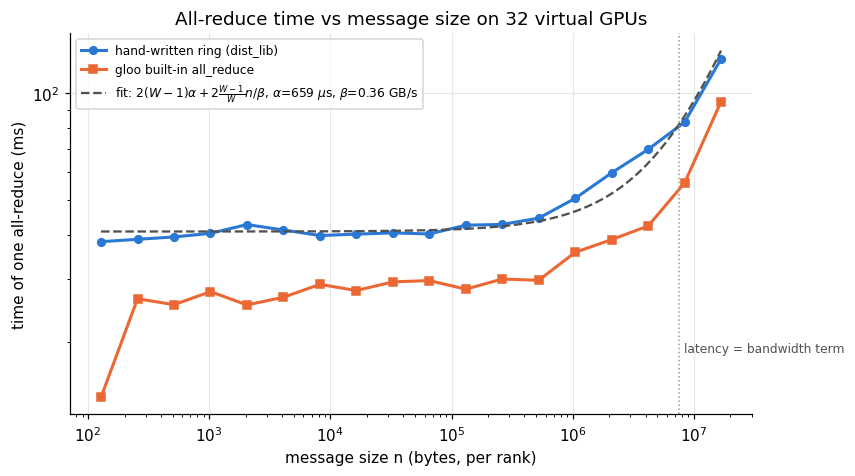

In [12]:
launch(32, "collectives_demo.py --mode bench --out runs/bench.json")
bench = json.load(open("runs/bench.json"))
Wb = bench["W"]
nb = np.array([r["bytes"] for r in bench["rows"]], float)
tr = np.array([r["ring_s"] for r in bench["rows"]])
tg = np.array([r["gloo_s"] for r in bench["rows"]])
# Least-squares fit t = a + b * n, with a = 2 (W-1) alpha and b = 2 (W-1)/W / beta. Weighted by 1/t (relative error).
A = np.stack([np.ones_like(nb), nb], 1) / tr[:, None]
a_fit, b_fit = np.linalg.lstsq(A, np.ones_like(tr), rcond=None)[0]
alpha = a_fit / (2 * (Wb - 1))
beta = 2 * (Wb - 1) / Wb / b_fit
print(f"fit of the hand ring on {Wb} ranks: t(n) = {a_fit * 1e3:.2f} ms + n / ({1 / b_fit / 1e9:.3f} GB/s)")
print(f"  latency per send  alpha = {alpha * 1e6:.1f} microseconds  (62 sends -> {a_fit * 1e3:.2f} ms for any small message)")
print(f"  bandwidth per link beta = {beta / 1e9:.2f} GB/s           (NVLink: 450 GB/s, InfiniBand: 50 GB/s)")
n_half = a_fit / b_fit
print(f"  message size where latency and bandwidth terms are equal: {n_half / 2**20:.2f} MiB")
print(f"  ring / gloo time ratio at the largest message ({nb[-1] / 2**20:.0f} MiB): {tr[-1] / tg[-1]:.2f}")
R.update(ring_alpha_us=alpha * 1e6, ring_beta_GBps=beta / 1e9, ring_half_MiB=n_half / 2**20)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(nb, tr * 1e3, "o-", color=C[0], ms=5, label="hand-written ring (dist_lib)")
ax.loglog(nb, tg * 1e3, "s-", color=C[1], ms=5, label="gloo built-in all_reduce")
nn_ = np.logspace(np.log10(nb[0]), np.log10(nb[-1]), 100)
ax.loglog(nn_, (a_fit + b_fit * nn_) * 1e3, "--", color="#52514e", lw=1.5,
          label=fr"fit: $2(W-1)\alpha + 2\frac{{W-1}}{{W}}n/\beta$, $\alpha$={alpha * 1e6:.0f} $\mu$s, $\beta$={beta / 1e9:.2f} GB/s")
ax.axvline(n_half, color="#9a9994", lw=1, ls=":")
ax.text(n_half * 1.1, ax.get_ylim()[0] * 1.5, "latency = bandwidth term", color="#52514e", fontsize=8)
ax.set_xlabel("message size n (bytes, per rank)")
ax.set_ylabel("time of one all-reduce (ms)")
ax.set_title(f"All-reduce time vs message size on {Wb} virtual GPUs")
ax.legend(fontsize=8)
savefig("ring_allreduce_time.png")

### Observations (Section 2)

* **The ring trace** reproduces the lesson's widget: after 3 reduce-scatter sends each GPU holds one complete chunk
  (GPU0: A = 10, contributions 4; GPU1: B; GPU2: C; GPU3: D), and after 3 all-gather sends every chunk on every GPU
  is 10. Six sends in total, $2(W-1)$.
* **Latency dominates almost everything here.** The fitted latency is **$\alpha = 659\ \mu$s per send**, so any
  all-reduce on 32 ranks costs at least $62 \times 0.66 = 40.9$ ms, whatever its size: the times are flat at about
  40 ms from 128 B up to about 512 KiB. Only above about 1 MiB does the bandwidth term show, and the two terms are equal
  at **7.2 MiB**. The fitted bandwidth is $\beta = 0.36$ GB/s per link.
* **Why so slow:** these are not wires but 32 processes taking turns on 12 cores. When a rank sends, its neighbour is
  often not running, so each round waits for the operating system to schedule it. On real GPUs $\alpha$ is a few
  microseconds and $\beta$ is 50 to 900 GB/s. The *shape* is what transfers: flat, then linear.
* gloo's built-in all-reduce is about 1.3 times faster than our ring at 16 MiB and has lower latency at small sizes
  (it uses a smarter algorithm for small messages). Our ring is slower but correct, and countable.
* This is the practical reason for the lesson's gradient **buckets**: with a fixed cost of 41 ms per collective,
  sending the model's 31 weight tensors one by one would cost $31 \times 41$ ms = 1.3 s of pure latency; sending 6
  unit-sized buckets costs 0.25 s.

## 3. The demo model and the data

### 3a. Data: TinyStories with a 4,096-token vocabulary

One Parquet shard of TinyStories is downloaded in bulk (no streaming, no token needed), 60,000 stories are tokenized
with GPT-2 BPE in parallel and joined into one stream with an end-of-text token after each story.

GPT-2 has 50,257 tokens, but TinyStories uses few of them. A 50k vocabulary would put 26M weights into the embedding and
head alone, five times the rest of the model, and 32 processes on 12 cores would spend most of their time on the
head. So the vocabulary is **remapped to the 4,095 most frequent tokens plus one "rare token" id**. The cell prints what
fraction of the text that keeps (prediction: above 98%, since children's stories reuse a small vocabulary).

The stream is saved as `data/tokens.npy` (uint16), and each of the 32 processes memory-maps it. A training example is
a random window of 129 tokens (128 inputs, 128 shifted targets). The global batch of step $t$ is drawn from a
generator seeded with $t$, **the same on every rank**, and rank $r$ takes sequences $[2r, 2r+2)$. So a run on 1 rank
and a run on 32 ranks see exactly the same 64 sequences at every step, which makes the equivalence tests possible.

In [13]:
import tiktoken
enc = tiktoken.get_encoding("gpt2")
EOT = enc.eot_token
N_STORIES, VOCAB = 60_000, 4096

def load_tinystories(n):
    '''First n TinyStories training texts, from one Parquet shard downloaded in bulk (cached on disk).

    Example: load_tinystories(2) -> (["One day, a little girl named Lily ...", "Once upon a time ..."], "data/train-...parquet")
    '''
    from huggingface_hub import HfApi, hf_hub_download
    import pyarrow.parquet as pq
    repo = "roneneldan/TinyStories"
    shards = sorted(f for f in HfApi().list_repo_files(repo, repo_type="dataset")
                    if f.endswith(".parquet") and "train" in f and "V2" not in f)
    path = hf_hub_download(repo, shards[0], repo_type="dataset")
    return pq.read_table(path, columns=["text"]).column("text").to_pylist()[:n], shards[0]

t0 = time.time()
texts, source = load_tinystories(N_STORIES)
ids = enc.encode_ordinary_batch(texts, num_threads=8)
stream = np.concatenate([np.asarray(s + [EOT], dtype=np.int64) for s in ids])
freq = np.bincount(stream, minlength=enc.n_vocab)                         # count of every GPT-2 id
keep = np.argsort(-freq, kind="stable")[:VOCAB - 1]                      # 4,095 most frequent GPT-2 ids
remap = np.full(enc.n_vocab, VOCAB - 1, dtype=np.int64)                  # everything else -> id 4095 ("rare")
remap[keep] = np.arange(VOCAB - 1)
tokens = remap[stream].astype(np.uint16)
np.save("data/tokens.npy", tokens)
inv = {i: int(tok) for i, tok in enumerate(keep)}
covered = freq[keep].sum() / len(stream)
print(f"source shard                       : {source}   ({time.time() - t0:.1f} s download + tokenize)")
print(f"stories / tokens in the stream     : {len(ids):,} / {len(tokens):,}   (5% held out: {int(0.05 * len(tokens)):,})")
print(f"distinct GPT-2 tokens used         : {(freq > 0).sum():,} of {enc.n_vocab:,}")
print(f"text covered by the top {VOCAB - 1:,} tokens : {covered:.2%}   (the rest becomes the single 'rare' id {VOCAB - 1})")
win = tokens[1000:1000 + 40]
print("a window decoded back through the map:", repr("".join(enc.decode([inv[int(t)]]) if t < VOCAB - 1 else "<rare>" for t in win)))
R.update(n_tokens=int(len(tokens)), vocab_coverage=covered)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

source shard                       : data/train-00000-of-00004-2d5a1467fff1081b.parquet   (21.6 s download + tokenize)
stories / tokens in the stream     : 60,000 / 13,322,817   (5% held out: 666,140)
distinct GPT-2 tokens used         : 15,941 of 50,257
text covered by the top 4,095 tokens : 98.80%   (the rest becomes the single 'rare' id 4095)
a window decoded back through the map: ' water was warm.\n\nAfter a while, it was time for Tim to go home. He said goodbye to the brown kayak and gave it a big hug. The brown kayak was sad'


### 3b. The model, and how ZeRO sees it: six units

The decoder of Assignments 10 and 11 (pre-norm, RMSNorm, rotary position embeddings, SwiGLU MLP, untied head), at
$L = 4$ layers, $D = 256$, $H = 4$ heads of 64, $F = 704$, $V = 4096$. Hand count:

$$N = \underbrace{V D}_{\text{embedding}} + L\,(\underbrace{4D^2}_{\text{attention}} + \underbrace{3DF}_{\text{MLP}} + \underbrace{2D}_{\text{norms}}) + \underbrace{D + VD}_{\text{final norm, head}}
= 1{,}048{,}576 + 4 \times 803{,}328 + 1{,}048{,}832 = 5{,}310{,}720$$

ZeRO does not handle a model as one block, nor weight by weight: it handles **units**. Here the units are the
embedding, each of the 4 blocks, and the final norm with the head. Each unit's weights are laid out as **one flat
vector**, padded with zeros to a multiple of $W$, and cut into $W$ equal slices; rank $r$ owns slice $r$ of every unit.
All three sizes are divisible by 32, so at $W = 32$ there is no padding and each rank owns
$5{,}310{,}720 / 32 = 165{,}960$ weights.

The unit is what ZeRO-2 reduces at once (the gradient "bucket") and what ZeRO-3 gathers at once. The **largest unit**
sets ZeRO-3's peak memory, because its full weights must exist on every rank while it runs: here the head unit, 1.05M
weights, 20% of the model.

**Compute per rank per step** (6 FLOP per weight per token for the matmul weights, plus attention), with 2 sequences
of 128 tokens per rank. The embedding is a table lookup, not a matmul, so it is left out:

In [14]:
import importlib, model as model_lib
importlib.reload(model_lib)
from model import Config, GPT, count_params, unit_sizes

cfg = Config()
m = GPT(cfg)
n_real = sum(p.numel() for p in m.parameters())
print(f"model                              : L={cfg.n_layer}, D={cfg.d_model}, H={cfg.n_head}, F={cfg.d_ff}, V={cfg.vocab_size}")
print(f"weights, hand formula              : {count_params(cfg):,}")
print(f"weights, counted in the model      : {n_real:,}")
print()
print(f"{'unit':10s}{'weights':>12s}{'% of model':>12s}{'padded to 32':>14s}{'slice per rank (W=32)':>24s}")
names = ["embed"] + [f"block {i}" for i in range(cfg.n_layer)] + ["norm+head"]
for nm, mod, n_hand in zip(names, m.units, unit_sizes(cfg)):
    n_u = sum(p.numel() for p in mod.parameters())
    assert n_u == n_hand
    pad = math.ceil(n_u / 32) * 32
    print(f"{nm:10s}{n_u:>12,}{n_u / n_real:>12.1%}{pad:>14,}{pad // 32:>24,}")

with torch.no_grad():
    idx = torch.from_numpy(np.load("data/tokens.npy")[:2 * 129].astype(np.int64)).view(2, 129)
    logits = m(idx[:, :-1])
    loss0 = torch.nn.functional.cross_entropy(logits.reshape(-1, cfg.vocab_size), idx[:, 1:].reshape(-1))
print(f"\nlogits shape for (B=2, T=128)      : {tuple(logits.shape)}")
print(f"initial loss                       : {loss0.item():.4f}   (prediction: ln V = ln 4096 = {math.log(4096):.4f}, the head starts near 0)")

# Analytical FLOPs per rank per step: 6 * (matmul weights) per token + attention (QK^T and AV: 2 * 2 * T * D per layer per token, x3 for training)
T_, b_ = 128, 2
n_matmul = n_real - cfg.vocab_size * cfg.d_model - (2 * cfg.n_layer + 1) * cfg.d_model    # no embedding, no norm gains
attn_fwd = cfg.n_layer * 2 * 2 * T_ * cfg.d_model
train_flop_tok = 6 * n_matmul + 3 * attn_fwd
fwd_flop_tok = 2 * n_matmul + attn_fwd
tokens_rank = b_ * T_
print(f"matmul weights                     : {n_matmul:,}")
print(f"training FLOP per token            : 6 * {n_matmul:,} + attention {3 * attn_fwd:,} = {train_flop_tok / 1e6:.1f} MFLOP")
print(f"training FLOP per rank per step    : {train_flop_tok / 1e6:.1f} M x {tokens_rank} tokens = {train_flop_tok * tokens_rank / 1e9:.2f} GFLOP")
print(f"one extra forward (recompute)      : +{fwd_flop_tok * tokens_rank / 1e9:.2f} GFLOP = +{fwd_flop_tok / train_flop_tok:.0%}")
print(f"Adam update                        : about 12 FLOP per weight it updates (2 EMAs, sqrt, divide, multiply-add)")
R.update(n_params=n_real, train_gflop_per_rank_step=train_flop_tok * tokens_rank / 1e9, recompute_extra=fwd_flop_tok / train_flop_tok)
del m

model                              : L=4, D=256, H=4, F=704, V=4096
weights, hand formula              : 5,310,720
weights, counted in the model      : 5,310,720

unit           weights  % of model  padded to 32   slice per rank (W=32)
embed        1,048,576       19.7%     1,048,576                  32,768
block 0        803,328       15.1%       803,328                  25,104
block 1        803,328       15.1%       803,328                  25,104
block 2        803,328       15.1%       803,328                  25,104
block 3        803,328       15.1%       803,328                  25,104
norm+head    1,048,832       19.7%     1,048,832                  32,776

logits shape for (B=2, T=128)      : (2, 128, 4096)
initial loss                       : 8.3205   (prediction: ln V = ln 4096 = 8.3178, the head starts near 0)
matmul weights                     : 4,259,840
training FLOP per token            : 6 * 4,259,840 + attention 1,572,864 = 27.1 MFLOP
training FLOP per rank per step 

## 4. The reference: one GPU, and the tools every stage section uses

### 4a. One GPU doing the whole batch

Data parallelism claims that averaging the gradients of 32 GPUs, each with 2 sequences, gives *exactly* the gradient
one GPU would compute on all 64 sequences:

$$\frac{1}{W}\sum_{r=1}^{W} \underbrace{\frac{1}{b}\sum_{i \in \text{rank } r} \nabla \ell_i}_{\text{rank } r\text{'s gradient}} = \frac{1}{Wb}\sum_{i=1}^{Wb} \nabla \ell_i$$

because every rank has the same $b$. If the gradients are identical, Adam (applied to identical weights) produces
identical updates, so the whole training run is identical. To test that claim, the reference run is the same engine
with $W = 1$ (all 64 sequences on one process, no communication at all), 4 steps, in **fp64** so that rounding is
$10^{-16}$ and any real bug stands out. Gradient clipping is off in the equivalence runs (Section 13 explains why it
would only add rounding-level differences).

The reference uses all CPU cores, since it is a single process.

In [15]:
EQ_ARGS = "--dtype fp64 --steps 4 --clip 0"
launch(1, f"zero_sim.py --stages ddp {EQ_ARGS} --save_weights runs/w_ref.pt --out runs/ref_fp64.json", threads=NCPU)
ref = json.load(open("runs/ref_fp64.json"))["ddp"]
ref_w = torch.load("runs/w_ref.pt")
ref_loss = [h["loss_global"] for h in ref["ranks"][0]["hist"]]
print(f"reference losses, steps 1-4        : {[round(x, 6) for x in ref_loss]}")
print(f"reference weights                  : {ref_w.numel():,} values, fp64")

world size W = 1 processes (virtual GPUs), 12 CPU thread(s) each, dtype fp64, micro-batch 64 x 128 tokens per rank, global batch 64
  [ddp] step    1  mean loss over ranks 8.3224  step time 1.544 s
  [ddp] step    2  mean loss over ranks 8.2727  step time 1.490 s
  [ddp] step    4  mean loss over ranks 7.8674  step time 1.481 s
  [ddp] finished 4 steps in 6.4 s
results written to runs/ref_fp64.json
[launch] 1 processes x 12 thread(s): 10.7 s wall time, including process start-up
reference losses, steps 1-4        : [8.322413, 8.272711, 8.097806, 7.867393]
reference weights                  : 5,310,720 values, fp64


### 4b. The measuring tools

Every stage run returns, for every rank:

* **a memory ledger** (`MemTracker`): every training-state tensor the engine allocates or frees is booked under
  *weights*, *gradients*, *fp32 master*, *Adam m* or *Adam v*. Two columns are kept: the *actual* bytes (what this
  simulation allocates; fp64 or fp32) and the *recipe* bytes (the same element counts at the lesson's 2, 2, 4, 4, 4
  bytes). The ledger records what is held **between steps** (persistent) and the **peak** inside a step (the
  transient full-size buffers ZeRO-2 and ZeRO-3 create and drop);
* **bytes sent**, counted at every send of the ring collectives and labelled by purpose (gradient all-reduce, gradient
  reduce-scatter, weight all-gather after the update, weight all-gather in forward and in backward, grad-norm);
* **the time split** of every step into forward compute, backward compute, optimizer compute and communication;
* **the activation bytes** autograd keeps between forward and backward (counted with saved-tensor hooks, weights
  excluded), and the largest single-unit recomputation;
* **the number of weights the rank's optimizer updated**.

`summarize()` turns one run into those headline numbers; `compare_to_reference()` checks the final weights and the
losses against the one-GPU reference.

In [16]:
def summarize(res, skip=1):
    '''Headline numbers of one stage run (rank 0's ledgers, which every rank shares, and rank-averaged times).

    Example: summarize(json.load(open("runs/zero2_fp64.json"))["zero2"])["persistent_recipe_per_weight"] -> about 2.44
    '''
    N, W, ranks = res["n_params"], res["W"], res["ranks"]
    r0 = ranks[0]
    P = N * res["param_bytes"]
    steps = res["steps"]
    pers_rec, pers_act = r0["mem_end"]["recipe"], r0["mem_end"]["actual"]
    s = dict(stage=res["stage"], W=W, N=N, P=P, steps=steps,
             persistent_recipe={k: pers_rec.get(k, 0) for k in CATS}, persistent_actual={k: pers_act.get(k, 0) for k in CATS},
             peak_recipe=r0["mem_peak"]["recipe"], peak_actual=r0["mem_peak"]["actual"],
             at_peak_recipe={k: r0["mem_at_peak"]["recipe"].get(k, 0) for k in CATS})
    s["persistent_recipe_total"] = sum(s["persistent_recipe"].values())
    s["persistent_actual_total"] = sum(s["persistent_actual"].values())
    s["persistent_recipe_per_weight"] = s["persistent_recipe_total"] / N
    s["persistent_actual_per_weight"] = s["persistent_actual_total"] / N
    s["peak_recipe_per_weight"] = s["peak_recipe"] / N
    # Ledgers must be identical on every rank (equal slices); check rather than assume.
    s["ledger_spread_bytes"] = max(abs(sum(r["mem_end"]["recipe"].values()) - s["persistent_recipe_total"]) for r in ranks)
    bs = r0["comm"]["bytes_sent"]
    s["comm_by_op_per_step"] = {k: v / steps for k, v in sorted(bs.items())}
    s["comm_per_step"] = sum(bs.values()) / steps
    s["comm_in_P"] = s["comm_per_step"] / P
    s["comm_spread_bytes"] = max(abs(sum(r["comm"]["bytes_sent"].values()) - sum(bs.values())) for r in ranks)
    h = r0["hist"]
    s["n_updated"] = h[-1]["n_updated"]
    s["act_bytes"] = h[-1]["act_bytes"]
    s["recompute_max_bytes"] = r0["recompute_max_bytes"]
    s["losses"] = [x["loss_global"] for x in h]
    phases = ["fwd_compute", "bwd_compute", "opt_compute", "fwd_comm", "bwd_comm", "sync_comm", "opt_comm", "total"]
    s["time"] = {p: float(np.mean([np.mean([x[p] for x in r["hist"][skip:]]) for r in ranks])) for p in phases}
    s["time"]["comm"] = sum(s["time"][p] for p in ("fwd_comm", "bwd_comm", "sync_comm", "opt_comm"))
    s["time_total_max_rank"] = float(max(np.mean([x["total"] for x in r["hist"][skip:]]) for r in ranks))
    s["replica_max_diff_end"] = res["replica_max_diff_end"]
    s["grad_copy_fallback"] = any(r["grad_copy_fallback"] for r in ranks)
    s["rss_growth_mean"] = float(np.mean([r["rss_growth"] for r in ranks]))
    return s

def print_memory(s, pred_per_weight=None):
    '''Print the per-rank memory ledger of one stage, persistent and peak, in recipe bytes (and actual).'''
    N = s["N"]
    print(f"training state held by EACH of the {s['W']} ranks between steps (recipe bytes = lesson's 2/2/4/4/4 per element):")
    for k in CATS:
        b = s["persistent_recipe"][k]
        print(f"  {k:12s}: {b / 2**20:8.3f} MiB = {b / N:6.4f} bytes per model weight   (actual in this run: {s['persistent_actual'][k] / 2**20:8.3f} MiB)")
    pw = s["persistent_recipe_per_weight"]
    line = f"  {'total':12s}: {s['persistent_recipe_total'] / 2**20:8.3f} MiB = {pw:6.4f} bytes per model weight"
    if pred_per_weight is not None:
        line += f"   (hand prediction {pred_per_weight:.4f}; ratio measured/predicted {pw / pred_per_weight:.4f})"
    print(line)
    print(f"  peak inside a step: {s['peak_recipe'] / 2**20:.3f} MiB = {s['peak_recipe_per_weight']:.4f} bytes/weight"
          f"  (split at the peak: " + ", ".join(f"{k} {v / 2**20:.2f}" for k, v in s["at_peak_recipe"].items() if v) + " MiB)")
    print(f"  ledgers identical on all ranks   : {s['ledger_spread_bytes'] == 0}")

def print_comm(s, pred_in_P=None):
    '''Print the bytes each rank sent per training step, by purpose, and the total as a multiple of P.'''
    print(f"bytes sent per rank per step (P = one copy of the weights = {s['N']:,} x {s['P'] // s['N']} B = {s['P'] / 2**20:.2f} MiB):")
    for op, b in s["comm_by_op_per_step"].items():
        print(f"  {op:36s}: {b / 2**20:9.4f} MiB = {b / s['P']:.4f} P")
    line = f"  {'total':36s}: {s['comm_per_step'] / 2**20:9.4f} MiB = {s['comm_in_P']:.4f} P"
    if pred_in_P is not None:
        line += f"   (hand prediction {pred_in_P:.4f} P)"
    print(line)
    print(f"  every rank sent the same bytes    : {s['comm_spread_bytes'] == 0}")

def compare_to_reference(s, res):
    '''Final fp64 weights and per-step losses of a stage run vs the one-GPU reference.'''
    w = torch.load(res["weights_file"])
    d = (w - ref_w).abs()
    rel = (d / ref_w.abs().clamp_min(1e-3)).max().item()
    dl = max(abs(a - b) for a, b in zip(s["losses"], ref_loss))
    print(f"after {s['steps']} steps vs one GPU on the same 64 sequences (fp64):")
    print(f"  max |w_stage - w_one_GPU| over {w.numel():,} weights : {d.max().item():.3e}   (largest relative difference {rel:.3e})")
    print(f"  max |loss_stage - loss_one_GPU| over the steps   : {dl:.3e}")
    print(f"  weights changed by training (max |w_4 - w_0|)    : {(ref_w - w0_init).abs().max().item():.3e}  (so the differences above are tiny next to real updates)")
    if s["replica_max_diff_end"] is not None:
        print(f"  max difference between the 32 ranks' copies      : {s['replica_max_diff_end']:.3e}  (prediction 0: every replica applied the same update)")
    return d.max().item()

torch.manual_seed(0)
w0_init = torch.cat([p.detach().reshape(-1).double() for p in GPT(cfg).parameters()])   # initial weights, same seed as the runs
STAGE_RUNS = {}

## 5. Data parallelism (DDP), the baseline

### 5a. What every rank holds and does

Every rank holds **everything**: the full bf16 weights, the full bf16 gradients, the full fp32 master copy and the full
Adam $m$ and $v$. Each step:

1. forward and backward on its own 2 sequences (different from every other rank's);
2. **all-reduce** every unit's gradient (ring: reduce-scatter + all-gather), divide by $W$: now every rank has the
   gradient of all 64 sequences;
3. every rank runs Adam on **all** $N$ weights, the same computation on the same numbers 32 times over.

| per rank, $W = 32$ | elements | recipe bytes | |
|---|---|---|---|
| weights (bf16) | $N$ | $2N$ | replicated |
| gradients (bf16) | $N$ | $2N$ | replicated |
| master, $m$, $v$ (fp32) | $3N$ | $12N$ | replicated |
| **total** | | $16N$ = 81.04 MiB | 32 identical copies: 2,593 MiB to store 81 MiB of information |

### 5b. Hand predictions, before the run

* **Memory:** $16.0000$ bytes per weight, $16 \times 5{,}310{,}720 = 84{,}971{,}520$ B $= 81.04$ MiB per rank; no transient
  buffers, so peak = persistent.
* **Communication:** one ring all-reduce of every gradient per step: $2 \cdot \frac{31}{32} = 1.9375\,P$ per rank,
  with $P = N \times 8$ B $= 40.5$ MiB in this fp64 run.
* **Optimizer:** each rank updates all 5,310,720 weights (100%).
* **Equivalence:** the same weights as the one-GPU reference up to fp64 rounding (about $10^{-17}$ to $10^{-15}$; the
  sum of 64 per-sequence gradients is done in a different order), and all 32 replicas bit-identical (difference 0).

In [17]:
launch(32, "zero_sim.py --stages ddp {EQ_ARGS} --save_weights runs/w_ddp.pt --out runs/ddp_fp64.json".format(EQ_ARGS=EQ_ARGS))
res = json.load(open("runs/ddp_fp64.json"))["ddp"]
s = summarize(res)
STAGE_RUNS["ddp"] = (s, res)
print()
print_memory(s, pred_per_weight=16.0)
print()
print_comm(s, pred_in_P=1.9375)
print()
print(f"weights updated by each rank's optimizer : {s['n_updated']:,} of {s['N']:,} ({s['n_updated'] / s['N']:.4%})")
print(f"activations kept for backward (rank 0)   : {s['act_bytes'] / 2**20:.2f} MiB (fp64)" +
      (f";  largest single-unit recompute {s['recompute_max_bytes'] / 2**20:.2f} MiB" if s['recompute_max_bytes'] else ""))
if s["grad_copy_fallback"]:
    print("note: this PyTorch allocated fresh .grad tensors, so gradients were copied into the flat buffer (still correct)")
print()
R["eq_maxdiff_ddp"] = compare_to_reference(s, res)
R["mem_persistent_per_weight_ddp"] = s["persistent_recipe_per_weight"]
R["mem_peak_per_weight_ddp"] = s["peak_recipe_per_weight"]
R["comm_in_P_ddp"] = s["comm_in_P"]
R["n_updated_ddp"] = s["n_updated"]

world size W = 32 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp64, micro-batch 2 x 128 tokens per rank, global batch 64
  [ddp] step    1  mean loss over ranks 8.3224  step time 2.372 s
  [ddp] step    2  mean loss over ranks 8.2727  step time 2.265 s
  [ddp] step    4  mean loss over ranks 7.8674  step time 1.930 s
  [ddp] finished 4 steps in 12.0 s
results written to runs/ddp_fp64.json
[launch] 32 processes x 1 thread(s): 23.4 s wall time, including process start-up

training state held by EACH of the 32 ranks between steps (recipe bytes = lesson's 2/2/4/4/4 per element):
  weights     :   10.129 MiB = 2.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  gradients   :   10.129 MiB = 2.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  fp32 master :   20.259 MiB = 4.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  Adam m      :   20.259 MiB = 4.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  Adam v      : 

### Observations (Section 5)

* **Memory: exactly 16.0000 bytes per weight**, 81.035 MiB per rank (2 + 2 + 4 + 4 + 4), identical on all 32 ranks,
  and the peak equals the persistent state (DDP never creates temporary full-size buffers). 32 ranks hold
  $32 \times 81$ = 2,593 MiB to store 81 MiB of information.
* **Communication: 1.9375 P per step**, exactly the prediction ($P$ = 40.52 MiB in fp64, so 78.5 MiB sent per rank).
* **Optimizer: every rank updated all 5,310,720 weights** (100%), the same arithmetic 32 times over.
* **Equivalence:** after 4 steps the weights differ from the one-GPU run by at most $1.3\times10^{-14}$, while
  training moved them by up to $3.0\times10^{-3}$; the losses agree to $3.6\times10^{-15}$. The 32 replicas are
  **bit-identical** (difference 0.000). The prediction ($10^{-17}$ to $10^{-15}$ absolute) was slightly optimistic:
  the largest difference sits on a small weight (relative difference $1.3\times10^{-11}$), probably one where Adam
  divides a tiny $m$ by a tiny $\sqrt{v}$ and so magnifies rounding; but $1.3\times10^{-14}$ is still 11 orders of magnitude below the size of the updates.
* Activations kept for backward: 57.7 MiB per rank in fp64 for 2 sequences of 128 tokens (29.0 MiB in fp32,
  Section 9), as large as 70% of the training state. ZeRO does not touch this number (Section 9).

## 6. ZeRO-1: shard the optimizer state

### 6a. The idea

In DDP every rank runs the same Adam update on the same numbers. ZeRO-1 gives rank $r$ the job of updating only
**slice $r$** of the weights, so it needs the fp32 master copy and Adam $m$, $v$ only for that slice: 12 of the 16
bytes drop to $12/W$. The weights and gradients stay full on every rank, since forward and backward need them.

Each step:

1. forward and backward on its own sequences: full gradient on every rank, as in DDP;
2. **reduce-scatter** the gradients: rank $r$ receives the sum over ranks of slice $r$ only;
3. Adam on slice $r$ (1/32 of the weights), writing new bf16 weights into slice $r$ of the full weight copy;
4. **all-gather** the weights: every rank receives everyone's new slice, so the replicas are identical again.

**Why it costs no extra communication:** the ring all-reduce in DDP *is* a reduce-scatter followed by an all-gather
(Section 2). ZeRO-1 does the same two phases, but on different things: the reduce-scatter on the gradients (as in
DDP), and the all-gather on the *updated weights* instead of the summed gradients. Both are $N$ elements of the
same format, so the bytes are the same.

| per rank, $W = 32$ | elements | recipe bytes per weight |
|---|---|---|
| weights (bf16), full | $N$ | 2 |
| gradients (bf16), full | $N$ | 2 |
| master, $m$, $v$ (fp32), slice | $3N/32$ | $12/32 = 0.375$ |
| **total** | | **4.375** |

### 6b. Hand predictions, before the run

* **Memory:** $4 + 12/32 = 4.3750$ bytes per weight $= 22.16$ MiB per rank (3.7 times less than DDP), peak = persistent.
* **Communication:** reduce-scatter of gradients $\frac{31}{32}P$ + all-gather of weights $\frac{31}{32}P$ = $1.9375\,P$,
  the same as DDP, plus a 496-byte all-reduce of the squared gradient norm (each rank only has its slice of the
  gradient, so the global norm needs one number from each rank; $2 \times 31 \times 8$ B).
* **Optimizer:** each rank updates $165{,}960$ weights, 1/32 = 3.125% of the model: the optimizer's work per rank
  falls 32 times.
* **Equivalence:** the same as DDP, and in fact **bit-identical to DDP** (same ring, same chunks, same sums, same Adam
  arithmetic per element).

In [18]:
launch(32, "zero_sim.py --stages zero1 {EQ_ARGS} --save_weights runs/w_zero1.pt --out runs/zero1_fp64.json".format(EQ_ARGS=EQ_ARGS))
res = json.load(open("runs/zero1_fp64.json"))["zero1"]
s = summarize(res)
STAGE_RUNS["zero1"] = (s, res)
print()
print_memory(s, pred_per_weight=4.375)
print()
print_comm(s, pred_in_P=1.9375)
print()
print(f"weights updated by each rank's optimizer : {s['n_updated']:,} of {s['N']:,} ({s['n_updated'] / s['N']:.4%})")
print(f"activations kept for backward (rank 0)   : {s['act_bytes'] / 2**20:.2f} MiB (fp64)" +
      (f";  largest single-unit recompute {s['recompute_max_bytes'] / 2**20:.2f} MiB" if s['recompute_max_bytes'] else ""))
if s["grad_copy_fallback"]:
    print("note: this PyTorch allocated fresh .grad tensors, so gradients were copied into the flat buffer (still correct)")
print()
R["eq_maxdiff_zero1"] = compare_to_reference(s, res)
R["mem_persistent_per_weight_zero1"] = s["persistent_recipe_per_weight"]
R["mem_peak_per_weight_zero1"] = s["peak_recipe_per_weight"]
R["comm_in_P_zero1"] = s["comm_in_P"]
R["n_updated_zero1"] = s["n_updated"]

world size W = 32 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp64, micro-batch 2 x 128 tokens per rank, global batch 64
  [zero1] step    1  mean loss over ranks 8.3224  step time 1.817 s
  [zero1] step    2  mean loss over ranks 8.2727  step time 1.755 s
  [zero1] step    4  mean loss over ranks 7.8674  step time 1.697 s
  [zero1] finished 4 steps in 9.7 s
results written to runs/zero1_fp64.json
[launch] 32 processes x 1 thread(s): 21.2 s wall time, including process start-up

training state held by EACH of the 32 ranks between steps (recipe bytes = lesson's 2/2/4/4/4 per element):
  weights     :   10.129 MiB = 2.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  gradients   :   10.129 MiB = 2.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  fp32 master :    0.633 MiB = 0.1250 bytes per model weight   (actual in this run:    1.266 MiB)
  Adam m      :    0.633 MiB = 0.1250 bytes per model weight   (actual in this run:    1.266 MiB)
  Adam 

### Observations (Section 6)

* **Memory: exactly 4.3750 bytes per weight** (22.16 MiB per rank, 3.7 times less than DDP). The split shows what
  happened: weights and gradients unchanged at 2.0 bytes each, master, $m$ and $v$ down from 4.0 to **0.125** each
  ($= 4/32$).
* **Communication: 1.9375 P**, the same as DDP to 4 decimals, now split into a gradient reduce-scatter
  (0.9688 P) and a weight all-gather (0.9688 P). The only addition is 496 bytes for the gradient-norm all-reduce
  (shown as 0.0005 MiB). **Sharding the optimizer state is free in communication**, as the lesson says.
* **Optimizer work per rank: 165,960 weights, 3.125%** of the model, 32 times less.
* **Equivalence:** the same $1.3\times10^{-14}$ from the one-GPU run, replicas identical, and (Section 8c) bit-identical
  to DDP.

## 7. ZeRO-2: shard the gradients too

### 7a. The idea

After the reduce-scatter, rank $r$ only ever *uses* slice $r$ of the gradient. ZeRO-1 still keeps the full gradient
around; ZeRO-2 does not. The trick is timing: backward produces gradients unit by unit, from the head back to the
embedding. As soon as one unit's gradients are complete:

1. copy them into a temporary full-size buffer for that unit;
2. **reduce-scatter** that buffer right away (inside backward), adding slice $r$ into a persistent $1/W$ gradient slice;
3. **drop the buffer.**

So at any moment the rank holds its $1/W$ gradient slices plus at most one unit's full gradient, not the whole
model's. In the code this is a `register_post_accumulate_grad_hook` on every weight: when the last weight of a unit
has its gradient, the hook sends the unit and frees it. After backward, the optimizer step and the weight all-gather
are the same as ZeRO-1.

| per rank, $W = 32$ | elements | recipe bytes per weight |
|---|---|---|
| weights (bf16), full | $N$ | 2 |
| gradients (bf16), slice | $N/32$ | $2/32 = 0.0625$ |
| master, $m$, $v$ (fp32), slice | $3N/32$ | $0.375$ |
| **total between steps** | | **2.4375** |
| + inside backward: one unit's full gradient, plus autograd's copy of its largest tensor | up to $2 \times 1.05$M | about $+0.79$ at the peak |

### 7b. Hand predictions, before the run

* **Memory between steps:** $2 + 14/32 = 2.4375$ bytes per weight $= 12.35$ MiB per rank.
* **Peak:** larger than that, because a full unit gradient exists for a moment. The largest unit (head, 1,048,832
  weights) adds a 2.00 MiB buffer plus autograd's own 2.00 MiB gradient for the head matrix before it is copied, so
  about $12.35 + 4.0 = 16.35$ MiB ($\approx 3.23$ bytes per weight). **The unit size, not the model size, sets this
  extra.** This is why DeepSpeed's bucket size and FSDP's wrapping granularity are tuning knobs.
* **Communication:** the same $1.9375\,P$ (+496 B for the norm): the reduce-scatter is just moved into backward.
* **Optimizer:** 165,960 weights per rank, as ZeRO-1.
* **Equivalence:** bit-identical to DDP and ZeRO-1.

In [19]:
launch(32, "zero_sim.py --stages zero2 {EQ_ARGS} --save_weights runs/w_zero2.pt --out runs/zero2_fp64.json".format(EQ_ARGS=EQ_ARGS))
res = json.load(open("runs/zero2_fp64.json"))["zero2"]
s = summarize(res)
STAGE_RUNS["zero2"] = (s, res)
print()
print_memory(s, pred_per_weight=2.4375)
print()
print_comm(s, pred_in_P=1.9375)
print()
print(f"weights updated by each rank's optimizer : {s['n_updated']:,} of {s['N']:,} ({s['n_updated'] / s['N']:.4%})")
print(f"activations kept for backward (rank 0)   : {s['act_bytes'] / 2**20:.2f} MiB (fp64)" +
      (f";  largest single-unit recompute {s['recompute_max_bytes'] / 2**20:.2f} MiB" if s['recompute_max_bytes'] else ""))
if s["grad_copy_fallback"]:
    print("note: this PyTorch allocated fresh .grad tensors, so gradients were copied into the flat buffer (still correct)")
print()
R["eq_maxdiff_zero2"] = compare_to_reference(s, res)
R["mem_persistent_per_weight_zero2"] = s["persistent_recipe_per_weight"]
R["mem_peak_per_weight_zero2"] = s["peak_recipe_per_weight"]
R["comm_in_P_zero2"] = s["comm_in_P"]
R["n_updated_zero2"] = s["n_updated"]

world size W = 32 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp64, micro-batch 2 x 128 tokens per rank, global batch 64
  [zero2] step    1  mean loss over ranks 8.3224  step time 1.858 s
  [zero2] step    2  mean loss over ranks 8.2727  step time 1.884 s
  [zero2] step    4  mean loss over ranks 7.8674  step time 1.787 s
  [zero2] finished 4 steps in 9.8 s
results written to runs/zero2_fp64.json
[launch] 32 processes x 1 thread(s): 21.5 s wall time, including process start-up

training state held by EACH of the 32 ranks between steps (recipe bytes = lesson's 2/2/4/4/4 per element):
  weights     :   10.129 MiB = 2.0000 bytes per model weight   (actual in this run:   40.518 MiB)
  gradients   :    0.317 MiB = 0.0625 bytes per model weight   (actual in this run:    1.266 MiB)
  fp32 master :    0.633 MiB = 0.1250 bytes per model weight   (actual in this run:    1.266 MiB)
  Adam m      :    0.633 MiB = 0.1250 bytes per model weight   (actual in this run:    1.266 MiB)
  Adam 

### Observations (Section 7)

* **Memory between steps: exactly 2.4375 bytes per weight** (12.35 MiB): the gradient line fell from 2.0 to
  **0.0625** bytes per weight ($2/32$).
* **Peak: 16.35 MiB = 3.23 bytes per weight**, exactly as predicted (12.35 + one head-unit gradient buffer 2.00 MiB +
  autograd's own 2.00 MiB copy of the head matrix gradient). At the peak the gradient line holds 4.32 MiB, not
  0.32 MiB. **The between-steps number understates ZeRO-2's real need by a third at this scale**, and what sets the
  difference is the size of the largest unit, not the model.
* **Communication: 1.9375 P**, identical to ZeRO-1. The reduce-scatter has only moved from after backward into
  backward. **ZeRO-2 is also free in communication.**
* **Equivalence:** $1.3\times10^{-14}$ from one GPU, bit-identical to DDP and ZeRO-1.

## 8. ZeRO-3: shard the weights too

### 8a. The idea

The last replicated thing is the weights. Under ZeRO-3 rank $r$ stores only slice $r$ of every unit's weights, so all
16 bytes are divided by $W$. A unit's full weights exist only while that unit is computing:

* **forward**, for each unit: **all-gather** its weights from the 32 slices, run it, drop the full weights;
* **backward**, for each unit, last to first: **all-gather** its weights *again* (they were dropped), compute its
  gradients, **reduce-scatter** them (as ZeRO-2), drop the weights and the full gradient;
* **optimizer:** Adam on slice $r$ writes the new weights straight into the slice. No all-gather after the update:
  the next forward gathers them anyway.

**Communication:** two weight all-gathers (forward and backward) + one gradient reduce-scatter
$= 3 \cdot \frac{31}{32} P = 2.906\,P$: 1.5 times DDP. That is the lesson's "3P".

**How the "drop and gather again" is implemented here.** If autograd kept the normal graph of a unit, the graph would
hold references to the gathered weights and they could never be freed between forward and backward. `UnitFn` (in
`zero_sim.py`) is a custom autograd function that runs each unit **without** recording its graph and saves only the
unit's input; in backward it gathers the weights again and **recomputes** the unit's forward with autograd on, then
backpropagates through it. That recomputation is **activation checkpointing**: it costs one extra forward per step
(+33% compute here, from Section 3b) and it also shrinks the activations to one tensor per unit. PyTorch FSDP gets the
same weight behaviour without recomputing, by freeing the storage under the graph and refilling it in a backward hook.
So the extra compute seen in this section is a property of this implementation, and Section 9 separates it from ZeRO
itself by running the other stages with the same checkpointing.

| per rank, $W = 32$ | elements | recipe bytes per weight |
|---|---|---|
| weights (bf16), slice | $N/32$ | 0.0625 |
| gradients (bf16), slice | $N/32$ | 0.0625 |
| master, $m$, $v$ (fp32), slice | $3N/32$ | 0.375 |
| **total between steps** | | **0.5** |
| + inside a step: one unit's full weights + its full gradient | up to $2 \times 1.05$M | about $+0.79$ at the peak |

### 8b. Hand predictions, before the run

* **Memory between steps:** $16/32 = 0.5000$ bytes per weight $= 2.53$ MiB per rank, **32 times less than DDP**.
* **Peak:** during the head unit's backward: its full weights (2.00 MiB) and its full gradient (2.00 MiB) on top of the
  slices, about $2.53 + 4.0 = 6.5$ MiB ($\approx 1.29$ bytes per weight). The fixed per-unit term dominates at this
  scale: with 32 GPUs, **the largest unit is 2.5 times the whole sharded state**. This is the real limit on ZeRO-3:
  the biggest unit must fit, whatever $W$ is.
* **Communication:** $3 \times \frac{31}{32} = 2.9063\,P$ + the 496-byte norm all-reduce.
* **Activations:** only one input tensor per unit is kept (6 tensors), instead of every intermediate result.
* **Equivalence:** the same weights as one GPU; most likely bit-identical to DDP (the recomputed forward does the same
  arithmetic in the same order), which the next cell checks directly.

In [20]:
launch(32, "zero_sim.py --stages zero3 {EQ_ARGS} --save_weights runs/w_zero3.pt --out runs/zero3_fp64.json".format(EQ_ARGS=EQ_ARGS))
res = json.load(open("runs/zero3_fp64.json"))["zero3"]
s = summarize(res)
STAGE_RUNS["zero3"] = (s, res)
print()
print_memory(s, pred_per_weight=0.5)
print()
print_comm(s, pred_in_P=2.90625)
print()
print(f"weights updated by each rank's optimizer : {s['n_updated']:,} of {s['N']:,} ({s['n_updated'] / s['N']:.4%})")
print(f"activations kept for backward (rank 0)   : {s['act_bytes'] / 2**20:.2f} MiB (fp64)" +
      (f";  largest single-unit recompute {s['recompute_max_bytes'] / 2**20:.2f} MiB" if s['recompute_max_bytes'] else ""))
if s["grad_copy_fallback"]:
    print("note: this PyTorch allocated fresh .grad tensors, so gradients were copied into the flat buffer (still correct)")
print()
R["eq_maxdiff_zero3"] = compare_to_reference(s, res)
R["mem_persistent_per_weight_zero3"] = s["persistent_recipe_per_weight"]
R["mem_peak_per_weight_zero3"] = s["peak_recipe_per_weight"]
R["comm_in_P_zero3"] = s["comm_in_P"]
R["n_updated_zero3"] = s["n_updated"]

world size W = 32 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp64, micro-batch 2 x 128 tokens per rank, global batch 64
  [zero3] step    1  mean loss over ranks 8.3224  step time 8.387 s
  [zero3] step    2  mean loss over ranks 8.2727  step time 2.404 s
  [zero3] step    4  mean loss over ranks 7.8674  step time 2.443 s
  [zero3] finished 4 steps in 17.7 s
results written to runs/zero3_fp64.json
[launch] 32 processes x 1 thread(s): 29.8 s wall time, including process start-up

training state held by EACH of the 32 ranks between steps (recipe bytes = lesson's 2/2/4/4/4 per element):
  weights     :    0.317 MiB = 0.0625 bytes per model weight   (actual in this run:    1.266 MiB)
  gradients   :    0.317 MiB = 0.0625 bytes per model weight   (actual in this run:    1.266 MiB)
  fp32 master :    0.633 MiB = 0.1250 bytes per model weight   (actual in this run:    1.266 MiB)
  Adam m      :    0.633 MiB = 0.1250 bytes per model weight   (actual in this run:    1.266 MiB)
  Adam

### Observations (Section 8)

* **Memory between steps: exactly 0.5000 bytes per weight** (2.53 MiB per rank), 32 times less than DDP; every
  category is now divided by 32.
* **Peak: 6.53 MiB = 1.29 bytes per weight**, as predicted: one unit's gathered weights and its full gradient
  (2.32 MiB each at the peak, including the slices) on top of the slices. **The temporary unit costs 1.6 times the
  entire sharded state.** With 32 GPUs and only 6 units, the per-unit term dominates; for a 30B model with 60 layers it
  would be small (Section 14).
* **Communication: 2.9063 P**, the lesson's 3P made exact ($3 \times 31/32$): all-gather in forward, all-gather in
  backward, reduce-scatter of gradients, 0.9688 P each.
* **Activations:** 10.5 MiB kept across the step (one input per unit) instead of 57.7 MiB in DDP, and at most
  12.1 MiB alive during one unit's recomputation. That 5.5 times saving comes from the recomputation, not from ZeRO
  (Section 9 shows DDP gets the same with checkpointing).
* **Time:** step 1 took 8.4 s against 2.4 s for later steps (first-time allocation of the gather buffers and first use
  of every socket pair); every later timing excludes step 1.
* **Equivalence:** $1.3\times10^{-14}$ from one GPU. The replica check does not apply: under ZeRO-3 no rank holds a
  full copy.

### 8c. All four stages against each other, bit by bit

The stage sections each compared one stage with the one-GPU reference. Here the four final weight vectors and the four
loss histories are compared **with each other**. The prediction: differences of exactly 0 between DDP, ZeRO-1, ZeRO-2
and ZeRO-3, and a rounding-level difference between any of them and the one-GPU run (different batching inside the
matrix multiplications).

In [21]:
wts = {st: torch.load(STAGE_RUNS[st][1]["weights_file"]) for st in STAGES}
print("max |w_a - w_b| after 4 fp64 steps (rows a, columns b); 'ref' = one GPU, all 64 sequences:")
cols = ["ref"] + STAGES
allw = {"ref": ref_w, **wts}
print(f"{'':8s}" + "".join(f"{c:>12s}" for c in cols))
for a_ in cols:
    print(f"{a_:8s}" + "".join(f"{(allw[a_] - allw[b_]).abs().max().item():12.2e}" for b_ in cols))
loss_tab = {st: STAGE_RUNS[st][0]["losses"] for st in STAGES}
print("\nlosses per step (mean over the 64 sequences):")
for i in range(len(ref_loss)):
    print(f"  step {i + 1}: one GPU {ref_loss[i]:.12f}  " + "  ".join(f"{st} {loss_tab[st][i]:.12f}" for st in STAGES))
R["bitwise_equal_stages"] = all((wts[a_] - wts["ddp"]).abs().max().item() == 0 for a_ in STAGES)

max |w_a - w_b| after 4 fp64 steps (rows a, columns b); 'ref' = one GPU, all 64 sequences:
                 ref         ddp       zero1       zero2       zero3
ref         0.00e+00    1.32e-14    1.32e-14    1.32e-14    1.32e-14
ddp         1.32e-14    0.00e+00    0.00e+00    0.00e+00    0.00e+00
zero1       1.32e-14    0.00e+00    0.00e+00    0.00e+00    0.00e+00
zero2       1.32e-14    0.00e+00    0.00e+00    0.00e+00    0.00e+00
zero3       1.32e-14    0.00e+00    0.00e+00    0.00e+00    0.00e+00

losses per step (mean over the 64 sequences):
  step 1: one GPU 8.322412627876  ddp 8.322412627876  zero1 8.322412627876  zero2 8.322412627876  zero3 8.322412627876
  step 2: one GPU 8.272711438952  ddp 8.272711438952  zero1 8.272711438952  zero2 8.272711438952  zero3 8.272711438952
  step 3: one GPU 8.097806061566  ddp 8.097806061566  zero1 8.097806061566  zero2 8.097806061566  zero3 8.097806061566
  step 4: one GPU 7.867392934161  ddp 7.867392934161  zero1 7.867392934161  zero2 7.8673929

### Observations (Section 8c)

* **All four stages produced bit-identical weights** (every off-diagonal entry between DDP, ZeRO-1, ZeRO-2 and ZeRO-3 is
  exactly 0.00) and the same loss to all 12 printed digits at every step. The prediction held, including the hedged
  one for ZeRO-3: recomputing a unit in backward does exactly the same arithmetic in the same order as the forward pass
  did.
* All four differ from the one-GPU run by the same $1.32\times10^{-14}$: the difference comes from batching (one
  matrix multiply over 64 sequences vs 32 over 2, then a ring sum), not from ZeRO.
* So **ZeRO changes where the numbers are stored and who computes which update, never what is computed.** A ZeRO stage
  can be switched without changing a training recipe, which is what lets V4's ZeRO-2 configuration move to ZeRO-3 for V5.

## 9. Side by side: memory, communication and computation of the four stages

### 9a. What is measured

Two fp32 runs on 32 ranks, 8 steps each, all four stages in one launch (the first step is excluded from the timings,
because it includes one-off allocation):

1. **as implemented**: DDP, ZeRO-1, ZeRO-2 with normal autograd; ZeRO-3 with its recomputation;
2. **all with activation checkpointing**: the same, but DDP, ZeRO-1 and ZeRO-2 also recompute each unit in backward.
   This makes the compute per step identical for all four, so what remains between them is **only ZeRO**.

**Hand predictions for the computation.**

* **Forward and backward compute per rank is the same in every stage.** ZeRO splits *memory*, not *work*: every rank
  still runs the whole model on its own 2 sequences ($\approx$ 6.9 GFLOP from Section 3b). Only checkpointing adds
  work (+33%).
* **Optimizer compute per rank falls 32 times** from DDP to any ZeRO stage (5.3M → 166k weights updated).
* **Communication time:** about equal for DDP, ZeRO-1, ZeRO-2 (same bytes, $1.94P$), about 1.5 times that for ZeRO-3
  ($2.91P$), plus extra latency for ZeRO-3: it runs 18 collectives per step (6 units × 3) against 6 or 12.

On 12 cores with 32 processes, a rank waiting for a message often waits for a slower rank to get a core; that waiting
is booked as communication. The bytes are exact; the seconds are only relative.

In [22]:
launch(32, "zero_sim.py --stages ddp,zero1,zero2,zero3 --dtype fp32 --steps 8 --out runs/cmp_fp32.json")
launch(32, "zero_sim.py --stages ddp,zero1,zero2,zero3 --dtype fp32 --steps 8 --ckpt --out runs/cmp_fp32_ckpt.json")
cmp_ = {k: {st: summarize(v[st]) for st in STAGES} for k, v in
        (("plain", json.load(open("runs/cmp_fp32.json"))), ("ckpt", json.load(open("runs/cmp_fp32_ckpt.json"))))}

for mode, title in (("plain", "as implemented (ZeRO-3 recomputes, the others do not)"), ("ckpt", "all four with activation checkpointing")):
    print(f"\n=== {title}: per rank, mean over steps 2-8 and over the 32 ranks ===")
    print(f"{'stage':18s}{'state MiB':>10s}{'peak MiB':>10s}{'act MiB':>9s}{'sent P':>8s}{'opt elems':>11s}"
          f"{'fwd ms':>8s}{'bwd ms':>8s}{'opt ms':>8s}{'comm ms':>9s}{'step ms':>9s}")
    for st in STAGES:
        s = cmp_[mode][st]; t = s["time"]
        print(f"{STAGE_NAME[st]:18s}{s['persistent_recipe_total'] / 2**20:>10.2f}{s['peak_recipe'] / 2**20:>10.2f}"
              f"{s['act_bytes'] / 2**20:>9.2f}{s['comm_in_P']:>8.4f}{s['n_updated']:>11,}"
              f"{t['fwd_compute'] * 1e3:>8.1f}{t['bwd_compute'] * 1e3:>8.1f}{t['opt_compute'] * 1e3:>8.2f}"
              f"{t['comm'] * 1e3:>9.1f}{t['total'] * 1e3:>9.1f}")
print("\n(state, peak: lesson recipe bytes; act: activations autograd keeps, fp32; sent P: bytes sent per step / P;"
      " opt elems: weights each rank's Adam updates)")
p, c_ = cmp_["plain"], cmp_["ckpt"]
print(f"\noptimizer time per rank, DDP / ZeRO-1          : {p['ddp']['time']['opt_compute'] / p['zero1']['time']['opt_compute']:.1f} x"
      f"   (elements ratio {p['ddp']['n_updated'] / p['zero1']['n_updated']:.0f} x)")
print(f"forward+backward compute, ZeRO-3 / DDP (plain)  : {(p['zero3']['time']['fwd_compute'] + p['zero3']['time']['bwd_compute']) / (p['ddp']['time']['fwd_compute'] + p['ddp']['time']['bwd_compute']):.2f} x")
print(f"forward+backward compute, ZeRO-3 / DDP (both checkpointed): {(c_['zero3']['time']['fwd_compute'] + c_['zero3']['time']['bwd_compute']) / (c_['ddp']['time']['fwd_compute'] + c_['ddp']['time']['bwd_compute']):.2f} x")
print(f"communication time, ZeRO-3 / DDP (checkpointed) : {c_['zero3']['time']['comm'] / c_['ddp']['time']['comm']:.2f} x   (bytes ratio {c_['zero3']['comm_in_P'] / c_['ddp']['comm_in_P']:.2f} x)")
print(f"process RSS growth per rank, DDP vs ZeRO-3      : {p['ddp']['rss_growth_mean'] / 2**20:.1f} MiB vs {p['zero3']['rss_growth_mean'] / 2**20:.1f} MiB"
      "   (operating-system view, noisy; the ledger above is exact)")
for st in STAGES:
    R[f"cmp_{st}"] = dict(state_MiB=p[st]["persistent_recipe_total"] / 2**20, peak_MiB=p[st]["peak_recipe"] / 2**20,
                          act_MiB=p[st]["act_bytes"] / 2**20, comm_P=p[st]["comm_in_P"],
                          time_ms={k: v * 1e3 for k, v in p[st]["time"].items()},
                          time_ckpt_ms={k: v * 1e3 for k, v in c_[st]["time"].items()}, act_ckpt_MiB=c_[st]["act_bytes"] / 2**20)

world size W = 32 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp32, micro-batch 2 x 128 tokens per rank, global batch 64
  [ddp] step    1  mean loss over ranks 8.3224  step time 1.390 s
  [ddp] step    2  mean loss over ranks 8.2727  step time 1.389 s
  [ddp] step    8  mean loss over ranks 6.5337  step time 1.321 s
  [ddp] finished 8 steps in 13.4 s
  [zero1] step    1  mean loss over ranks 8.3224  step time 0.983 s
  [zero1] step    2  mean loss over ranks 8.2727  step time 1.008 s
  [zero1] step    8  mean loss over ranks 6.5337  step time 0.972 s
  [zero1] finished 8 steps in 9.8 s
  [zero2] step    1  mean loss over ranks 8.3224  step time 1.009 s
  [zero2] step    2  mean loss over ranks 8.2727  step time 1.038 s
  [zero2] step    8  mean loss over ranks 6.5337  step time 1.018 s
  [zero2] finished 8 steps in 10.1 s
  [zero3] step    1  mean loss over ranks 8.3224  step time 2.874 s
  [zero3] step    2  mean loss over ranks 8.2727  step time 1.433 s
  [zero3] step    8

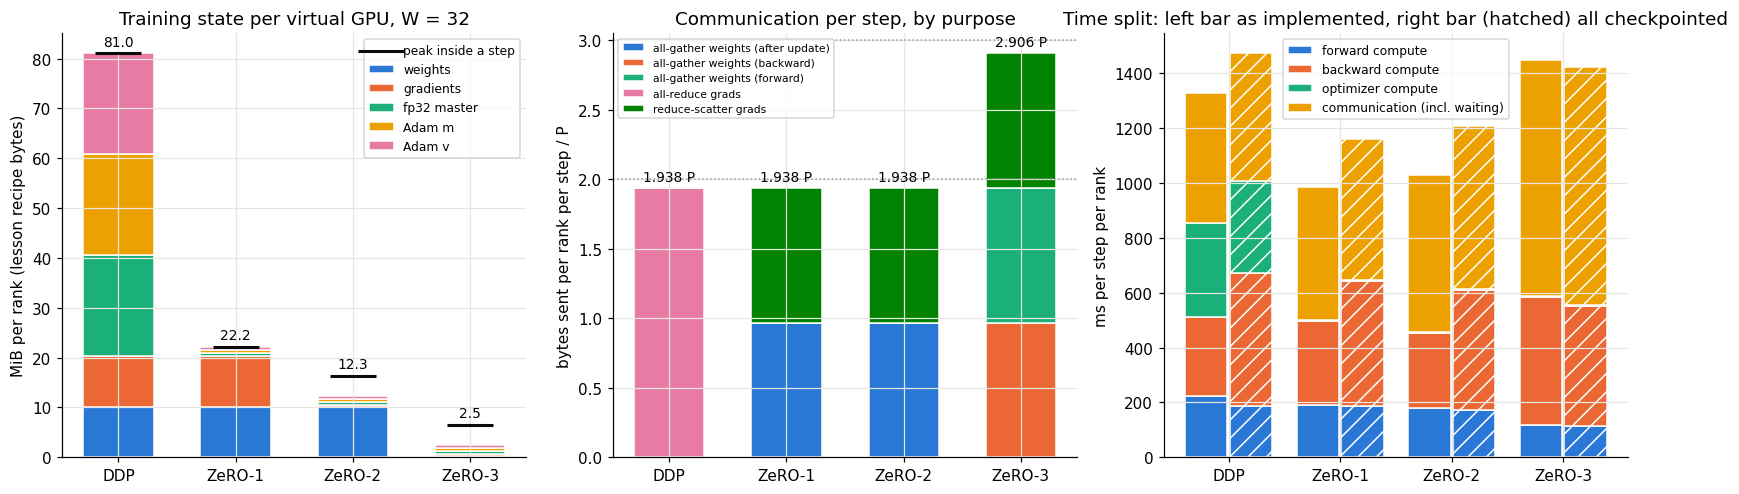

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
x = np.arange(len(STAGES))
# (a) memory: stacked categories, persistent; peak marked
ax = axes[0]
bottom = np.zeros(len(STAGES))
for k in CATS:
    vals = np.array([p[st]["persistent_recipe"][k] / 2**20 for st in STAGES])
    ax.bar(x, vals, 0.6, bottom=bottom, color=CAT_COLOR[k], label=k, edgecolor="white", linewidth=1)
    bottom += vals
peaks = [p[st]["peak_recipe"] / 2**20 for st in STAGES]
ax.scatter(x, peaks, marker="_", s=900, color="#0b0b0b", zorder=5, label="peak inside a step")
for i, (b, pk) in enumerate(zip(bottom, peaks)):
    ax.text(i, max(b, pk) + 1.5, f"{b:.1f}", ha="center", fontsize=9)
ax.set_xticks(x, [STAGE_NAME[s].split(" (")[0] for s in STAGES])
ax.set_ylabel("MiB per rank (lesson recipe bytes)")
ax.set_title("Training state per virtual GPU, W = 32")
ax.legend(fontsize=8)
# (b) communication by purpose
ax = axes[1]
ops = sorted({op for st in STAGES for op in p[st]["comm_by_op_per_step"]})
bottom = np.zeros(len(STAGES))
for i, op in enumerate(ops):
    vals = np.array([p[st]["comm_by_op_per_step"].get(op, 0) / p[st]["P"] for st in STAGES])
    if vals.max() < 1e-3:
        continue
    ax.bar(x, vals, 0.6, bottom=bottom, color=C[i % len(C)], label=op, edgecolor="white", linewidth=1)
    bottom += vals
for i, b in enumerate(bottom):
    ax.text(i, b + 0.05, f"{b:.3f} P", ha="center", fontsize=9)
ax.axhline(2, color="#9a9994", lw=1, ls=":"); ax.axhline(3, color="#9a9994", lw=1, ls=":")
ax.set_xticks(x, [STAGE_NAME[s].split(" (")[0] for s in STAGES])
ax.set_ylabel("bytes sent per rank per step / P")
ax.set_title("Communication per step, by purpose")
ax.legend(fontsize=7, loc="upper left")
# (c) time split, checkpointed runs (same compute for all)
ax = axes[2]
parts = [("fwd_compute", "forward compute"), ("bwd_compute", "backward compute"), ("opt_compute", "optimizer compute"), ("comm", "communication (incl. waiting)")]
for j, (mode, off) in enumerate((("plain", -0.2), ("ckpt", 0.2))):
    bottom = np.zeros(len(STAGES))
    for i, (k, lab) in enumerate(parts):
        vals = np.array([cmp_[mode][st]["time"][k] * 1e3 for st in STAGES])
        ax.bar(x + off, vals, 0.38, bottom=bottom, color=C[i], label=lab if j == 0 else None, edgecolor="white",
               linewidth=1, hatch=None if mode == "plain" else "//")
        bottom += vals
ax.set_xticks(x, [STAGE_NAME[s].split(" (")[0] for s in STAGES])
ax.set_ylabel("ms per step per rank")
ax.set_title("Time split: left bar as implemented, right bar (hatched) all checkpointed")
ax.legend(fontsize=8)
plt.tight_layout()
savefig("stages_memory_comm_time.png")

### Observations (Section 9)

**Memory (exact):** 81.04, 22.16, 12.35, 2.53 MiB per rank between steps; peaks 81.04, 22.16, 16.35, 6.53 MiB.
Activations are **29.0 MiB in every stage** with normal autograd: ZeRO does not shrink activations at all. Only
checkpointing does (5.25 MiB in every stage). For DDP the activations are 36% of the training state, for ZeRO-1 131%,
and for ZeRO-3 (even with its recomputation, 5.25 MiB) **twice** its 2.53 MiB of training state. On a real run this is why ZeRO-3 is almost always combined
with activation checkpointing.

**Communication (exact):** 1.9375 P for DDP, ZeRO-1, ZeRO-2 and 2.9063 P for ZeRO-3, broken down by purpose in the
middle plot.

**Computation:**

* **Optimizer:** DDP 343 ms per step, ZeRO-1 4.4 ms: **78 times less for 32 times fewer weights.** The extra factor of
  2.4 is a cache effect: DDP's Adam streams 5.3M weights × 5 tensors (100 MB in fp32) through memory on each of 32
  processes at once, while a 166k-weight slice (3 MB) fits in cache. On this CPU the optimizer was a quarter of DDP's
  step, so ZeRO-1 made the step **26% faster** (1,327 → 984 ms) while also using 3.7 times less memory.
* **Forward + backward compute:** equal for DDP, ZeRO-1 and ZeRO-2 within noise (about 450 to 510 ms). With every stage
  checkpointed, ZeRO-3's forward + backward compute is **0.82 times** DDP's, not the predicted 1.0. The reason is the
  simulation, not ZeRO: a ZeRO-3 rank spends 860 ms per step waiting in collectives, which frees cores, so its compute
  runs with less competition from the other 31 processes. Section 15 confirms this: with one core per rank, forward
  compute is 184 to 187 ms in every stage.
* **Communication time:** ZeRO-3 / DDP = 1.86 times, for 1.5 times the bytes. The extra 0.36 comes from latency:
  ZeRO-3 makes 19 collectives per step (6 gathers in forward, 6 in backward, 6 reduce-scatters, 1 norm) against 6 for
  DDP, about 620 ring rounds against 372, at 0.66 ms each (Section 2).
* **ZeRO-2 communicates more slowly than ZeRO-1** (573 against 484 ms) for the same bytes: its reduce-scatters run in
  the middle of backward, so a rank that finishes a unit early waits there for slower ranks.

**The operating-system view agrees:** each DDP process grew by 169 MiB of resident memory against 26 MiB for ZeRO-3
(noisier than the ledger, because it includes activations and allocator caches).

## 10. The lesson's table, measured in real bf16 bytes (8 ranks)

The runs so far used fp64 or fp32 numbers and read the ledger in recipe bytes. Here the weights and gradients are
**real bf16 tensors** and the master copy and Adam state real fp32, so the *actual* bytes are the lesson's bytes, with
no conversion. The run uses $W = 8$ to match the lesson's table (16, 5.5, 3.75, 2.0 bytes per weight), 3 steps.

bf16 values go over the wire as int16 (same bits; not every gloo build can send bf16), and the ring sums them in bf16,
as NCCL does for bf16 gradients.

**Predictions:** actual bytes per weight = 16.00 / 5.50 / 3.75 / 2.00 exactly (no padding: every unit is divisible by
8); bytes sent per step = $1.75P$ / $1.75P$ / $1.75P$ / $2.625P$ with $P = 2N = 10.1$ MiB ($2 \cdot \frac{7}{8} = 1.75$,
$3 \cdot \frac{7}{8} = 2.625$), so half the fp32 bytes; losses within about 0.01 of an fp32 run.

In [24]:
try:
    launch(8, "zero_sim.py --stages ddp,zero1,zero2,zero3 --dtype bf16 --steps 3 --out runs/bf16_w8.json")
    bf = json.load(open("runs/bf16_w8.json"))
except RuntimeError as e:          # a CPU bf16 kernel missing in this PyTorch build must not stop the notebook
    print(f"bf16 run failed ({e}); the section is skipped, see the error above")
    bf = {}
print(f"\n{'stage':18s}{'actual bytes/weight':>21s}{'lesson':>8s}{'peak bytes/weight':>19s}{'sent per step':>15s}{'= P x':>8s}{'pred':>7s}{'loss step 3':>13s}")
for st in (STAGES if bf else []):
    s = summarize(bf[st])
    pred_comm = (3 if st == "zero3" else 2) * 7 / 8
    print(f"{STAGE_NAME[st]:18s}{s['persistent_actual_per_weight']:>21.4f}{bytes_per_weight(st, 8):>8.2f}"
          f"{s['peak_actual'] / s['N']:>19.4f}{s['comm_per_step'] / 2**20:>11.2f} MiB{s['comm_in_P']:>8.4f}{pred_comm:>7.3f}{s['losses'][-1]:>13.4f}")
    R[f"bf16_w8_bytes_per_weight_{st}"] = s["persistent_actual_per_weight"]
    R[f"bf16_w8_comm_P_{st}"] = s["comm_in_P"]

world size W = 8 processes (virtual GPUs), 1 CPU thread(s) each, dtype bf16, micro-batch 8 x 128 tokens per rank, global batch 64
  [ddp] step    1  mean loss over ranks 8.3224  step time 2.190 s
  [ddp] step    2  mean loss over ranks 8.2728  step time 2.009 s
  [ddp] step    3  mean loss over ranks 8.0982  step time 2.056 s
  [ddp] finished 3 steps in 7.0 s
  [zero1] step    1  mean loss over ranks 8.3224  step time 1.938 s
  [zero1] step    2  mean loss over ranks 8.2728  step time 1.938 s
  [zero1] step    3  mean loss over ranks 8.0982  step time 1.942 s
  [zero1] finished 3 steps in 6.4 s
  [zero2] step    1  mean loss over ranks 8.3224  step time 2.045 s
  [zero2] step    2  mean loss over ranks 8.2728  step time 2.093 s
  [zero2] step    3  mean loss over ranks 8.0982  step time 2.050 s
  [zero2] finished 3 steps in 6.7 s
  [zero3] step    1  mean loss over ranks 8.3224  step time 3.117 s
  [zero3] step    2  mean loss over ranks 8.2728  step time 2.721 s
  [zero3] step    3  m

### Observations (Section 10)

* **The lesson's table, measured in real bytes:** with bf16 weights and gradients and fp32 optimizer state, the
  actual bytes per weight on 8 ranks are **16.0000, 5.5000, 3.7500, 2.0000**, exactly the lesson's 16, 5.5, 3.75, 2.0.
* Peaks: ZeRO-2 4.54 and ZeRO-3 2.79 bytes per weight, again one unit above the persistent state.
* **Communication: 1.7500 P** for DDP, ZeRO-1, ZeRO-2 and **2.6250 P** for ZeRO-3, as predicted ($2\cdot7/8$,
  $3\cdot7/8$), with $P = 2N$ = 10.1 MiB: half the fp32 bytes, because bf16 is half the width.
* Losses after 3 steps: 8.0982 in all four stages, against 8.0978 in fp64 (Section 4): bf16 weights and a bf16 ring
  sum cost $4\times10^{-4}$ in loss at this point, and the four stages remain identical to each other.

## 11. Changing the number of GPUs: 1, 2, 4, 8, 16, 32

### 11a. What should happen

The global batch stays at 64 sequences, so each rank gets $64/W$ of them. Hand predictions (recipe bytes):

| quantity per rank | DDP | ZeRO-1 | ZeRO-2 | ZeRO-3 |
|---|---|---|---|---|
| training state, bytes/weight | $16$ | $4 + 12/W$ | $2 + 14/W$ | $16/W$ |
| as $W \to \infty$ | 16 | **4** (floor: full weights + grads) | **2** (floor: full weights) | **0** (but the largest unit must fit) |
| bytes sent / $P$ | $2\frac{W-1}{W}$ | $2\frac{W-1}{W}$ | $2\frac{W-1}{W}$ | $3\frac{W-1}{W}$ |
| forward + backward FLOP | $\propto 64/W$ | same | same | same (+33% recompute) |
| weights updated by Adam | $N$ | $N/W$ | $N/W$ | $N/W$ |

At $W = 1$ all four stages are the same thing (one rank owns everything), and the communication is 0. The bytes sent
per rank *rise* towards $2P$ (or $3P$) as $W$ grows and then stay flat: ring collectives do not get more expensive per
GPU with more GPUs, only slower in latency ($2(W-1)$ rounds). The computation per rank falls as $1/W$, so **the ratio
of communication to computation grows with $W$**, the same squeeze the lesson shows for faster GPUs.

The 6 runs below take 3 steps each (timings from steps 2-3).

In [25]:
SWEEP_W = [1, 2, 4, 8, 16, 32]
sweep = {}
for Wn in SWEEP_W:
    launch(Wn, f"zero_sim.py --stages ddp,zero1,zero2,zero3 --dtype fp32 --steps 3 --out runs/sweep_w{Wn}.json", show=False)
    d = json.load(open(f"runs/sweep_w{Wn}.json"))
    sweep[Wn] = {st: summarize(d[st]) for st in STAGES}
print(f"\n{'W':>3s} " + "".join(f"{STAGE_NAME[st].split(' (')[0]:>30s}" for st in STAGES))
print(f"{'':>3s} " + "".join(f"{'B/weight (pred)  sent/P  opt elems':>30s}" for st in STAGES))
for Wn in SWEEP_W:
    row = f"{Wn:>3d} "
    for st in STAGES:
        s = sweep[Wn][st]
        row += f"{s['persistent_recipe_per_weight']:>8.3f} ({bytes_per_weight(st, Wn):6.3f}) {s['comm_in_P']:>6.3f} {s['n_updated']:>9,}"
    print(row)
R["sweep"] = {Wn: {st: dict(bpw=sweep[Wn][st]["persistent_recipe_per_weight"], peak_bpw=sweep[Wn][st]["peak_recipe_per_weight"],
                            comm_P=sweep[Wn][st]["comm_in_P"], fwd_bwd_ms=(sweep[Wn][st]["time"]["fwd_compute"] + sweep[Wn][st]["time"]["bwd_compute"]) * 1e3,
                            opt_ms=sweep[Wn][st]["time"]["opt_compute"] * 1e3, comm_ms=sweep[Wn][st]["time"]["comm"] * 1e3) for st in STAGES} for Wn in SWEEP_W}

[launch] 1 processes x 1 thread(s): 52.7 s wall time, including process start-up
[launch] 2 processes x 1 thread(s): 30.5 s wall time, including process start-up
[launch] 4 processes x 1 thread(s): 19.3 s wall time, including process start-up
[launch] 8 processes x 1 thread(s): 18.0 s wall time, including process start-up
[launch] 16 processes x 1 thread(s): 21.5 s wall time, including process start-up
[launch] 32 processes x 1 thread(s): 35.3 s wall time, including process start-up

  W                            DDP                        ZeRO-1                        ZeRO-2                        ZeRO-3
    B/weight (pred)  sent/P  opt elemsB/weight (pred)  sent/P  opt elemsB/weight (pred)  sent/P  opt elemsB/weight (pred)  sent/P  opt elems
  1   16.000 (16.000)  0.000 5,310,720  16.000 (16.000)  0.000 5,310,720  16.000 (16.000)  0.000 5,310,720  16.000 (16.000)  0.000 5,310,720
  2   16.000 (16.000)  1.000 5,310,720  10.000 (10.000)  1.000 2,655,360   9.000 ( 9.000)  1.000 2,655,3

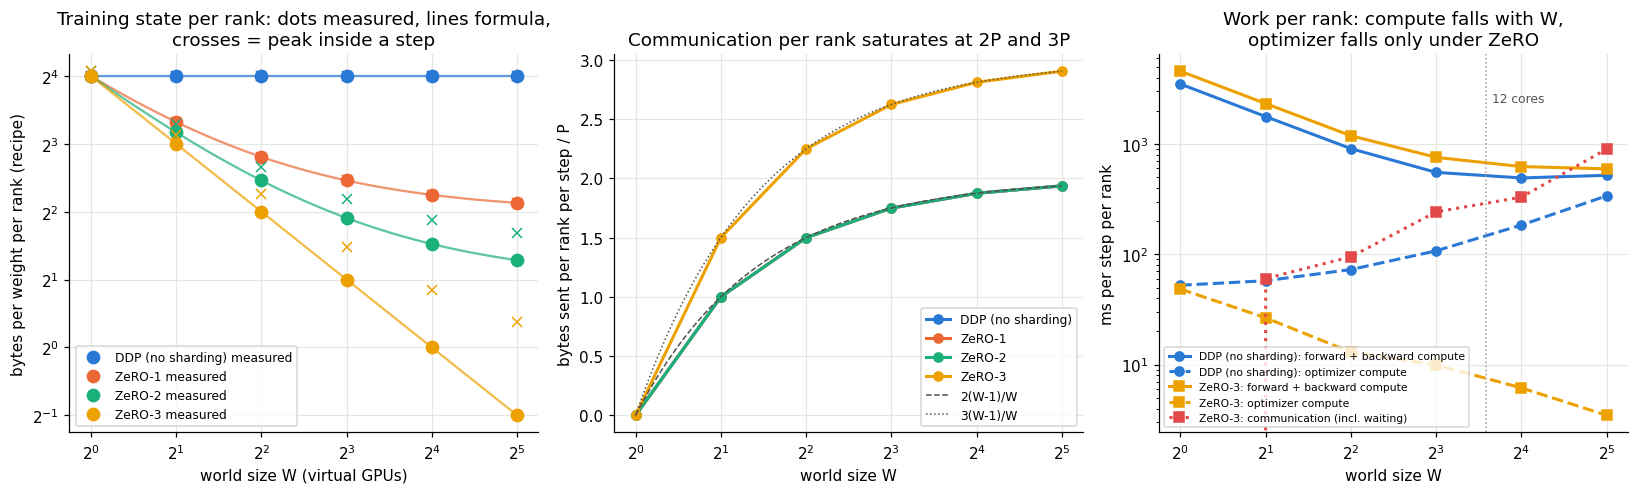

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
Ws = np.array(SWEEP_W)
Wf = np.logspace(0, np.log10(32), 100)
ax = axes[0]
for st in STAGES:
    ax.plot(Ws, [sweep[w][st]["persistent_recipe_per_weight"] for w in SWEEP_W], "o", color=STAGE_COLOR[st], ms=8, label=f"{STAGE_NAME[st]} measured")
    ax.plot(Ws, [sweep[w][st]["peak_recipe_per_weight"] for w in SWEEP_W], "x", color=STAGE_COLOR[st], ms=7)
    ax.plot(Wf, [bytes_per_weight(st, w) for w in Wf], "-", color=STAGE_COLOR[st], lw=1.5, alpha=0.7)
ax.set_xscale("log", base=2); ax.set_yscale("log", base=2)
ax.set_xlabel("world size W (virtual GPUs)"); ax.set_ylabel("bytes per weight per rank (recipe)")
ax.set_title("Training state per rank: dots measured, lines formula,\ncrosses = peak inside a step")
ax.legend(fontsize=8)
ax = axes[1]
# DDP, ZeRO-1 and ZeRO-2 send the same bytes, so their curves coincide: draw them with decreasing marker sizes
# (big hollow circle, medium diamond, small dot) so that all three stay visible.
style = {"ddp": dict(marker="o", ms=13, mfc="none", mew=2, lw=4), "zero1": dict(marker="D", ms=8, lw=2.5),
         "zero2": dict(marker="o", ms=4, lw=1.2), "zero3": dict(marker="s", ms=6, lw=2)}
for st in STAGES:
    ax.plot(Ws, [sweep[w][st]["comm_in_P"] for w in SWEEP_W], "-", color=STAGE_COLOR[st], label=STAGE_NAME[st], **style[st])
ax.text(4, 1.25, "DDP, ZeRO-1, ZeRO-2 coincide:\nsame bytes", fontsize=8, color="#52514e")
ax.plot(Wf, 2 * (Wf - 1) / Wf, "--", color="#52514e", lw=1, label="2(W-1)/W"); ax.plot(Wf, 3 * (Wf - 1) / Wf, ":", color="#52514e", lw=1, label="3(W-1)/W")
ax.set_xscale("log", base=2)
ax.set_xlabel("world size W"); ax.set_ylabel("bytes sent per rank per step / P")
ax.set_title("Communication per rank saturates at 2P and 3P")
ax.legend(fontsize=8)
ax = axes[2]
for st, mk in (("ddp", "o"), ("zero3", "s")):
    ax.plot(Ws, [sweep[w][st]["time"]["fwd_compute"] * 1e3 + sweep[w][st]["time"]["bwd_compute"] * 1e3 for w in SWEEP_W], mk + "-", color=STAGE_COLOR[st], label=f"{STAGE_NAME[st]}: forward + backward compute")
    ax.plot(Ws, [sweep[w][st]["time"]["opt_compute"] * 1e3 for w in SWEEP_W], mk + "--", color=STAGE_COLOR[st], label=f"{STAGE_NAME[st]}: optimizer compute")
ax.plot(Ws[1:], [sweep[w]["zero3"]["time"]["comm"] * 1e3 for w in SWEEP_W[1:]], "s:", color=C[7],
        label="ZeRO-3: communication (incl. waiting; 0 at W = 1)")
ax.axvline(NCPU, color="#9a9994", lw=1, ls=":"); ax.text(NCPU * 1.05, ax.get_ylim()[1] * 0.5, f"{NCPU} cores", fontsize=8, color="#52514e")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("world size W"); ax.set_ylabel("ms per step per rank")
ax.set_title("Work per rank: compute falls with W,\noptimizer falls only under ZeRO")
ax.legend(fontsize=7)
plt.tight_layout()
savefig("world_size_sweep.png")

### Observations (Section 11)

* **Memory follows the formulas exactly at every $W$** (table: every measured value equals the prediction to 3
  decimals). DDP is flat at 16; ZeRO-1 approaches its floor of 4 (4.375 at 32); ZeRO-2 approaches 2 (2.438); ZeRO-3
  keeps halving (0.5 at 32). The crosses show the peak: about 0.79 bytes per weight above the line for ZeRO-2 and
  ZeRO-3 at every $W$, because the largest unit does not shrink with $W$. At $W = 1$ every stage is the same 16 bytes,
  and ZeRO-2 and ZeRO-3 still pay the unit buffer (peak 16.79): sharding over one GPU only costs.
* **Bytes sent per rank:** 0, 1.0, 1.5, 1.75, 1.875, 1.9375 P for DDP, ZeRO-1 and ZeRO-2 ($2\frac{W-1}{W}$, the three
  curves lie exactly on top of each other) and 0, 1.5, 2.25, 2.625, 2.8125, 2.906 P for ZeRO-3. **The bytes per GPU
  saturate; adding GPUs does not add traffic per GPU.**
* **Computation per rank:** forward + backward fell from 3,500 ms ($W = 1$, 64 sequences) to 1,774, 908 and 553 ms at
  $W$ = 2, 4, 8, close to $1/W$. It then stopped falling (493 ms at 16, 520 ms at 32): beyond 12 processes the
  machine has no more cores, so the per-rank work keeps halving but each rank gets less of a core. On real GPUs each
  rank has its own device and the $1/W$ line would continue.
* **Optimizer per rank:** DDP's *rose* from 52 to 339 ms as $W$ grew (the same 5.3M-weight update on 32 processes
  competing for memory bandwidth); ZeRO's fell from 53 to 3.5 ms. **Under DDP, more GPUs means more redundant
  optimizer work in total; under ZeRO the total stays constant.**
* **The squeeze:** ZeRO-3's communication time grew from 60 ms ($W = 2$) to 899 ms ($W = 32$) while its compute fell, so
  communication overtook compute between $W = 16$ (330 against 624 ms) and $W = 32$ (899 against 596 ms). That is the lesson's point about faster GPUs,
  reproduced by shrinking the work per GPU instead.

**About the middle plot:** the DDP and ZeRO-1 curves are drawn, but they are hidden under ZeRO-2 because the three
send the same bytes (1.9375 P against 1.93752 P at $W = 32$; the difference is the 496-byte gradient-norm
all-reduce). The plotting code has since been changed to draw the three with different marker sizes, and the
ZeRO-3 communication line in the right-hand plot now starts at $W = 2$ (at $W = 1$ it is exactly 0, which a log axis
cannot show, hence the line falling off the bottom in the saved image).

## 12. Training for real: 150 steps of ZeRO-3 on 32 virtual GPUs

The equivalence tests ran 4 steps. Here the model is trained for 150 steps (8,192 tokens per step, 1.2M tokens in
all, warmup 10, cosine to 10%, peak learning rate $3\times10^{-3}$, clipping at 1.0) under ZeRO-3 on 32 ranks, so no
rank ever holds more than 1/32 of the model between steps. The held-out loss (64 fixed windows from the last 5% of
the stream) is measured every 25 steps. The reference is the same run on one process with all the cores (fp32, so not
bit-identical: different batching inside the matrix multiplications and a different order of the gradient sum).

**Prediction:** the two loss curves lie on top of each other (differences of order $10^{-3}$, rounding amplified by
150 steps of training), and the held-out loss falls from 8.3 ($\ln 4096$) to roughly 3 to 3.5.

world size W = 32 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp32, micro-batch 2 x 128 tokens per rank, global batch 64
  [zero3] step    1  mean loss over ranks 8.3224  step time 2.909 s  held-out loss 8.2758
  [zero3] step    2  mean loss over ranks 8.2727  step time 1.473 s
  [zero3] step   15  mean loss over ranks 6.8412  step time 1.471 s
  [zero3] step   30  mean loss over ranks 5.6611  step time 1.463 s
  [zero3] step   45  mean loss over ranks 5.3030  step time 1.474 s
  [zero3] step   60  mean loss over ranks 5.0441  step time 1.465 s
  [zero3] step   75  mean loss over ranks 4.7532  step time 1.487 s  held-out loss 4.8455
  [zero3] step   90  mean loss over ranks 4.5242  step time 1.469 s
  [zero3] step  105  mean loss over ranks 4.4571  step time 1.486 s
  [zero3] step  120  mean loss over ranks 4.3618  step time 1.500 s
  [zero3] step  135  mean loss over ranks 4.2991  step time 1.459 s
  [zero3] step  150  mean loss over ranks 4.3248  step time 1.469 s  held-out

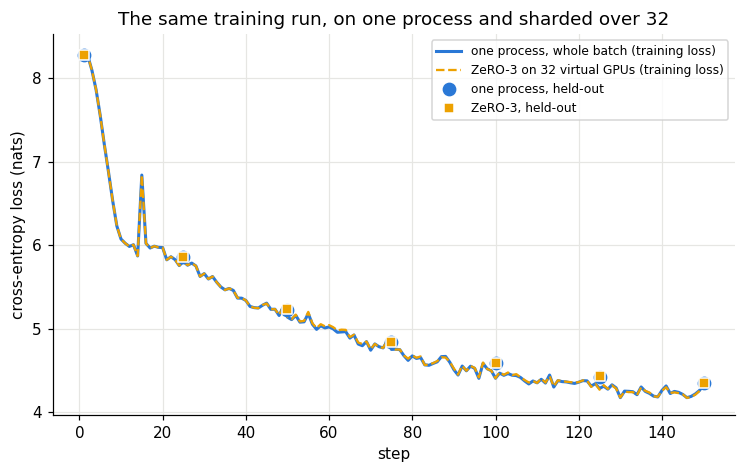

In [27]:
TRAIN_ARGS = "--dtype fp32 --steps 150 --eval_every 25 --clip 1.0"
launch(32, f"zero_sim.py --stages zero3 {TRAIN_ARGS} --out runs/train_zero3.json")
launch(1, f"zero_sim.py --stages ddp {TRAIN_ARGS} --out runs/train_ref.json", threads=NCPU)
tz = json.load(open("runs/train_zero3.json"))["zero3"]["ranks"][0]["hist"]
tr1 = json.load(open("runs/train_ref.json"))["ddp"]["ranks"][0]["hist"]
lz, l1 = np.array([h["loss_global"] for h in tz]), np.array([h["loss_global"] for h in tr1])
ez = {h["t"]: h["eval_loss"] for h in tz if "eval_loss" in h}
e1 = {h["t"]: h["eval_loss"] for h in tr1 if "eval_loss" in h}
print(f"\n{'step':>5s}{'held-out, ZeRO-3 x32':>22s}{'held-out, one process':>23s}{'difference':>12s}")
for t in sorted(ez):
    print(f"{t:>5d}{ez[t]:>22.4f}{e1[t]:>23.4f}{ez[t] - e1[t]:>12.2e}")
print(f"max |training loss difference| over 150 steps : {np.abs(lz - l1).max():.2e}")
print(f"mean step time: ZeRO-3 on 32 processes {np.mean([h['total'] for h in tz[1:]]):.3f} s,"
      f" one process with {NCPU} threads {np.mean([h['total'] for h in tr1[1:]]):.3f} s")
R.update(train_eval_zero3=ez, train_eval_ref=e1, train_max_loss_diff=float(np.abs(lz - l1).max()))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(l1) + 1), l1, color=C[0], lw=2, label="one process, whole batch (training loss)")
ax.plot(np.arange(1, len(lz) + 1), lz, color=C[3], lw=1.5, ls="--", label="ZeRO-3 on 32 virtual GPUs (training loss)")
ax.plot(sorted(e1), [e1[t] for t in sorted(e1)], "o", color=C[0], ms=8, label="one process, held-out")
ax.plot(sorted(ez), [ez[t] for t in sorted(ez)], "s", color=C[3], ms=6, mec="white", label="ZeRO-3, held-out")
ax.set_xlabel("step"); ax.set_ylabel("cross-entropy loss (nats)")
ax.set_title("The same training run, on one process and sharded over 32")
ax.legend(fontsize=8)
savefig("training_zero3_vs_single.png")

### Observations (Section 12)

* **Training under ZeRO-3 on 32 virtual GPUs works like training on one process:** held-out loss 8.276 → 5.860 (step
  25) → 4.846 (75) → **4.349** (150), against 4.346 for the one-process run. The curves are indistinguishable in the
  plot, and no rank ever held more than 2.5 MiB of training state between steps (6.5 MiB at its peak).
* The prediction "differences of order $10^{-3}$" was only partly right. Up to step 25 the runs agree to
  $6\times10^{-7}$ (fp32 rounding). After that the largest gap in training loss is $2.8\times10^{-2}$ and in held-out
  loss $7.7\times10^{-3}$ (step 50), and they do not grow further (held-out 150: $3.9\times10^{-3}$). The two runs are
  not the same arithmetic in fp32 (one matrix multiply over 64 sequences against 32 over 2, and a ring sum), and
  training amplifies tiny differences into different but equally good trajectories. The fp64 tests (Sections 5 to
  8) show the method is exact; this run shows it also trains.
* Both runs have the same loss spike at step 15 (6.0 → 6.8 → 6.0): it is in the one-process run too, so it is the data
  and the learning rate (peak $3\times10^{-3}$ reached at step 10), not the sharding.
* Speed: 1.48 s per step for 32 processes against 0.72 s for one process with 12 threads. Same work, 12 cores either
  way; the 32 processes add 860 ms of communication per step.

## 13. Where it breaks, and why: three deliberate bugs

Each bug is one switch in `zero_sim.py` (`--bug`). They run on 8 ranks (64 / 8 = 8 sequences each), 20 steps, fp32.

**Bug A, DDP without averaging (`no_average`).** Every rank applies *its own* gradient. The lesson's widget shows the
replicas drifting when averaging is switched off. **Prediction:** after step 1 the largest difference between two
ranks' weights is about $2\eta_1$ (Adam's first step is $\pm\eta$ per weight, with independent signs on different
ranks; $\eta_1 = 3\times10^{-4}$ in warmup), and it keeps growing. The 8 copies are 8 different models.

**Bug B, ZeRO-1 without the weight all-gather (`skip_allgather`).** Each rank updates its slice but never receives
the others' new slices. **Prediction:** rank $r$'s copy is right in slice $r$ and frozen at the initial values
elsewhere, so the replicas differ by the size of the accumulated updates (growing roughly like $\sum_t \eta_t$), and
the training loss falls more slowly, because each rank's forward uses a model that is 7/8 untrained.

**Bug C, summing instead of averaging the gradients (`no_divide`).** The gradient is $W = 8$ times too large. This
looks serious and is **nearly harmless under Adam**: the update $\hat m/\sqrt{\hat v}$ does not change when every
gradient is multiplied by a constant $c$, since $m \to c\,m$ and $\sqrt{v} \to c\sqrt{v}$; only the tiny $\epsilon$
term notices. **Prediction:** with clipping off, the losses match the correct run to about $10^{-5}$ or better. With
clipping at 1.0 it does matter: the norm is 8 times larger, so clipping switches on at steps where it should not, and
the clipping factor changes from step to step, which a constant-$c$ argument no longer covers. (With plain SGD the bug
would multiply the learning rate by 8.)

[launch] 8 processes x 1 thread(s): 24.1 s wall time, including process start-up
[launch] 8 processes x 1 thread(s): 23.0 s wall time, including process start-up
[launch] 8 processes x 1 thread(s): 25.4 s wall time, including process start-up
[launch] 8 processes x 1 thread(s): 21.8 s wall time, including process start-up
[launch] 8 processes x 1 thread(s): 22.1 s wall time, including process start-up
[launch] 8 processes x 1 thread(s): 21.7 s wall time, including process start-up

 step  drift A (DDP no avg)  drift B (ZeRO-1 no AG)  drift, correct  loss correct   loss A   loss B
    1             6.000e-04               3.000e-04         0.0e+00        8.3224   8.3224   8.3224
    2             1.800e-03               9.003e-04         0.0e+00        8.2727   8.2899   8.3154
    5             8.940e-03               4.507e-03         0.0e+00        7.5578   7.6564   8.2489
   10             3.221e-02               1.658e-02         0.0e+00        6.0842   6.1615   8.0550
   20        

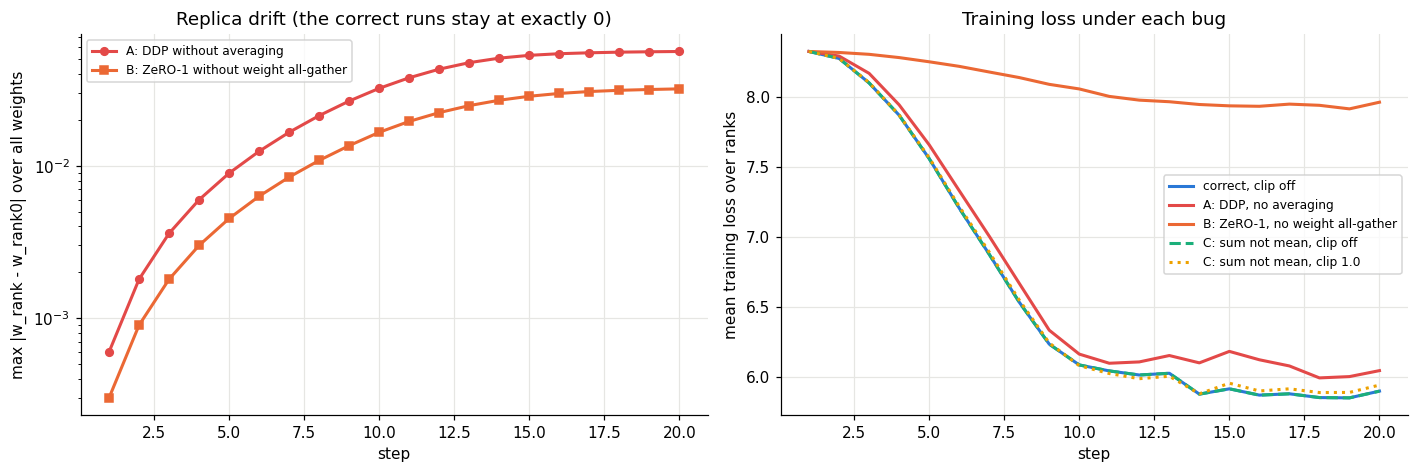

In [28]:
BUG_ARGS = "--dtype fp32 --steps 20"
runs_bug = {}
for name, args in (("A: DDP, no averaging", "--stages ddp --bug no_average --drift --clip 0"),
                   ("B: ZeRO-1, no weight all-gather", "--stages zero1 --bug skip_allgather --drift --clip 0"),
                   ("correct, clip off", "--stages ddp --drift --clip 0"),
                   ("C: sum not mean, clip off", "--stages ddp --bug no_divide --clip 0"),
                   ("correct, clip 1.0", "--stages ddp --clip 1.0"),
                   ("C: sum not mean, clip 1.0", "--stages ddp --bug no_divide --clip 1.0")):
    out = f"runs/bug_{len(runs_bug)}.json"
    launch(8, f"zero_sim.py {args} {BUG_ARGS} --out {out}", show=False)
    d = json.load(open(out))
    runs_bug[name] = list(d.values())[0]["ranks"][0]["hist"]

def col(name, key):
    return np.array([h[key] if h.get(key) is not None else np.nan for h in runs_bug[name]])

print(f"\n{'step':>5s}{'drift A (DDP no avg)':>22s}{'drift B (ZeRO-1 no AG)':>24s}{'drift, correct':>16s}"
      f"{'loss correct':>14s}{'loss A':>9s}{'loss B':>9s}")
for i in (0, 1, 4, 9, 19):
    print(f"{i + 1:>5d}{col('A: DDP, no averaging', 'replica_max_diff')[i]:>22.3e}{col('B: ZeRO-1, no weight all-gather', 'replica_max_diff')[i]:>24.3e}"
          f"{col('correct, clip off', 'replica_max_diff')[i]:>16.1e}{col('correct, clip off', 'loss_global')[i]:>14.4f}"
          f"{col('A: DDP, no averaging', 'loss_global')[i]:>9.4f}{col('B: ZeRO-1, no weight all-gather', 'loss_global')[i]:>9.4f}")
lr1 = runs_bug["correct, clip off"][0]["lr"]
print(f"learning rate at step 1: {lr1:.1e}  ->  predicted drift after step 1 under bug A: about 2 x lr = {2 * lr1:.1e}")
dC0 = np.abs(col("C: sum not mean, clip off", "loss_global") - col("correct, clip off", "loss_global")).max()
dC1 = np.abs(col("C: sum not mean, clip 1.0", "loss_global") - col("correct, clip 1.0", "loss_global")).max()
gn_ok, gn_bug = col("correct, clip 1.0", "grad_norm"), col("C: sum not mean, clip 1.0", "grad_norm")
print(f"\nbug C with clipping off : max |loss difference| over 20 steps = {dC0:.2e}   (Adam is scale-invariant)")
print(f"bug C with clipping 1.0 : max |loss difference| over 20 steps = {dC1:.2e}")
print(f"  steps where clipping acted: correct run {int((gn_ok > 1).sum())} of 20, buggy run {int((gn_bug > 1).sum())} of 20"
      f"   (gradient norm at step 20: {gn_ok[-1]:.3f} vs {gn_bug[-1]:.3f})")
R.update(bugA_drift_end=float(col("A: DDP, no averaging", "replica_max_diff")[-1]),
         bugB_drift_end=float(col("B: ZeRO-1, no weight all-gather", "replica_max_diff")[-1]),
         bugC_clip0_maxdiff=float(dC0), bugC_clip1_maxdiff=float(dC1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
steps_ = np.arange(1, 21)
ax.semilogy(steps_, col("A: DDP, no averaging", "replica_max_diff"), "o-", color=C[7], ms=5, label="A: DDP without averaging")
ax.semilogy(steps_, col("B: ZeRO-1, no weight all-gather", "replica_max_diff"), "s-", color=C[1], ms=5, label="B: ZeRO-1 without weight all-gather")
ax.set_xlabel("step"); ax.set_ylabel("max |w_rank - w_rank0| over all weights")
ax.set_title("Replica drift (the correct runs stay at exactly 0)")
ax.legend(fontsize=8)
ax = axes[1]
for name, cc, ls in (("correct, clip off", C[0], "-"), ("A: DDP, no averaging", C[7], "-"), ("B: ZeRO-1, no weight all-gather", C[1], "-"),
                     ("C: sum not mean, clip off", C[2], "--"), ("C: sum not mean, clip 1.0", C[3], ":")):
    ax.plot(steps_, col(name, "loss_global"), ls, color=cc, label=name)
ax.set_xlabel("step"); ax.set_ylabel("mean training loss over ranks")
ax.set_title("Training loss under each bug")
ax.legend(fontsize=8)
plt.tight_layout()
savefig("bugs_drift_and_loss.png")

### Observations (Section 13)

* **Bug A (DDP, no averaging):** the drift after step 1 is **$6.000\times10^{-4}$, exactly the predicted $2\eta_1$**
  (Adam's first step is $\pm\eta$ per weight, with opposite signs on different ranks), and it grows to
  $5.6\times10^{-2}$ by step 20. The mean loss looks only a little worse (6.04 against 5.90), which makes this bug
  dangerous: each rank's loss is measured on its own model and its own data, so nothing in the loss curve says
  that there are now 8 different models.
* **Bug B (ZeRO-1, no weight all-gather):** drift $3.0\times10^{-4}$ after step 1, exactly $\eta_1$ (rank 0 moved its
  slice, the other ranks did not), $3.2\times10^{-2}$ by step 20. This one is obvious in the loss: **7.96 against 5.90
  after 20 steps**, because each rank trains a model that is 7/8 frozen at initialisation. The single all-gather after
  the update is what makes ZeRO-1 equal to DDP.
* **Bug C (sum instead of mean), clipping off:** the losses differ by at most $4.2\times10^{-4}$ over 20 steps, 36
  times less than with clipping on. My prediction of $10^{-5}$ or better was too optimistic. Adam ignores the factor
  8 only where $\sqrt{v} \gg \epsilon = 10^{-8}$. For weights with near-zero gradients (embedding rows of tokens absent
  from the batch, almost-unused vocabulary entries) $\epsilon$ is not negligible, so scaling by 8 changes their update.
  Those small changes then propagate through training. Still: an 8-times error in the gradient changed the loss in the
  fourth decimal.
* **Bug C with clipping 1.0:** loss differences up to $1.5\times10^{-2}$. The correct run clipped on 9 of 20 steps;
  the buggy run clipped on **all 20**, since its gradient norm is 8 times larger (5.05 against 0.65 at step 20).
  Clipping is not scale-invariant, so a bug Adam forgives becomes a real change of the training recipe. Under plain
  SGD it would have been an 8-times larger learning rate.

## 14. Back to the 30B model

The simulation measured three rules; this section applies them to V5's 30B weights on 80 GB cards.

1. **Memory per GPU** follows $16$, $4 + 12/W$, $2 + 14/W$, $16/W$ bytes per weight *exactly* (Sections 5 to 8, 10, 11),
   plus, inside a step, **one unit's full weights and gradients** for ZeRO-3 (and one unit's full gradient for ZeRO-2).
   For a 30B model with, say, 60 layers, one layer is about $30\times10^9 / 60 = 0.5$B weights, so the per-unit
   extra is $0.5\times10^9 \times (2 + 2)$ B $\approx 1.9$ GiB: small next to 74.5 GiB, unlike in our toy model, where
   the head unit was 20% of everything.
2. **Bytes on the wire per GPU** are $2\frac{W-1}{W}P$ for DDP, ZeRO-1, ZeRO-2 and $3\frac{W-1}{W}P$ for ZeRO-3,
   independent of the GPU count.
3. **Compute per GPU** is unchanged by ZeRO; only the optimizer's share shrinks by $W$, and checkpointing (if used to
   save activation memory) adds a third.

The plot redraws the lesson's memory wall from these formulas, with the per-unit peak added for ZeRO-3.

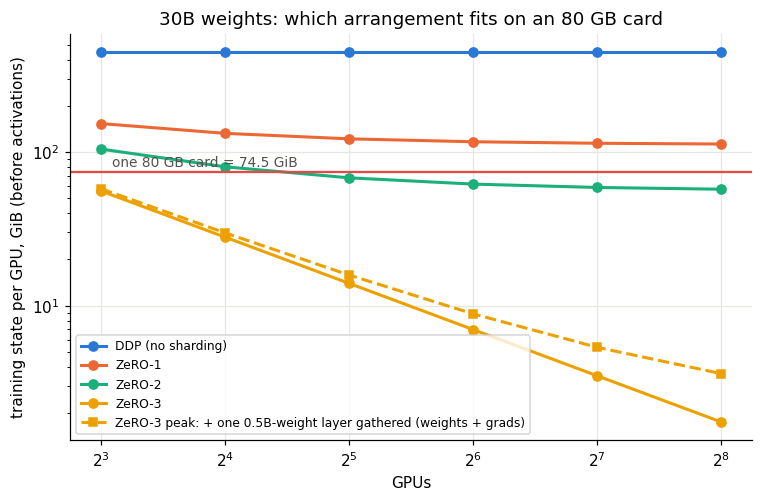

W =   8: DDP  447.0 GiB,  ZeRO-1  153.7 GiB,  ZeRO-2  104.8 GiB,  ZeRO-3   55.9 GiB,  ZeRO-3 peak  57.7 GiB
W =  32: DDP  447.0 GiB,  ZeRO-1  122.2 GiB,  ZeRO-2   68.1 GiB,  ZeRO-3   14.0 GiB,  ZeRO-3 peak  15.8 GiB
W =  64: DDP  447.0 GiB,  ZeRO-1  117.0 GiB,  ZeRO-2   62.0 GiB,  ZeRO-3    7.0 GiB,  ZeRO-3 peak   8.8 GiB
  ZeRO-2 on  8 GPUs:  105.0 GB sent per GPU per step ->  0.23 s at NVLink speed,  2.10 s at InfiniBand speed
  ZeRO-3 on  8 GPUs:  157.5 GB sent per GPU per step ->  0.35 s at NVLink speed,  3.15 s at InfiniBand speed
  ZeRO-2 on 64 GPUs:  118.1 GB sent per GPU per step ->  0.26 s at NVLink speed,  2.36 s at InfiniBand speed
  ZeRO-3 on 64 GPUs:  177.2 GB sent per GPU per step ->  0.39 s at NVLink speed,  3.54 s at InfiniBand speed


In [29]:
Wgrid = np.array([8, 16, 32, 64, 128, 256])
layer = 30e9 / 60
fig, ax = plt.subplots(figsize=(8, 4.8))
for st in STAGES:
    ax.plot(Wgrid, [N30 * bytes_per_weight(st, w) / GiB for w in Wgrid], "o-", color=STAGE_COLOR[st], ms=6, label=STAGE_NAME[st])
ax.plot(Wgrid, [(N30 * bytes_per_weight("zero3", w) + 4 * layer) / GiB for w in Wgrid], "s--", color=STAGE_COLOR["zero3"], ms=5,
        label="ZeRO-3 peak: + one 0.5B-weight layer gathered (weights + grads)")
ax.axhline(74.5, color="#e34948", lw=1.5)
ax.text(8.5, 80, "one 80 GB card = 74.5 GiB", color="#52514e", fontsize=9)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("GPUs"); ax.set_ylabel("training state per GPU, GiB (before activations)")
ax.set_title("30B weights: which arrangement fits on an 80 GB card")
ax.legend(fontsize=8)
savefig("memory_wall_30b.png")
for w in (8, 32, 64):
    print(f"W = {w:3d}: " + ",  ".join(f"{STAGE_NAME[s].split(' (')[0]} {N30 * bytes_per_weight(s, w) / GiB:6.1f} GiB" for s in STAGES)
          + f",  ZeRO-3 peak {(N30 * bytes_per_weight('zero3', w) + 4 * layer) / GiB:5.1f} GiB")
P30 = 2 * N30
for w in (8, 64):
    for st, k in (("ZeRO-2", 2), ("ZeRO-3", 3)):
        b = k * (w - 1) / w * P30
        print(f"  {st} on {w:2d} GPUs: {b / GB:6.1f} GB sent per GPU per step -> {b / GB / 450:5.2f} s at NVLink speed, {b / GB / 50:5.2f} s at InfiniBand speed")

### Observations (Section 14), and what I would choose for V5

* The per-unit peak that dominated our toy model is small at scale: ZeRO-3 on 8 GPUs needs 55.9 GiB, and 57.7 GiB with
  one 0.5B-weight layer gathered, which leaves about 17 GiB of an 80 GB card for activations. On 32 GPUs it is 15.8 GiB.
* ZeRO-1 never fits on an 80 GB card (117 GiB even at 64 GPUs); ZeRO-2 needs 32 or more GPUs (68.1 GiB at 32, which
  leaves 6 GiB for activations).
* **My choice for V5 on 80 GB cards: ZeRO-3 with activation checkpointing.** It fits from 8 GPUs with room for
  activations, costs 1.5 times ZeRO-2's bytes (157.5 against 105.0 GB per GPU per step on 8 GPUs, 0.35 against
  0.23 s over NVLink), and that extra is small next to the compute of a 1M-token step. ZeRO-2 is only an option on
  32+ GPUs, and then most of its traffic crosses InfiniBand (2.1 to 2.4 s per step), where overlap is no longer
  optional. On 180 GB B200 cards the answer changes, see Section 15b.

## 15. One real node: 8 GPUs, one core each, and what it means for the capstone

### 15a. Why a node, and why 8

The 32-rank runs above behave like **one node with 32 GPUs**, all joined by the same wire. Real machines are not like
that. A node holds **8 GPUs** joined by NVLink (about 450 GB/s per GPU on H100, about 900 GB/s on B200), and nodes are
joined by InfiniBand (about 50 GB/s per GPU), **9 to 18 times slower**. A ring that spans 4 nodes has 4 links that
cross between nodes, and a ring runs at the speed of its slowest link, so the whole collective runs at InfiniBand speed.
**Keeping all the traffic inside one node is the cheapest communication there is.**

Colab has 12 vCPUs, so 8 ranks can each be **pinned to their own core** (`--pin`, `os.sched_setaffinity`). With no
two processes sharing a core, a rank waiting in a collective is waiting for the transfer and for real load imbalance,
not for the operating system to give a slower rank its turn. These are the most trustworthy timings in the notebook.
(Caveat: 12 vCPUs are probably 6 physical cores with 2 hyperthreads each, so some pinned ranks still share a physical
core.)

**Predictions** (global batch 64, so 8 sequences = 1,024 tokens per rank, 4 times the 32-rank runs):

* bytes sent per step: $2 \cdot \frac{7}{8} = 1.75\,P$ for DDP, ZeRO-1, ZeRO-2 and $3 \cdot \frac{7}{8} = 2.625\,P$ for ZeRO-3;
* training state per rank: 16, 5.5, 3.75, 2.0 bytes per weight (the lesson's table);
* compute per rank: 4 times the 32-rank runs ($\approx 27.8$ GFLOP per step), but on a whole core instead of 12/32 of one;
* **communication as a share of the step should be much smaller than at $W = 32$**: about the same $2P$ per rank is
  sent, but with 4 times the work to hide it behind, and 14 ring rounds instead of 62.

world size W = 8 processes (virtual GPUs), 1 CPU thread(s) each, dtype fp32, micro-batch 8 x 128 tokens per rank, global batch 64, each rank pinned to its own core (rank 0 -> core 0)
  [ddp] step    1  mean loss over ranks 8.3224  step time 0.985 s
  [ddp] step    2  mean loss over ranks 8.2727  step time 0.970 s
  [ddp] step    6  mean loss over ranks 7.2043  step time 0.884 s
  [ddp] finished 6 steps in 6.3 s
  [zero1] step    1  mean loss over ranks 8.3224  step time 0.759 s
  [zero1] step    2  mean loss over ranks 8.2727  step time 0.761 s
  [zero1] step    6  mean loss over ranks 7.2043  step time 0.758 s
  [zero1] finished 6 steps in 5.2 s
  [zero2] step    1  mean loss over ranks 8.3224  step time 0.810 s
  [zero2] step    2  mean loss over ranks 8.2727  step time 0.807 s
  [zero2] step    6  mean loss over ranks 7.2043  step time 0.810 s
  [zero2] finished 6 steps in 5.4 s
  [zero3] step    1  mean loss over ranks 8.3224  step time 1.492 s
  [zero3] step    2  mean loss over r

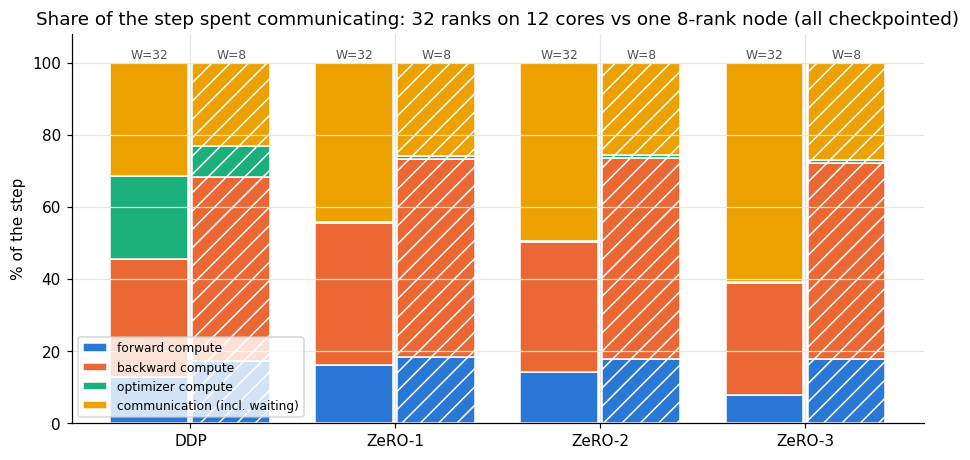

In [30]:
launch(8, "zero_sim.py --stages ddp,zero1,zero2,zero3 --dtype fp32 --steps 6 --pin --out runs/node8.json")
launch(8, "zero_sim.py --stages ddp,zero1,zero2,zero3 --dtype fp32 --steps 6 --pin --ckpt --out runs/node8_ckpt.json")
node = {k: {st: summarize(json.load(open(f))[st]) for st in STAGES}
        for k, f in (("plain", "runs/node8.json"), ("ckpt", "runs/node8_ckpt.json"))}
gflop_rank8 = R["train_gflop_per_rank_step"] * 4                            # 8 sequences per rank instead of 2
for mode, title in (("plain", "as implemented"), ("ckpt", "all four with activation checkpointing")):
    print(f"\n=== one node, 8 ranks pinned to 8 cores, {title}: mean over steps 2-6 and the 8 ranks ===")
    print(f"{'stage':18s}{'B/weight':>9s}{'sent P':>8s}{'fwd ms':>8s}{'bwd ms':>8s}{'opt ms':>8s}{'comm ms':>9s}{'step ms':>9s}"
          f"{'comm/compute':>14s}{'GFLOP/s/core':>14s}{'W=32 comm/compute':>19s}")
    for st in STAGES:
        s, t = node[mode][st], node[mode][st]["time"]
        comp = t["fwd_compute"] + t["bwd_compute"] + t["opt_compute"]
        work = gflop_rank8 * (1 + (R["recompute_extra"] if (st == "zero3" or mode == "ckpt") else 0))
        t32 = cmp_[mode][st]["time"]
        r32 = t32["comm"] / (t32["fwd_compute"] + t32["bwd_compute"] + t32["opt_compute"])
        print(f"{STAGE_NAME[st]:18s}{s['persistent_recipe_per_weight']:>9.3f}{s['comm_in_P']:>8.4f}"
              f"{t['fwd_compute'] * 1e3:>8.1f}{t['bwd_compute'] * 1e3:>8.1f}{t['opt_compute'] * 1e3:>8.2f}{t['comm'] * 1e3:>9.1f}"
              f"{t['total'] * 1e3:>9.1f}{t['comm'] / comp:>14.1%}{work / (t['fwd_compute'] + t['bwd_compute']):>14.2f}{r32:>19.1%}")
print("\n(GFLOP/s/core: analytical training FLOP of the step / measured forward+backward compute time)")
R["node8"] = {mode: {st: dict(bpw=node[mode][st]["persistent_recipe_per_weight"], comm_P=node[mode][st]["comm_in_P"],
                              time_ms={k: v * 1e3 for k, v in node[mode][st]["time"].items()}) for st in STAGES} for mode in node}

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(STAGES))
parts = [("fwd_compute", "forward compute"), ("bwd_compute", "backward compute"), ("opt_compute", "optimizer compute"), ("comm", "communication (incl. waiting)")]
for j, (src, off) in enumerate(((cmp_["ckpt"], -0.2), (node["ckpt"], 0.2))):
    bottom = np.zeros(len(STAGES))
    tot = np.array([sum(src[st]["time"][q] for q, _ in parts) for st in STAGES])
    for i, (k, lab) in enumerate(parts):
        vals = np.array([src[st]["time"][k] for st in STAGES]) / tot * 100
        ax.bar(x + off, vals, 0.38, bottom=bottom, color=C[i], label=lab if j == 0 else None, edgecolor="white",
               linewidth=1, hatch=None if j == 0 else "//")
        bottom += vals
    for i in range(len(STAGES)):
        ax.text(x[i] + off, 101, "W=32" if j == 0 else "W=8", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, [STAGE_NAME[s].split(" (")[0] for s in STAGES])
ax.set_ylabel("% of the step"); ax.set_ylim(0, 108)
ax.set_title("Share of the step spent communicating: 32 ranks on 12 cores vs one 8-rank node (all checkpointed)")
ax.legend(fontsize=8, loc="lower left")
savefig("single_node_8_vs_32.png")

### 15b. The capstone on real hardware: one B200, one 8 x B200 node, or four nodes

The simulation measured the rules: memory per GPU $= N \times$ bytes per weight, bytes sent per GPU
$= 2\frac{W-1}{W}P$ or $3\frac{W-1}{W}P$, compute unchanged by ZeRO. The cell applies them to the 30B model on real
hardware. **These are projections, not measurements**, and every input is an assumption stated in the code:
B200 with 180 GB usable memory (167.6 GiB), 2.25 PFLOP/s dense bf16, 40% MFU (the lesson's value), 900 GB/s NVLink per
GPU, 50 GB/s InfiniBand per GPU; a ring spanning nodes runs at InfiniBand speed; no overlap of communication with
compute (the worst case; Section 10 of the lesson hides most of it); activations not included; 1M tokens per step.

**Predictions:** one B200 cannot hold the 30B training state at all (447 GiB > 168 GiB) unless the 12 optimizer bytes
are offloaded to CPU memory, and even then a step takes minutes. One node of 8 holds it under ZeRO-1, ZeRO-2 or ZeRO-3
(ZeRO-1 with little room left for activations), communication is under 1% of the step, and the limit is compute time.
Four nodes are 4 times faster in compute, but the InfiniBand ring makes communication a large share of the step.

In [31]:
B200_MEM_GIB, B200_FLOPS, MFU = 180e9 / GiB, 2.25e15, 0.40
NVLINK, IB = 900e9, 50e9                                                    # bytes/s per GPU
TOKENS_STEP = 1e6
step_flop = 6 * N30 * TOKENS_STEP                                           # 1.8e17
P30 = 2 * N30                                                               # 60 GB of bf16 weights

def plan(n_gpus, gpus_per_node, stage):
    '''Projected memory per GPU (GiB), compute and communication time per 1M-token step (s), no overlap.

    Example: plan(8, 8, "zero3") -> (55.9, 25.0, 0.175)   (2.625 * 60 GB over 900 GB/s NVLink)
    '''
    mem = N30 * bytes_per_weight(stage, n_gpus) / GiB
    k = 3 if stage == "zero3" else 2
    bw = NVLINK if n_gpus <= gpus_per_node else IB                            # a ring across nodes runs at the slowest link
    comm = 0.0 if n_gpus == 1 else k * (n_gpus - 1) / n_gpus * P30 / bw
    comp = step_flop / (n_gpus * B200_FLOPS * MFU)
    return mem, comp, comm

print(f"30B weights, 1M tokens per step: {step_flop:.1e} FLOP per step; one B200 holds {B200_MEM_GIB:.1f} GiB\n")
print(f"{'setup':22s}{'stage':8s}{'GiB/GPU':>9s}{'fits?':>7s}{'compute s':>11s}{'comm s':>8s}{'comm share':>12s}{'days/300B tok':>15s}{'days/600B tok':>15s}")
for label, n, g in (("1 x B200", 1, 1), ("1 node, 8 x B200", 8, 8), ("4 nodes, 32 x B200", 32, 8)):
    for st in (["ddp"] if n == 1 else ["zero1", "zero2", "zero3"]):
        mem, comp, comm = plan(n, g, st)
        step = comp + comm
        fits = "yes" if mem < B200_MEM_GIB else "NO"
        d300, d600 = 300e9 / TOKENS_STEP * step / 86400, 600e9 / TOKENS_STEP * step / 86400
        print(f"{label:22s}{st if n > 1 else 'single':8s}{mem:>9.1f}{fits:>7s}{comp:>11.2f}{comm:>8.2f}{comm / step:>12.1%}{d300:>15.0f}{d600:>15.0f}")
off_mem = 4 * N30 / GiB
print(f"\n1 x B200 with the 12 optimizer bytes offloaded to CPU RAM: {off_mem:.1f} GiB stays on the GPU (fits), but the GPU still"
      f" does {step_flop / (B200_FLOPS * MFU):.0f} s of compute per 1M-token step, and every step moves 60 GB of gradients"
      f" to the CPU and 60 GB of new weights back over PCIe (about 60 GB/s): +{2 * P30 / 60e9:.0f} s.")
R["capstone_projection"] = {f"{n}gpu_{st}": dict(zip(("GiB", "compute_s", "comm_s"), plan(n, 8, st)))
                            for n in (8, 32) for st in ("zero1", "zero2", "zero3")}

30B weights, 1M tokens per step: 1.8e+17 FLOP per step; one B200 holds 167.6 GiB

setup                 stage     GiB/GPU  fits?  compute s  comm s  comm share  days/300B tok  days/600B tok
1 x B200              single      447.0     NO     200.00    0.00        0.0%            694           1389
1 node, 8 x B200      zero1       153.7    yes      25.00    0.12        0.5%             87            174
1 node, 8 x B200      zero2       104.8    yes      25.00    0.12        0.5%             87            174
1 node, 8 x B200      zero3        55.9    yes      25.00    0.17        0.7%             87            175
4 nodes, 32 x B200    zero1       122.2    yes       6.25    2.33       27.1%             30             60
4 nodes, 32 x B200    zero2        68.1    yes       6.25    2.33       27.1%             30             60
4 nodes, 32 x B200    zero3        14.0    yes       6.25    3.49       35.8%             34             68

1 x B200 with the 12 optimizer bytes offloaded to CPU

### Observations (Section 15), and the single-node answer for the capstone

**15a, measured on one 8-rank "node" (one core per rank):**

* Bytes and memory as predicted: 1.75 P / 2.625 P, and 16, 5.5, 3.75, 2.0 bytes per weight.
* **Compute is the same in every stage:** forward 184 to 200 ms in all four, and **48 to 51 GFLOP/s per core in every
  stage**. ZeRO changes memory and messages, not arithmetic. With checkpointing on, backward compute is 552 to 572 ms
  in all four. Without it, only ZeRO-3 pays the recomputation: 556 ms against about 370 ms, **+50% backward,
  +30% forward + backward**, close to the 33% predicted from the FLOP count.
* **Communication is a much smaller share on the node:** communication / compute **30 to 39%** at $W = 8$ against
  **46 to 156%** at $W = 32$ on the same machine (12 cores). Each rank sends about the same bytes but does 4 times the
  work, and does not wait for a core.
* The optimizer is still 10 times cheaper under ZeRO (99 → 10 ms; 8 times fewer weights per rank).

**15b, projected for the capstone (assumptions in the cell, not measured):**

* **One B200 cannot train the 30B model:** 447 GiB of state against 168 GiB, and even with the optimizer offloaded to
  CPU (112 GiB left on the GPU) a 1M-token step is about 200 s of compute: 694 days for 300B tokens.
* **One node of 8 B200s holds it with every ZeRO stage** (ZeRO-1 153.7, ZeRO-2 104.8, ZeRO-3 55.9 GiB per GPU, out of
  168), and communication is **0.5 to 0.7% of the step** over NVLink. The cost is time: 25 s per 1M-token step, **87
  days for 300B tokens**, 174 days for 600B.
* **Four nodes (32 B200s)** cut that to 30 to 34 days for 300B tokens, but communication becomes 27 to 36% of the step
  (InfiniBand), unless it is overlapped with compute.
* **For a single node I would pick ZeRO-2**, not ZeRO-3: on 180 GB cards ZeRO-2 fits at 105 GiB with 63 GiB left for
  activations, and it moves a third less data than ZeRO-3 with no per-layer gathers. ZeRO-3 is the choice if
  activations need more room, or for scaling to more nodes. Either way, at 30B a single node is a months-long run,
  so the token budget (or the model size) has to be chosen to fit the calendar.

## Limits of this work

* **Virtual GPUs are CPU processes.** Memory and bytes on the wire are exact; wall-clock times are not GPU times. On
  32 processes and 12 cores, "communication" includes waiting for other processes to get a core: the fitted latency
  is 659 $\mu$s per send against a few $\mu$s on NVLink, and bandwidth is 0.36 GB/s against 50 to 900 GB/s. Only ratios
  and trends should be read from the timings; Section 15's 8 pinned ranks are the most reliable (and even there some
  ranks may share a physical core through hyperthreading).
* **Precision:** the main runs use fp64 (equivalence) and fp32 (timing); memory is read in the lesson's recipe bytes
  from exact element counts. Only Section 10 holds real bf16 tensors (8 ranks, 3 steps).
* **ZeRO-3 is implemented with recomputation** (each unit's forward is re-run in backward), not with FSDP's hooks that
  refill freed storage. Weight and gradient memory and bytes are the same as FSDP; compute is +33% and activations are
  smaller. Section 9 separates the two effects by running all stages with checkpointing.
* **No overlap of communication with compute**, no bucketing other than by unit, no CPU/NVMe offload, no
  mixed-precision loss scaling, no weight decay (as V4). The lesson's Section 10 (overlap) is discussed, not simulated.
* **A flat ring** on one machine: no difference between links inside and between nodes. The multi-node comparison in
  Section 15b is analytical, with stated bandwidths, 40% MFU and no overlap.
* **Small model:** 5.3M weights in 6 units, so the per-unit peak looks large (the largest unit is 20% of the model); at
  30B with 60 layers it would be about 1.7%.
* **Single seed, short runs:** equivalence over 4 steps, timings over 2 to 7 steps, training over 150 steps, bugs over
  20 steps. Timing noise between runs was not measured.
* The 4,096-token vocabulary maps 1.2% of the text to a single "rare" token, so the losses are not comparable with
  full-vocabulary GPT-2 losses.

In [32]:
print(f"notebook wall time: {(time.time() - NOTEBOOK_T0) / 60:.1f} minutes")
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
print(json.dumps(_clean(R), indent=1))
json.dump(_clean(R), open("results.json", "w"), indent=1)

notebook wall time: 18.2 minutes
{
 "virtual_gpus": 32,
 "distinct_pids": 32,
 "collectives_rs_then_ag_equals_ar": 0.0,
 "allreduce_bytes_over_message": 1.9375,
 "ring_alpha_us": 659.2115013741551,
 "ring_beta_GBps": 0.35671580807124953,
 "ring_half_MiB": 7.176244000321759,
 "n_tokens": 13322817,
 "vocab_coverage": 0.9879655331151063,
 "n_params": 5310720,
 "train_gflop_per_rank_step": 6.945767424,
 "recompute_extra": 0.3333333333333333,
 "eq_maxdiff_ddp": 1.3150179729859435e-14,
 "mem_persistent_per_weight_ddp": 16.0,
 "mem_peak_per_weight_ddp": 16.0,
 "comm_in_P_ddp": 1.9375,
 "n_updated_ddp": 5310720,
 "eq_maxdiff_zero1": 1.3150179729859435e-14,
 "mem_persistent_per_weight_zero1": 4.375,
 "mem_peak_per_weight_zero1": 4.375,
 "comm_in_P_zero1": 1.9375116744998795,
 "n_updated_zero1": 165960,
 "eq_maxdiff_zero2": 1.3150179729859435e-14,
 "mem_persistent_per_weight_zero2": 2.4375,
 "mem_peak_per_weight_zero2": 3.2273770788141722,
 "comm_in_P_zero2": 1.9375116744998795,
 "n_updated_zero

## Release the Colab runtime

The last cell disconnects the runtime so that no compute units are spent after the notebook finishes. **After it
runs, press Ctrl+S in VS Code** so the outputs are saved into the `.ipynb`.

In [33]:
try:
    from google.colab import runtime
    print("releasing the Colab runtime now")
    runtime.unassign()
except Exception as e:
    print(f"not on Colab, or could not release the runtime: {e}")

releasing the Colab runtime now
